# Fine-Tuning Chatbot PJOK dengan SFT dan DPO

## Langkah 1: Instalasi Library

In [1]:
!pip install unsloth

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.4/29.4 MB 125.6 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 31.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 142.3 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 71.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 108.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 107.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 103.1 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0━━━  0/11 [torchao]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [unsloth]0/11 [unsloth]zoo]]


In [2]:
import importlib.util

packages = [
    "unsloth",
    "unsloth_zoo",
    "torch",
    "transformers",
    "trl",
    "peft",
    "accelerate",
    "bitsandbytes",
    "datasets",
    "openpyxl",
    "matplotlib",
    "seaborn",
    "bert_score",
    "sklearn",
    "evaluate",
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Tersedia' if installed else 'Belum tersedia'}")

unsloth: Tersedia
unsloth_zoo: Tersedia
torch: Tersedia
transformers: Tersedia
trl: Tersedia
peft: Tersedia
accelerate: Tersedia
bitsandbytes: Tersedia
datasets: Tersedia
openpyxl: Tersedia
matplotlib: Tersedia
seaborn: Tersedia
bert_score: Belum tersedia
sklearn: Tersedia
evaluate: Belum tersedia


In [3]:
!pip install bert-score evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [bert-score]


## Langkah 2: Import Library dan Pengaturan Awal

In [4]:
from unsloth import FastLanguageModel

import os
import re
import json
import random
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.formatting.rule import FormulaRule
from openpyxl.utils import get_column_letter

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MATA_PELAJARAN = "PJOK"  

print("Library selesai, Mata pelajaran aktif:", MATA_PELAJARAN)


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
Library selesai, Mata pelajaran aktif: PJOK


## Langkah 3: Membaca dan Membersihkan Dataset PJOK

Data diambil dari file `Context Injection - PJOK-fixed (3).xlsx`, sheet `for-finetune`. Metode chunking yang dipakai hanya satu, yaitu fixed-size dengan batas 400 karakter dan tanpa overlap. Kolom `Fixed Chunking` bawaan file tidak saya pakai sebagai hasil akhir. Kolom itu dibuat ulang setelah data dibagi, dengan TF-IDF yang hanya dilatih pada data train. Penelitian ini tidak memakai RAG.

### Langkah 3.1 Membaca Dataset

Ada lima kolom yang dibaca dari file sumber: `Kelas`, `Pertanyaan`, `Jawaban`, `Context`, dan `Fixed Chunking`. Kolom `Fixed Chunking` dari Excel hanya saya lihat sebagai data lama dan tidak dipakai untuk training, karena nanti dibuat ulang setelah split.

In [5]:
# Pada tahap ini dataset PJOK dibaca dari file Excel, tepatnya dari sheet
# "for-finetune". Kolom yang diambil hanya Kelas, Pertanyaan, Jawaban, Context,

PJOK_PATH = "/kaggle/input/datasets/erycaa/dataset-1/Context Injection - PJOK-fixed (3).xlsx"
df_pjok_raw = pd.read_excel(
    PJOK_PATH,
    sheet_name="for-finetune",
    usecols=["Kelas", "Pertanyaan", "Jawaban", "Context", "Fixed Chunking"],
)

# Setelah dibaca, jumlah baris dan lima baris pertama ditampilkan untuk
# memastikan data yang masuk sudah sesuai dengan yang diharapkan.
print(f"Dataset berhasil dibaca: {len(df_pjok_raw)} baris.")
display(df_pjok_raw.head())

Dataset berhasil dibaca: 978 baris.


,Kelas,Pertanyaan,Jawaban,Context,Fixed Chunking
0,1,Proses yang dapat menghilangkan keseimbangan d...,Berjalan,Berjalan adalah suatu proses menghilangkan kes...,Berjalan adalah suatu proses menghilangkan kes...
1,1,Nama proses yang dilaksanakan pada posisi tega...,Berjalan,Berjalan adalah suatu proses menghilangkan kes...,Berjalan adalah suatu proses menghilangkan kes...
2,1,Apakah nama dari proses menghilangkan keseimba...,Berjalan,Berjalan adalah suatu proses menghilangkan kes...,Berjalan adalah suatu proses menghilangkan kes...
3,1,Ke arah mana berat badan tubuh dipindahkan,Dari tumit ke arah bola kaki dan kemudian ke j...,Berat badan tubuh dipindahkan dari tumit ke ar...,Berat badan tubuh dipindahkan dari tumit ke ar...
4,1,Berat badan tubuh dipindahkan ke arah,Dari tumit ke arah bola kaki dan kemudian ke j...,Berat badan tubuh dipindahkan dari tumit ke ar...,Berat badan tubuh dipindahkan dari tumit ke ar...


### Langkah 3.2 Membersihkan Dataset

Pembersihan dilakukan dalam beberapa langkah:

1. Nama kolom diseragamkan dan teksnya dirapikan.
2. Baris yang pertanyaan atau jawabannya kosong dibuang, dan alasannya dicatat.
3. `Context` yang kosong tidak diisi dengan pertanyaan atau jawaban. Baris seperti ini dicatat terpisah dan tidak dipakai di eksperimen fixed chunking, karena tidak ada teks sumber yang bisa dipotong.
4. Baris dengan teks context yang sama dikelompokkan, supaya satu sumber tidak terbagi ke train, validation, dan test sekaligus.
5. Dataset QA yang sudah bersih dan daftar baris yang dibuang disimpan untuk keperluan pemeriksaan.

In [6]:
# ============================================================
# LANGKAH 3.2 — BERSIHKAN DATASET
# ============================================================

MATA_PELAJARAN = "PJOK"
KOLOM_TEKS = ["pertanyaan", "jawaban", "context"]

# Standardisasi nama kolom dan pilih kolom sumber yang diperlukan.
df_dataset = df_pjok_raw.rename(
    columns=lambda c: c.lower().replace(" ", "_")
)[["kelas", *KOLOM_TEKS]].copy()

# ID dibuat sebelum baris tidak lengkap dibuang agar asal baris dapat ditelusuri.
df_dataset.insert(
    0,
    "id",
    [f"PJOK_{i+1:04d}" for i in range(len(df_dataset))]
)
df_dataset["mata_pelajaran"] = MATA_PELAJARAN

# Ambil angka kelas; gagal parsing akan menjadi NA dan ditangani sebagai error.
df_dataset["kelas"] = (
    df_dataset["kelas"].astype("string")
    .str.extract(r"(\d+)", expand=False)
    .astype("Int64")
)

# Rapikan kolom teks.
for kolom in KOLOM_TEKS:
    df_dataset[kolom] = (
        df_dataset[kolom]
        .fillna("")
        .astype(str)
        .str.replace(r"[ \t]+", " ", regex=True)
        .str.replace(r"\n+", "\n", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )

jumlah_awal = len(df_dataset)

# Catat baris yang tidak dapat menjadi pasangan QA.
kosong_qa = df_dataset[["pertanyaan", "jawaban"]].isna()
mask_dibuang = kosong_qa.any(axis=1)
df_dibuang = df_dataset.loc[mask_dibuang].copy()
df_dibuang.insert(0, "baris_excel", df_dibuang.index + 2)
df_dibuang["kolom_kosong"] = kosong_qa.loc[mask_dibuang].apply(
    lambda row: " & ".join(row.index[row]), axis=1
)
df_dibuang["alasan"] = df_dibuang["kolom_kosong"].map(
    lambda cols: f"Kolom {cols} kosong; baris tidak dapat menjadi pasangan tanya-jawab."
)

df_dataset = df_dataset.loc[~mask_dibuang].copy().reset_index(drop=True)

# Tandai konteks yang hilang. Jangan menggantinya dengan pertanyaan karena
# pertanyaan bukan teks materi sumber dan akan mengubah makna eksperimen.
df_dataset["context_tidak_tersedia"] = df_dataset["context"].isna()
jumlah_context_tidak_tersedia = int(df_dataset["context_tidak_tersedia"].sum())

# Kolom fixed_chunking sengaja belum dibuat di tahap cleaning.
# Kolom itu dibuat ulang setelah split pada Langkah 6.

# Pastikan kelas terisi dan berada pada rentang kelas PJOK SD 1-6.
if df_dataset["kelas"].isna().any():
    raise ValueError("Ada nilai kelas yang gagal dibaca sebagai angka.")
if not set(df_dataset["kelas"].astype(int).unique()).issubset({1, 2, 3, 4, 5, 6}):
    raise ValueError("Ditemukan nilai kelas di luar rentang 1-6.")

# Bentuk grup dari konteks setelah normalisasi. Context kosong tetap NA
# dan tidak digunakan pada eksperimen fixed chunking di Langkah 6.
context_normal = (
    df_dataset["context"].fillna("").astype(str).str.lower()
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
kode_grup = pd.factorize(context_normal, sort=True)[0]
df_dataset["source_group_id"] = [f"SRC_{i+1:04d}" for i in kode_grup]

# Validasi dasar sebelum menyimpan.
assert df_dataset["id"].is_unique, "ID dataset tidak unik."
assert df_dataset["pertanyaan"].notna().all(), "Masih ada pertanyaan kosong."
assert df_dataset["jawaban"].notna().all(), "Masih ada jawaban kosong."
# Context boleh NA pada tahap QA bersih; baris tersebut diaudit dan dikeluarkan
# hanya dari eksperimen fixed chunking, bukan diisi dengan teks rekaan.

print("=" * 60)
print("HASIL PEMBERSIHAN DATASET")
print("=" * 60)
print(f"Jumlah baris awal          : {jumlah_awal}")
print(f"Jumlah baris dibuang       : {len(df_dibuang)}")
print(f"Jumlah data bersih         : {len(df_dataset)}")
print(f"Jumlah ID unik             : {df_dataset['id'].nunique()}")
print(f"Jumlah grup sumber         : {df_dataset['source_group_id'].nunique()}")
print(f"Baris QA dengan context kosong: {jumlah_context_tidak_tersedia}")
print("\nDistribusi kelas:")
display(df_dataset["kelas"].value_counts().sort_index().rename("Jumlah Data").to_frame())
print("\nContoh data bersih:")
display(df_dataset.head())
if not df_dibuang.empty:
    print("\nBaris yang dibuang:")
    display(df_dibuang[["baris_excel", "id", "kolom_kosong", "alasan"]])

OUTPUT_PATH = "/kaggle/working/dataset_pjok_bersih.xlsx"
with pd.ExcelWriter(OUTPUT_PATH, engine="openpyxl") as writer:
    df_dataset.to_excel(writer, sheet_name="data_bersih", index=False)
    df_dibuang.to_excel(writer, sheet_name="data_dibuang", index=False)
print(f"\nDataset bersih dan data dibuang disimpan ke: {OUTPUT_PATH}")

HASIL PEMBERSIHAN DATASET
Jumlah baris awal          : 978
Jumlah baris dibuang       : 7
Jumlah data bersih         : 971
Jumlah ID unik             : 971
Jumlah grup sumber         : 211
Baris QA dengan context kosong: 9

Distribusi kelas:


,Jumlah Data
kelas,
1,115
2,156
3,375
4,90
5,114
6,121



Contoh data bersih:


,id,kelas,pertanyaan,jawaban,context,mata_pelajaran,context_tidak_tersedia,source_group_id
0,PJOK_0001,1,Proses yang dapat menghilangkan keseimbangan d...,Berjalan,Berjalan adalah suatu proses menghilangkan kes...,PJOK,False,SRC_0022
1,PJOK_0002,1,Nama proses yang dilaksanakan pada posisi tega...,Berjalan,Berjalan adalah suatu proses menghilangkan kes...,PJOK,False,SRC_0022
2,PJOK_0003,1,Apakah nama dari proses menghilangkan keseimba...,Berjalan,Berjalan adalah suatu proses menghilangkan kes...,PJOK,False,SRC_0022
3,PJOK_0004,1,Ke arah mana berat badan tubuh dipindahkan,Dari tumit ke arah bola kaki dan kemudian ke j...,Berat badan tubuh dipindahkan dari tumit ke ar...,PJOK,False,SRC_0019
4,PJOK_0005,1,Berat badan tubuh dipindahkan ke arah,Dari tumit ke arah bola kaki dan kemudian ke j...,Berat badan tubuh dipindahkan dari tumit ke ar...,PJOK,False,SRC_0019



Baris yang dibuang:


,baris_excel,id,kolom_kosong,alasan
122,124,PJOK_0123,pertanyaan,Kolom pertanyaan kosong; baris tidak dapat men...
124,126,PJOK_0125,jawaban,Kolom jawaban kosong; baris tidak dapat menjad...
125,127,PJOK_0126,jawaban,Kolom jawaban kosong; baris tidak dapat menjad...
127,129,PJOK_0128,jawaban,Kolom jawaban kosong; baris tidak dapat menjad...
128,130,PJOK_0129,jawaban,Kolom jawaban kosong; baris tidak dapat menjad...
160,162,PJOK_0161,pertanyaan & jawaban,Kolom pertanyaan & jawaban kosong; baris tidak...
229,231,PJOK_0230,pertanyaan,Kolom pertanyaan kosong; baris tidak dapat men...



Dataset bersih dan data dibuang disimpan ke: /kaggle/working/dataset_pjok_bersih.xlsx


## Langkah 4: Memeriksa Dataset QA Sebelum Chunking

Dari 978 baris sumber, ada 7 baris yang pertanyaan atau jawabannya tidak lengkap sehingga dikeluarkan. Sisanya 971 pasangan QA. Kolom fixed chunking belum dibuat di tahap ini. Hasil akhirnya baru disimpan setelah data dibagi dan di-chunk pada Langkah 6.

In [7]:
path = "/kaggle/working/dataset_pjok_bersih.xlsx"

df_bersih = pd.read_excel(path, sheet_name="data_bersih")
df_dibuang = pd.read_excel(path, sheet_name="data_dibuang")

print(" VERIFIKASI DATASET ")
print("Data bersih :", len(df_bersih))
print("Data dibuang:", len(df_dibuang))
print("Total       :", len(df_bersih) + len(df_dibuang))

print("\n  KUALITAS DATA BERSIH ")
print("ID duplikat       :", df_bersih["id"].duplicated().sum())
print("Pertanyaan kosong :", df_bersih["pertanyaan"].isna().sum())
print("Jawaban kosong    :", df_bersih["jawaban"].isna().sum())

assert len(df_bersih) == 971
assert len(df_dibuang) == 7
assert len(df_bersih) + len(df_dibuang) == 978

 VERIFIKASI DATASET 
Data bersih : 971
Data dibuang: 7
Total       : 978

  KUALITAS DATA BERSIH 
ID duplikat       : 0
Pertanyaan kosong : 0
Jawaban kosong    : 0


## Langkah 5: Menetapkan Fixed-Size Chunking

Eksperimen ini hanya memakai satu konfigurasi context, yaitu `fixed_chunking`. Setiap context dipotong menjadi chunk berukuran maksimal 400 karakter tanpa overlap. TF-IDF di-fit hanya dari chunk data train, lalu dipakai untuk memilih satu chunk yang paling relevan dengan pertanyaan pada tiap baris train, validation, dan test.

In [8]:
CONTEXT_VARIANTS = {"fixed": "fixed_chunking"}
print("Metode context yang digunakan:", CONTEXT_VARIANTS)

Metode context yang digunakan: {'fixed': 'fixed_chunking'}


## Langkah 6: Membagi Data dan Membuat Ulang Fixed Chunking

Data dibagi sebelum statistik akhir preprocessing dihitung dan sebelum eksperimen model dimulai. Pembagiannya berdasarkan `source_group_id`, jadi satu grup sumber hanya masuk ke satu subset. Targetnya mendekati 80:10:10, dan rasio sebenarnya mengikuti distribusi grup.

Setelah split jadi, TF-IDF di-fit hanya pada potongan context data train. Vectorizer yang sama dipakai untuk memilih satu chunk bagi setiap pertanyaan di train, validation, dan test. Data test tidak disentuh sampai evaluasi akhir.

In [9]:
# FULL PIPELINE: VALIDASI DATASET, SPLIT, FIXED-SIZE CHUNKING,
# TF-IDF CHUNK SELECTION, VALIDASI, DAN PENYIMPANAN DATA

# CATATAN:
# - Dataset harus berisi kolom:
#   id, kelas, source_group_id, context, pertanyaan, jawaban.
# - Split dilakukan berdasarkan source_group_id.
# - Target split: 80% train, 10% validation, 10% test.
# - Fixed-size chunk: maksimum 400 karakter, overlap 0.
# - TF-IDF di-fit hanya menggunakan chunk dari data train.
import joblib
import warnings
# 1. IMPORT LIBRARY
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 2. KONFIGURASI
SEED = 42
JUMLAH_PENCOBAAN = 500

TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10

CHUNK_SIZE = 400
CHUNK_OVERLAP = 0

SPLIT_DIR = "/kaggle/working/dataset_splits"
VECTORIZER_PATH = "/kaggle/working/tfidf_chunk_selector.joblib"

os.makedirs(SPLIT_DIR, exist_ok=True)

assert abs(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0
) < 1e-9, "Total rasio split harus 100%."

# 3. VALIDASI AWAL DATASET
kolom_wajib = [
    "id",
    "kelas",
    "source_group_id",
    "context",
    "pertanyaan",
    "jawaban"
]

kolom_tidak_ada = [
    kolom
    for kolom in kolom_wajib
    if kolom not in df_dataset.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {kolom_tidak_ada}"
    )

df_dataset = df_dataset.copy().reset_index(drop=True)

# Audit dan keluarkan dari eksperimen fixed chunking baris QA yang tidak memiliki
# context sumber. Data QA bersih tetap tercatat terpisah; context tidak direka.
_context_norm = df_dataset["context"].fillna("").astype(str).str.strip()
_mask_context_kosong = _context_norm.eq("")
df_context_tanpa_context = df_dataset.loc[_mask_context_kosong].copy()
df_dataset = df_dataset.loc[~_mask_context_kosong].copy().reset_index(drop=True)
print(f"Baris QA valid tetapi context kosong, dikeluarkan dari eksperimen fixed: {len(df_context_tanpa_context)}")
if df_dataset.empty:
    raise ValueError("Tidak ada baris dengan context sumber yang tersedia.")

# Hitung ulang grup sumber hanya dari context yang valid.
_context_norm = (df_dataset["context"].astype(str).str.lower()
                 .str.replace(r"\s+", " ", regex=True).str.strip())
_kode_grup = pd.factorize(_context_norm, sort=True)[0]
df_dataset["source_group_id"] = [f"SRC_{i+1:04d}" for i in _kode_grup]

# Hilangkan spasi di awal dan akhir untuk kolom identitas/teks.
kolom_teks = [
    "id",
    "kelas",
    "source_group_id",
    "pertanyaan",
    "jawaban"
]

for kolom in kolom_teks:
    df_dataset[kolom] = (
        df_dataset[kolom]
        .astype("string")
        .str.strip()
    )

# Periksa nilai kosong.
if df_dataset[kolom_teks].isna().any().any():
    kolom_kosong = (
        df_dataset[kolom_teks]
        .columns[
            df_dataset[kolom_teks].isna().any()
        ]
        .tolist()
    )

    raise ValueError(
        f"Ada nilai kosong pada kolom: {kolom_kosong}"
    )

if df_dataset[kolom_teks].eq("").any().any():
    kolom_kosong = [
        kolom
        for kolom in kolom_teks
        if df_dataset[kolom].eq("").any()
    ]

    raise ValueError(
        f"Ada string kosong pada kolom: {kolom_kosong}"
    )

# Konteks kosong tidak langsung menghapus baris.
# Nilai kosong akan dilaporkan saat verifikasi chunking.
df_dataset["context"] = df_dataset["context"].astype(str).str.strip()
if df_dataset["context"].eq("").any():
    raise ValueError("Context kosong masih tersisa setelah audit sebelum split.")

# ID harus unik.
if df_dataset["id"].duplicated().any():
    id_duplikat = (
        df_dataset.loc[
            df_dataset["id"].duplicated(keep=False),
            "id"
        ]
        .tolist()
    )

    raise ValueError(
        f"Ada ID duplikat. Contoh: {id_duplikat[:10]}"
    )

# Distribusi kelas harus dapat digunakan untuk stratifikasi.
jumlah_kelas = df_dataset["kelas"].nunique()

if jumlah_kelas < 2:
    raise ValueError(
        "Dataset harus memiliki setidaknya dua kelas."
    )

jumlah_grup = df_dataset["source_group_id"].nunique()

if jumlah_grup < 10:
    raise ValueError(
        "Jumlah source_group_id terlalu sedikit untuk "
        "split dengan 10 fold."
    )

print("=" * 60)
print("VALIDASI DATASET")
print("=" * 60)

print(f"Jumlah data       : {len(df_dataset)}")
print(f"Jumlah ID unik    : {df_dataset['id'].nunique()}")
print(f"Jumlah grup sumber: {jumlah_grup}")
print(f"Jumlah kelas      : {jumlah_kelas}")

print(f"Target train      : {TRAIN_RATIO:.0%}")
print(f"Target validation : {VAL_RATIO:.0%}")
print(f"Target test       : {TEST_RATIO:.0%}")

print("\nDistribusi kelas pada dataset awal:")
display(
    df_dataset["kelas"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Data")
    .to_frame()
)

# 4. FUNGSI SPLIT BERDASARKAN GRUP
def bagi_data(data, n_splits, random_state):
    """
    Mengambil satu fold sebagai data yang dipisahkan.

    StratifiedGroupKFold berusaha mempertahankan distribusi kelas
    dan memastikan source_group_id yang sama tidak tersebar
    ke dua bagian hasil split.
    """

    jumlah_grup_data = data["source_group_id"].nunique()

    if jumlah_grup_data < n_splits:
        raise ValueError(
            f"Jumlah grup ({jumlah_grup_data}) tidak cukup "
            f"untuk n_splits={n_splits}."
        )

    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    indeks_sisa, indeks_ambil = next(
        splitter.split(
            X=data,
            y=data["kelas"],
            groups=data["source_group_id"]
        )
    )

    data_sisa = data.iloc[indeks_sisa].copy()
    data_ambil = data.iloc[indeks_ambil].copy()

    return data_sisa, data_ambil

# 5. FUNGSI EVALUASI KUALITAS SPLIT
TARGET = {
    "train": TRAIN_RATIO,
    "validation": VAL_RATIO,
    "test": TEST_RATIO
}

semua_kelas = set(df_dataset["kelas"].unique())

distribusi_global = (
    df_dataset["kelas"]
    .value_counts(normalize=True)
    .sort_index()
)


def evaluasi_split(kandidat):
    """
    Menilai kualitas kandidat split.

    Kandidat ditolak jika salah satu split tidak memiliki
    seluruh kelas yang terdapat pada dataset.

    Skor lebih rendah menunjukkan:
    - Persentase split lebih dekat dengan target.
    - Distribusi kelas lebih dekat dengan distribusi global.
    """

    total_data = len(df_dataset)

    skor_proporsi = 0.0
    skor_distribusi = 0.0

    for nama, target in TARGET.items():

        frame = kandidat[nama]

        # Pastikan semua kelas terwakili.
        kelas_split = set(frame["kelas"].unique())

        if kelas_split != semua_kelas:
            return np.inf

        # Penalti perbedaan persentase aktual dengan target.
        proporsi_aktual = len(frame) / total_data

        skor_proporsi += abs(
            proporsi_aktual - target
        )

        # Perbandingan distribusi kelas.
        distribusi_split = (
            frame["kelas"]
            .value_counts(normalize=True)
            .reindex(
                distribusi_global.index,
                fill_value=0
            )
        )

        skor_distribusi += np.abs(
            distribusi_split - distribusi_global
        ).mean()

    # Bobot diberikan pada distribusi kelas dan ukuran split.
    skor_total = (
        skor_proporsi
        + skor_distribusi
    )

    return skor_total

# 6. MENCARI SPLIT TERBAIK
print("\n" + "=" * 60)
print("MENCARI SPLIT TRAIN, VALIDATION, DAN TEST")
print("=" * 60)

hasil_terbaik = None
skor_terbaik = np.inf
seed_terbaik = None

jumlah_kandidat_valid = 0

for percobaan in range(JUMLAH_PENCOBAAN):

    seed_sekarang = SEED + percobaan

    try:

        # ----------------------------------------------------
        # TAHAP 1
        # Ambil sekitar 10% sebagai test.
        # Sisa data sekitar 90%.
        # ----------------------------------------------------

        train_val_df, test_df = bagi_data(
            data=df_dataset,
            n_splits=10,
            random_state=seed_sekarang
        )

        # ----------------------------------------------------
        # TAHAP 2
        # Ambil sekitar 1/9 dari sisa sebagai validation.
        # Targetnya sekitar 10% dari dataset awal.
        # ----------------------------------------------------

        train_df, val_df = bagi_data(
            data=train_val_df,
            n_splits=9,
            random_state=seed_sekarang + 10000
        )

        kandidat = {
            "train": train_df.copy(),
            "validation": val_df.copy(),
            "test": test_df.copy()
        }

        skor = evaluasi_split(kandidat)

        # Kandidat dengan kelas yang tidak lengkap
        # memperoleh skor tak hingga.
        if not np.isfinite(skor):
            continue

        jumlah_kandidat_valid += 1

        if skor < skor_terbaik:

            skor_terbaik = skor
            hasil_terbaik = {
                nama: frame.copy()
                for nama, frame in kandidat.items()
            }
            seed_terbaik = seed_sekarang

    except ValueError:
        # Lewati kandidat yang gagal dibentuk.
        continue


# Hentikan proses jika tidak ditemukan kandidat yang sesuai.
if hasil_terbaik is None:

    jumlah_grup_per_kelas = (
        df_dataset.groupby("kelas")["source_group_id"]
        .nunique()
        .sort_index()
    )

    print("\nJumlah grup unik per kelas:")
    display(
        jumlah_grup_per_kelas.rename(
            "Jumlah Grup Unik"
        ).to_frame()
    )

    raise ValueError(
        f"Tidak ditemukan split yang memenuhi syarat setelah "
        f"{JUMLAH_PENCOBAAN} percobaan. "
        "Periksa distribusi kelas dalam source_group_id. "
        "Jangan menghapus kelas hanya untuk memaksa split berhasil."
    )


# Gunakan split terbaik yang ditemukan.
splits = hasil_terbaik

for nama, frame in splits.items():

    frame["split"] = nama

    frame.sort_values(
        "id",
        inplace=True
    )

    frame.reset_index(
        drop=True,
        inplace=True
    )


print(f"\nJumlah kandidat yang valid: {jumlah_kandidat_valid}")
print(f"Seed terbaik             : {seed_terbaik}")
print(f"Skor split terbaik       : {skor_terbaik:.6f}")

# 7. VALIDASI ID DAN SOURCE_GROUP_ID
print("\n" + "=" * 60)
print("VALIDASI KEBOCORAN ANTAR-SPLIT")
print("=" * 60)

id_train = set(splits["train"]["id"])
id_val = set(splits["validation"]["id"])
id_test = set(splits["test"]["id"])

group_train = set(splits["train"]["source_group_id"])
group_val = set(splits["validation"]["source_group_id"])
group_test = set(splits["test"]["source_group_id"])

# Validasi ID.
assert not (id_train & id_val), (
    "ID bocor antara train dan validation."
)

assert not (id_train & id_test), (
    "ID bocor antara train dan test."
)

assert not (id_val & id_test), (
    "ID bocor antara validation dan test."
)

# Validasi grup.
assert not (group_train & group_val), (
    "source_group_id bocor antara train dan validation."
)

assert not (group_train & group_test), (
    "source_group_id bocor antara train dan test."
)

assert not (group_val & group_test), (
    "source_group_id bocor antara validation dan test."
)

gabungan_sementara = pd.concat(
    [
        splits["train"],
        splits["validation"],
        splits["test"]
    ],
    ignore_index=True
)

assert len(gabungan_sementara) == len(df_dataset), (
    "Jumlah data setelah split tidak sama dengan dataset awal."
)

assert gabungan_sementara["id"].is_unique, (
    "Ada ID duplikat setelah split."
)

assert set(gabungan_sementara["id"]) == set(df_dataset["id"]), (
    "Ada ID yang hilang atau berubah setelah split."
)

assert (
    gabungan_sementara
    .groupby("source_group_id")["split"]
    .nunique()
    .eq(1)
    .all()
), "Ada source_group_id yang tersebar ke beberapa split."

print("Validasi ID berhasil.")
print("Validasi source_group_id berhasil.")
print("Tidak ditemukan kebocoran grup antarsplit.")

# 8. RINGKASAN PROPORSI SPLIT
print("\n" + "=" * 60)
print("HASIL PEMBAGIAN DATASET")
print("=" * 60)

total_data = len(df_dataset)

ringkasan = []

for nama, target in TARGET.items():

    frame = splits[nama]

    jumlah_data = len(frame)

    ringkasan.append({
        "Dataset": nama.capitalize(),
        "Jumlah Data": jumlah_data,
        "Persentase Aktual (%)": round(
            jumlah_data / total_data * 100,
            2
        ),
        "Target (%)": round(
            target * 100,
            2
        ),
        "Jumlah Grup": frame["source_group_id"].nunique()
    })

tabel_split = pd.DataFrame(ringkasan)

display(tabel_split)

print(f"Total dataset awal : {total_data}")
print(
    "Total setelah split:",
    sum(len(frame) for frame in splits.values())
)

# 9. DISTRIBUSI KELAS PADA SETIAP SPLIT
print("\n" + "=" * 60)
print("DISTRIBUSI KELAS PER SPLIT")
print("=" * 60)

gabungan_sementara = pd.concat(
    [
        splits["train"],
        splits["validation"],
        splits["test"]
    ],
    ignore_index=True
)

detail_kelas = pd.crosstab(
    gabungan_sementara["kelas"],
    gabungan_sementara["split"]
).reindex(
    index=sorted(semua_kelas),
    columns=["train", "validation", "test"],
    fill_value=0
)

display(detail_kelas)

# Pastikan semua kelas muncul di ketiga split.
assert (detail_kelas > 0).all().all(), (
    "Ada kelas yang tidak terwakili pada salah satu split."
)

print("Semua kelas terwakili pada train, validation, dan test.")

# 10. FUNGSI FIXED-SIZE CHUNKING
def buat_potongan(
    teks,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """
    Memecah teks menjadi potongan berukuran maksimum tetap.

    chunk_size:
        Maksimum panjang setiap chunk dalam karakter.

    overlap:
        Jumlah karakter yang diulang antarchunk.
        Nilai 0 berarti tidak ada overlap.
    """

    if pd.isna(teks):
        teks = ""
    else:
        teks = str(teks)

    if chunk_size <= 0:
        raise ValueError(
            "CHUNK_SIZE harus lebih besar dari 0."
        )

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError(
            "CHUNK_OVERLAP harus >= 0 dan lebih kecil "
            "dari CHUNK_SIZE."
        )

    if not teks.strip():
        return []

    langkah = chunk_size - overlap

    chunks = [
        teks[i:i + chunk_size]
        for i in range(0, len(teks), langkah)
    ]

    return chunks


print("\n" + "=" * 60)
print("KONFIGURASI FIXED-SIZE CHUNKING")
print("=" * 60)

print(f"Ukuran chunk maksimum: {CHUNK_SIZE} karakter")
print(f"Overlap              : {CHUNK_OVERLAP} karakter")

# 11. MEMBENTUK CHUNK TRAINING UNTUK TF-IDF
# Hanya konteks training yang digunakan untuk fit TF-IDF.
# Data validation dan test tidak digunakan untuk fit.

train_chunks = []

for context in splits["train"]["context"]:

    chunks = buat_potongan(
        teks=context,
        chunk_size=CHUNK_SIZE,
        overlap=CHUNK_OVERLAP
    )

    train_chunks.extend(
        chunk
        for chunk in chunks
        if chunk.strip()
    )


if len(train_chunks) == 0:

    raise ValueError(
        "Tidak ada chunk training yang dapat digunakan untuk TF-IDF."
    )


print("\nJumlah chunk training untuk TF-IDF:", len(train_chunks))

# 12. FIT TF-IDF HANYA DENGAN DATA TRAIN
chunk_vectorizer = TfidfVectorizer()

try:

    chunk_vectorizer.fit(train_chunks)

except ValueError as exc:

    raise ValueError(
        "TF-IDF gagal di-fit. Periksa apakah konteks training "
        "mengandung teks dan token yang valid."
    ) from exc


# Simpan vectorizer agar dapat digunakan kembali.
joblib.dump(
    chunk_vectorizer,
    VECTORIZER_PATH
)

print("\nTF-IDF berhasil di-fit menggunakan chunk training saja.")
print(f"Jumlah chunk training: {len(train_chunks)}")
print(
    "Jumlah fitur TF-IDF  :",
    len(chunk_vectorizer.vocabulary_)
)
print(f"Vectorizer tersimpan : {VECTORIZER_PATH}")

# 13. FUNGSI PEMILIHAN CHUNK BERDASARKAN TF-IDF
def pilih_chunk_dengan_vectorizer(
    context,
    pertanyaan,
    vectorizer,
    chunk_size=CHUNK_SIZE
):
    """
    Memilih satu chunk konteks berdasarkan cosine similarity.

    Alur:
    1. Membagi context menjadi fixed-size chunks.
    2. Mengubah pertanyaan dan chunks menjadi vektor TF-IDF.
    3. Menghitung cosine similarity.
    4. Mengambil chunk dengan similarity tertinggi.

    Vectorizer tidak di-fit ulang pada validation/test.
    """

    chunks = buat_potongan(
        teks=context,
        chunk_size=chunk_size,
        overlap=CHUNK_OVERLAP
    )

    if not chunks:
        return ""

    q_vec = vectorizer.transform([
        str(pertanyaan)
    ])

    c_vec = vectorizer.transform(chunks)

    scores = cosine_similarity(
        q_vec,
        c_vec
    )[0]

    indeks_terbaik = int(scores.argmax())

    return chunks[indeks_terbaik]

# 14. TERAPKAN PEMILIHAN CHUNK PADA SEMUA SPLIT
print("\n" + "=" * 60)
print("PEMILIHAN FIXED CHUNK")
print("=" * 60)

for nama, frame in splits.items():

    print(f"Memproses split: {nama}")

    frame["fixed_chunking"] = [
        pilih_chunk_dengan_vectorizer(
            context=context,
            pertanyaan=pertanyaan,
            vectorizer=chunk_vectorizer,
            chunk_size=CHUNK_SIZE
        )
        for context, pertanyaan in zip(
            frame["context"],
            frame["pertanyaan"]
        )
    ]

print("Pemilihan fixed chunk selesai.")

# 15. VALIDASI HASIL FIXED CHUNKING
print("\n" + "=" * 60)
print("VERIFIKASI FIXED CHUNKING")
print("=" * 60)

ringkasan_chunk = []

for nama, frame in splits.items():

    jumlah_data = len(frame)

    jumlah_chunk_kosong = int(
        frame["fixed_chunking"]
        .fillna("")
        .str.strip()
        .eq("")
        .sum()
    )

    panjang_maksimum = (
        frame["fixed_chunking"]
        .str.len()
        .max()
    )

    # Tidak boleh ada nilai NaN.
    assert frame["fixed_chunking"].notna().all(), (
        f"Ada NaN pada fixed_chunking di split {nama}."
    )

    # Pastikan ukuran chunk tidak melebihi batas.
    if pd.notna(panjang_maksimum):

        assert panjang_maksimum <= CHUNK_SIZE, (
            f"Ada chunk lebih panjang daripada {CHUNK_SIZE} "
            f"karakter pada split {nama}."
        )

    ringkasan_chunk.append({
        "Split": nama.capitalize(),
        "Jumlah Data": jumlah_data,
        "Chunk Kosong": jumlah_chunk_kosong,
        "Panjang Chunk Maksimum": (
            int(panjang_maksimum)
            if pd.notna(panjang_maksimum)
            else 0
        )
    })

tabel_chunk = pd.DataFrame(ringkasan_chunk)

display(tabel_chunk)

if tabel_chunk["Chunk Kosong"].sum() > 0:

    warnings.warn(
        "Ada konteks yang menghasilkan fixed chunk kosong. "
        "Periksa data sumber sebelum training."
    )

else:

    print("Semua data menghasilkan fixed chunk yang tidak kosong.")


# 16. CONTOH HASIL FIXED CHUNKING
kolom_contoh = [
    "id",
    "kelas",
    "pertanyaan",
    "fixed_chunking",
    "jawaban",
    "split"
]

print("\n" + "=" * 60)
print("CONTOH HASIL FIXED CHUNKING")
print("=" * 60)

display(
    splits["train"][kolom_contoh].head(5)
)

# 17. GABUNGKAN KEMBALI UNTUK AUDIT
df_hasil = pd.concat(
    [
        splits["train"],
        splits["validation"],
        splits["test"]
    ],
    ignore_index=True
)

df_hasil = (
    df_hasil
    .sort_values("id")
    .reset_index(drop=True)
)

# Validasi akhir.
assert len(df_hasil) == len(df_dataset)

assert df_hasil["id"].is_unique

assert set(df_hasil["id"]) == set(df_dataset["id"])

assert (
    df_hasil
    .groupby("source_group_id")["split"]
    .nunique()
    .eq(1)
    .all()
)

print("\nDataset gabungan berhasil diverifikasi.")
print(f"Jumlah data akhir: {len(df_hasil)}")

# Alias eksplisit yang dipakai oleh trainer SFT, generator kandidat guru,
# pembentukan preference, dan final test.
train_split_df = splits["train"].copy()
val_split_df = splits["validation"].copy()
test_split_df = splits["test"].copy()
assert set(train_split_df["id"]) == id_train
assert set(val_split_df["id"]) == id_val
assert set(test_split_df["id"]) == id_test

# 18. SIMPAN DATA TRAIN, VALIDATION, DAN TEST
print("\n" + "=" * 60)
print("MENYIMPAN DATASET SPLIT")
print("=" * 60)

for nama, frame in splits.items():

    nama_file = (
        "val"
        if nama == "validation"
        else nama
    )

    lokasi_file = os.path.join(
        SPLIT_DIR,
        f"{nama_file}.csv"
    )

    frame.to_csv(
        lokasi_file,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"{nama.capitalize():10s}: "
        f"{len(frame):4d} data "
        f"({len(frame) / total_data:.2%}), "
        f"{frame['source_group_id'].nunique()} grup "
        f"-> {lokasi_file}"
    )


# 19. SIMPAN DATASET GABUNGAN
hasil_gabungan_path = os.path.join(
    SPLIT_DIR,
    "dataset_dengan_split_dan_fixed_chunking.csv"
)

df_hasil.to_csv(
    hasil_gabungan_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nDataset gabungan tersimpan: {hasil_gabungan_path}")


# 20. SIMPAN RINGKASAN SPLIT DAN DISTRIBUSI KELAS
ringkasan_split_path = os.path.join(
    SPLIT_DIR,
    "ringkasan_split.csv"
)

tabel_split.to_csv(
    ringkasan_split_path,
    index=False,
    encoding="utf-8-sig"
)

distribusi_kelas_path = os.path.join(
    SPLIT_DIR,
    "distribusi_kelas_per_split.csv"
)

detail_kelas.to_csv(
    distribusi_kelas_path,
    encoding="utf-8-sig"
)

# 21. RINGKASAN AKHIR
print("PROSES SELESAI")

print(f"Total dataset        : {len(df_hasil)}")
print(f"Seed terbaik        : {seed_terbaik}")
print(f"Target split        : 80% / 10% / 10%")
print(f"Ukuran chunk        : {CHUNK_SIZE} karakter")
print(f"Overlap             : {CHUNK_OVERLAP}")
print("TF-IDF fit          : data train saja")
print("Pemisahan grup      : berhasil diverifikasi")
print("Keterwakilan kelas  : semua kelas pada ketiga split")

print("\nLokasi file:")
print(f"Train               : {SPLIT_DIR}/train.csv")
print(f"Validation          : {SPLIT_DIR}/val.csv")
print(f"Test                : {SPLIT_DIR}/test.csv")
print(f"Dataset gabungan    : {hasil_gabungan_path}")
print(f"Vectorizer TF-IDF   : {VECTORIZER_PATH}")
print(f"Ringkasan split     : {ringkasan_split_path}")
print(f"Distribusi kelas    : {distribusi_kelas_path}")

# 22. SIMPAN WORKBOOK FINAL SETELAH CHUNKING (BUKAN WORKBOOK PRA-CHUNKING)
df_bersih = df_hasil.copy()
df_dataset = df_hasil.copy()  # gunakan dataset final yang sudah memiliki fixed_chunking
OUTPUT_WORKBOOK_FINAL = "/kaggle/working/dataset_pjok_bersih.xlsx"
with pd.ExcelWriter(OUTPUT_WORKBOOK_FINAL, engine="openpyxl") as writer:
    df_bersih.to_excel(writer, sheet_name="data_bersih", index=False)
    df_dibuang.to_excel(writer, sheet_name="data_dibuang", index=False)
    df_context_tanpa_context.to_excel(writer, sheet_name="context_kosong_diaudit", index=False)
print(f"Workbook final setelah chunking disimpan: {OUTPUT_WORKBOOK_FINAL}")
print("Fixed chunking NaN:", int(df_bersih["fixed_chunking"].isna().sum()))
print("Fixed chunking string kosong:", int(df_bersih["fixed_chunking"].fillna("").astype(str).str.strip().eq("").sum()))
assert df_bersih["fixed_chunking"].notna().all()
assert df_bersih["fixed_chunking"].astype(str).str.strip().ne("").all()

Baris QA valid tetapi context kosong, dikeluarkan dari eksperimen fixed: 9
VALIDASI DATASET
Jumlah data       : 962
Jumlah ID unik    : 962
Jumlah grup sumber: 210
Jumlah kelas      : 6
Target train      : 80%
Target validation : 10%
Target test       : 10%

Distribusi kelas pada dataset awal:


,Jumlah Data
kelas,
1,115
2,156
3,366
4,90
5,114
6,121



MENCARI SPLIT TRAIN, VALIDATION, DAN TEST

Jumlah kandidat yang valid: 236
Seed terbaik             : 167
Skor split terbaik       : 0.078935

VALIDASI KEBOCORAN ANTAR-SPLIT
Validasi ID berhasil.
Validasi source_group_id berhasil.
Tidak ditemukan kebocoran grup antarsplit.

HASIL PEMBAGIAN DATASET


,Dataset,Jumlah Data,Persentase Aktual (%),Target (%),Jumlah Grup
0,Train,771,80.1500,80.0000,172
1,Validation,93,9.6700,10.0000,19
2,Test,98,10.1900,10.0000,19


Total dataset awal : 962
Total setelah split: 962

DISTRIBUSI KELAS PER SPLIT


split,train,validation,test
kelas,,,
1,94,12,9
2,124,12,20
3,291,33,42
4,75,6,9
5,87,21,6
6,100,9,12


Semua kelas terwakili pada train, validation, dan test.

KONFIGURASI FIXED-SIZE CHUNKING
Ukuran chunk maksimum: 400 karakter
Overlap              : 0 karakter

Jumlah chunk training untuk TF-IDF: 1521

TF-IDF berhasil di-fit menggunakan chunk training saja.
Jumlah chunk training: 1521
Jumlah fitur TF-IDF  : 1977
Vectorizer tersimpan : /kaggle/working/tfidf_chunk_selector.joblib

PEMILIHAN FIXED CHUNK
Memproses split: train
Memproses split: validation
Memproses split: test
Pemilihan fixed chunk selesai.

VERIFIKASI FIXED CHUNKING


,Split,Jumlah Data,Chunk Kosong,Panjang Chunk Maksimum
0,Train,771,0,400
1,Validation,93,0,400
2,Test,98,0,400


Semua data menghasilkan fixed chunk yang tidak kosong.

CONTOH HASIL FIXED CHUNKING


,id,kelas,pertanyaan,fixed_chunking,jawaban,split
0,PJOK_0001,1,Proses yang dapat menghilangkan keseimbangan d...,Berjalan adalah suatu proses menghilangkan kes...,Berjalan,train
1,PJOK_0002,1,Nama proses yang dilaksanakan pada posisi tega...,Berjalan adalah suatu proses menghilangkan kes...,Berjalan,train
2,PJOK_0003,1,Apakah nama dari proses menghilangkan keseimba...,Berjalan adalah suatu proses menghilangkan kes...,Berjalan,train
3,PJOK_0004,1,Ke arah mana berat badan tubuh dipindahkan,Berat badan tubuh dipindahkan dari tumit ke ar...,Dari tumit ke arah bola kaki dan kemudian ke j...,train
4,PJOK_0005,1,Berat badan tubuh dipindahkan ke arah,Berat badan tubuh dipindahkan dari tumit ke ar...,Dari tumit ke arah bola kaki dan kemudian ke j...,train



Dataset gabungan berhasil diverifikasi.
Jumlah data akhir: 962

MENYIMPAN DATASET SPLIT
Train     :  771 data (80.15%), 172 grup -> /kaggle/working/dataset_splits/train.csv
Validation:   93 data (9.67%), 19 grup -> /kaggle/working/dataset_splits/val.csv
Test      :   98 data (10.19%), 19 grup -> /kaggle/working/dataset_splits/test.csv

Dataset gabungan tersimpan: /kaggle/working/dataset_splits/dataset_dengan_split_dan_fixed_chunking.csv
PROSES SELESAI
Total dataset        : 962
Seed terbaik        : 167
Target split        : 80% / 10% / 10%
Ukuran chunk        : 400 karakter
Overlap             : 0
TF-IDF fit          : data train saja
Pemisahan grup      : berhasil diverifikasi
Keterwakilan kelas  : semua kelas pada ketiga split

Lokasi file:
Train               : /kaggle/working/dataset_splits/train.csv
Validation          : /kaggle/working/dataset_splits/val.csv
Test                : /kaggle/working/dataset_splits/test.csv
Dataset gabungan    : /kaggle/working/dataset_splits/datase

### Asal-usul hasil preprocessing

Kolom `Fixed Chunking` yang mungkin sudah ada di Excel sumber saya abaikan. Data dengan context kosong dicatat di sheet `context_kosong_diaudit` dan tidak ikut eksperimen. Setelah split berdasarkan `source_group_id`, fixed-size chunking dibuat ulang dengan TF-IDF yang hanya di-fit pada data train. Workbook yang diperbarui setelah proses ini adalah workbook final, bukan workbook awal sebelum chunking.

In [10]:
# Pemeriksaan hasil preprocessing setelah split dan regenerasi fixed chunking
display(df_bersih["context"].str.len().describe())
terpotong = int((df_bersih["context"].astype(str) != df_bersih["fixed_chunking"].astype(str)).sum())
print(f"Baris eksperimen: {len(df_bersih)} | baris dengan context terpotong/terpilih menjadi satu chunk: {terpotong} ({terpotong / len(df_bersih):.1%})")
print("Baris context kosong yang diaudit dan tidak masuk eksperimen:", len(df_context_tanpa_context))

count    962.0000
mean     606.1310
std      473.1678
min       88.0000
25%      317.0000
50%      495.0000
75%      729.0000
max     2571.0000
Name: context, dtype: float64

Baris eksperimen: 962 | baris dengan context terpotong/terpilih menjadi satu chunk: 585 (60.8%)
Baris context kosong yang diaudit dan tidak masuk eksperimen: 9


In [11]:
# Statistik token setelah preprocessing
# 1. Memuat tokenizer Qwen
from transformers import AutoTokenizer
_tok_stat = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
# 2. Menghitung jumlah token
for col in ["context", "fixed_chunking"]:
    df_bersih[f"token_{col}"] = df_bersih[col].fillna("").map(
        lambda x: len(_tok_stat.encode(str(x), add_special_tokens=False))
    )
# 3. Menghitung statistik token berdasarkan kelas
cols = ["token_context", "token_fixed_chunking"]
display(df_bersih.groupby("kelas")[cols].agg(["mean", "median", "max"]).round().astype(int))
display(df_bersih[cols].describe().round().astype(int))


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

token_context             token_fixed_chunking            
               mean median  max                 mean median  max
kelas                                                           
1               161    160  391                  105    115  136
2               279    252  660                  123    130  148
3               208    131  833                  105    119  146
4                88     86  241                   83     86  135
5               185    179  345                  114    126  147
6               167    161  370                  112    121  142

,token_context,token_fixed_chunking
count,962,962
mean,195,108
std,155,29
min,28,2
25%,96,89
50%,159,120
75%,229,130
max,833,148


In [12]:
# Memeriksa kondisi kolom fixed_chunking setelah chunking
print("Jumlah baris eksperimen:", len(df_bersih))
print("Jumlah nilai NaN:", int(df_bersih["fixed_chunking"].isna().sum()))
print("Jumlah string kosong:", int(df_bersih["fixed_chunking"].fillna("").astype(str).str.strip().eq("").sum()))
print("Panjang chunk maksimum:", int(df_bersih["fixed_chunking"].astype(str).str.len().max()))
assert df_bersih["fixed_chunking"].notna().all()
assert df_bersih["fixed_chunking"].astype(str).str.strip().ne("").all()
assert df_bersih["fixed_chunking"].astype(str).str.len().le(CHUNK_SIZE).all()
display(df_bersih[["id", "context", "fixed_chunking"]].head(10))

Jumlah baris eksperimen: 962
Jumlah nilai NaN: 0
Jumlah string kosong: 0
Panjang chunk maksimum: 400


,id,context,fixed_chunking
0,PJOK_0001,Berjalan adalah suatu proses menghilangkan kes...,Berjalan adalah suatu proses menghilangkan kes...
1,PJOK_0002,Berjalan adalah suatu proses menghilangkan kes...,Berjalan adalah suatu proses menghilangkan kes...
2,PJOK_0003,Berjalan adalah suatu proses menghilangkan kes...,Berjalan adalah suatu proses menghilangkan kes...
3,PJOK_0004,Berat badan tubuh dipindahkan dari tumit ke ar...,Berat badan tubuh dipindahkan dari tumit ke ar...
4,PJOK_0005,Berat badan tubuh dipindahkan dari tumit ke ar...,Berat badan tubuh dipindahkan dari tumit ke ar...
5,PJOK_0006,Berat badan tubuh dipindahkan dari tumit ke ar...,Berat badan tubuh dipindahkan dari tumit ke ar...
6,PJOK_0007,Berlari adalah pergerakan kaki yang cepat seca...,Berlari adalah pergerakan kaki yang cepat seca...
7,PJOK_0008,Gerak mengubah arah adalah mengubah arah gerak...,Gerak mengubah arah adalah mengubah arah gerak...
8,PJOK_0009,Gerak mengubah arah adalah mengubah arah gerak...,Gerak mengubah arah adalah mengubah arah gerak...
9,PJOK_0010,Gerak mengubah arah adalah mengubah arah gerak...,Gerak mengubah arah adalah mengubah arah gerak...


In [13]:
# DIAGNOSTIK CHUNK TF-IDF: apakah jawaban referensi benar-benar ada di chunk yang dipilih?
# Hanya membaca data (tanpa model, tanpa tuning), sehingga tidak mengubah split maupun final test.
import unicodedata
from collections import Counter

def _norm_diag(teks):
    teks = unicodedata.normalize("NFKD", str(teks).lower())
    teks = "".join(ch for ch in teks if not unicodedata.combining(ch))
    teks = re.sub(r"[^\w\s]", " ", teks)
    return re.sub(r"\s+", " ", teks).strip()

def _ada(kecil, besar):
    """True jika kalimat `kecil` muncul sebagai deret kata utuh di `besar`."""
    return bool(kecil) and f" {kecil} " in f" {besar} "

def diagnostik_chunk(frame):
    em_chunk, ada_chunk_mana_pun, ada_context, overlap = [], [], [], []
    for ctx, chunk, jawab in zip(frame["context"], frame["fixed_chunking"], frame["jawaban"]):
        j, c, k = _norm_diag(jawab), _norm_diag(chunk), _norm_diag(ctx)
        kata_j = j.split()
        em_chunk.append(_ada(j, c))
        ada_context.append(_ada(j, k))
        ada_chunk_mana_pun.append(any(_ada(j, _norm_diag(ch)) for ch in buat_potongan(ctx)))
        overlap.append(sum((Counter(kata_j) & Counter(c.split())).values()) / len(kata_j) if kata_j else 0.0)
    overlap = np.array(overlap)
    return {
        "n": len(frame),
        "Jawaban utuh ada di chunk terpilih (%)": 100 * np.mean(em_chunk),
        "Jawaban ada di SALAH SATU chunk (%) [batas atas]": 100 * np.mean(ada_chunk_mana_pun),
        "Jawaban ada di context utuh (%)": 100 * np.mean(ada_context),
        "Overlap token jawaban-chunk, rata-rata (%)": 100 * overlap.mean(),
        "Overlap token = 100% (%)": 100 * np.mean(overlap >= 1.0),
    }

diagnostik_chunk_df = pd.DataFrame(
    {nama: diagnostik_chunk(frame) for nama, frame in splits.items()}
).T
diagnostik_chunk_df.index.name = "split"
display(diagnostik_chunk_df.round(1))
diagnostik_chunk_df.to_csv("/kaggle/working/diagnostik_chunk.csv")
print("Catatan: jawaban yang sangat pendek (satu kata) bisa cocok secara kebetulan; baca kolom overlap bersama contoh nyata.")
print("Selisih antara 'ada di context utuh' dan 'ada di chunk terpilih' = jawaban yang hilang karena pemilihan/pemotongan chunk.")

,n,Jawaban utuh ada di chunk terpilih (%),Jawaban ada di SALAH SATU chunk (%) [batas atas],Jawaban ada di context utuh (%),"Overlap token jawaban-chunk, rata-rata (%)",Overlap token = 100% (%)
split,,,,,,
train,771.0000,76.5000,83.1000,83.5000,89.3000,80.4000
validation,93.0000,75.3000,87.1000,87.1000,88.0000,80.6000
test,98.0000,61.2000,72.4000,78.6000,80.4000,68.4000


Catatan: jawaban yang sangat pendek (satu kata) bisa cocok secara kebetulan; baca kolom overlap bersama contoh nyata.
Selisih antara 'ada di context utuh' dan 'ada di chunk terpilih' = jawaban yang hilang karena pemilihan/pemotongan chunk.


**Perbedaan dengan RAG.** Pemilihan chunk di sini hanya mencocokkan pertanyaan dengan potongan teks dari satu context yang memang sudah disediakan bersama pertanyaan itu (TF-IDF dan cosine similarity). Tidak ada korpus yang diindeks, tidak ada vector store, dan tidak ada embedding semantik. Model SFT dan DPO dilatih dan diuji dengan prompt yang berisi satu chunk tersebut, jadi kemampuan menjawabnya berasal dari parameter hasil fine-tuning, bukan dari pencarian dokumen saat inferensi.

Meski begitu, langkah "memilih potongan yang paling mirip dengan pertanyaan" memang sejenis dengan tahap retrieval pada RAG. Karena itu klaim yang paling tepat adalah bahwa penelitian ini tidak memakai pipeline RAG lengkap dengan basis pengetahuan, bukan bahwa tidak ada retrieval sama sekali.

## Langkah 7: Memuat Model Dasar `unsloth/Qwen2.5-1.5B-Instruct` (QLoRA 4-bit)

In [14]:
!nvidia-smi


Sun Oct 25 07:39:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P0             28W /   70W |     155MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [15]:
from importlib.metadata import version, PackageNotFoundError

# Daftar library utama yang dipakai di penelitian ini.
# .split() memecah string menjadi list berdasarkan spasi.
paket = "unsloth transformers trl peft datasets evaluate bert-score torch".split()


def get_version(p):
    """Mengambil versi terpasang dari satu paket.
    Jika paket tidak ditemukan, mengembalikan teks 'Belum terpasang'
    (bukan error) supaya pengecekan tetap berjalan untuk paket lainnya."""
    try:
        return version(p)
    except PackageNotFoundError:
        return "Belum terpasang"


# Dictionary {nama_paket: versi}, dibuat dengan dict comprehension.
versi = {p: get_version(p) for p in paket}

# Tampilkan sebagai tabel di notebook (satu kolom "Versi", baris = nama paket).
display(pd.Series(versi, name="Versi").to_frame())

# Simpan ke file JSON di folder output Kaggle, sebagai arsip lingkungan eksperimen.
# indent=2 membuat isi file rapi dan mudah dibaca.
with open("/kaggle/working/environment_versions.json", "w") as f:
    json.dump(versi, f, indent=2)

,Versi
unsloth,2026.10.8
transformers,5.16.1
trl,1.15.0
peft,0.20.0
datasets,4.8.5
evaluate,0.4.6
bert-score,0.3.13
torch,2.11.0+cu128


In [16]:
# Unsloth harus di-import PALING ATAS, sebelum transformers/trl/peft,
# karena Unsloth memodifikasi (patch) library tersebut agar training lebih cepat dan hemat memori.
from unsloth import FastLanguageModel

# ===== Konfigurasi tetap =====
MODEL_NAME = "unsloth/Qwen2.5-1.5B-Instruct"   # model dasar (1,5 miliar parameter, versi instruct)
MAX_SEQ_LENGTH, DTYPE, LOAD_IN_4BIT, SEED = 1024, None, True, 42  # panjang maks. token per contoh; dtype otomatis; QLoRA 4-bit; seed
MAX_NEW_TOKENS = 128   # panjang generasi SAMA untuk evaluasi, kandidat guru, dan API

# Lapisan (layer) di dalam model yang diberi adapter LoRA:
# q/k/v/o_proj = bagian attention; gate/up/down_proj = bagian feed-forward (MLP)
LORA_TARGETS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")

# Dropout pada jalur LoRA. Percobaan pertama memakai 0.05; dinaikkan supaya adapter tidak cepat menghafal
# data latih (val loss pada percobaan pertama sudah naik sejak epoch 1).
SFT_LORA_DROPOUT = 0.1


def load_base_model(r=16, alpha=16, dropout=SFT_LORA_DROPOUT):
    """Memuat model dasar dalam 4-bit lalu memasang adapter LoRA.
    Dibuat sebagai fungsi agar tiap eksperimen (mis. varian context vs fixed_chunking)
    bisa dimulai dari model yang segar dan identik.
    Parameter: r = rank LoRA, alpha = faktor skala LoRA, dropout = dropout pada jalur LoRA."""

    # Tahap 1: muat model dasar + tokenizer
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=MODEL_NAME,
        max_seq_length=MAX_SEQ_LENGTH,
        dtype=DTYPE,          # None = dipilih otomatis (bfloat16 jika GPU mendukung, jika tidak float16)
        load_in_4bit=LOAD_IN_4BIT,   # kuantisasi 4-bit: bobot disimpan lebih kecil sehingga muat di GPU Kaggle
    )

    # Tahap 2: bekukan bobot asli, pasang adapter LoRA yang bisa dilatih
    model = FastLanguageModel.get_peft_model(
        model,
        r=r,                              # rank: ukuran "jembatan" matriks kecil LoRA
        lora_alpha=alpha,                 # skala pengaruh adapter = alpha / r
        lora_dropout=dropout,             # dropout agar adapter tidak terlalu menghafal data latih
        target_modules=list(LORA_TARGETS),  # tuple diubah ke list karena API meminta list
        bias="none",                      # bias tidak ikut dilatih (lebih hemat)
        use_gradient_checkpointing="unsloth",  # hemat VRAM dengan menghitung ulang aktivasi saat backward
        random_state=SEED,                # seed inisialisasi adapter agar hasil bisa diulang
    )
    return model, tokenizer   # dua objek ini dipakai trainer dan saat inferensi

## Langkah 8: Membentuk Dataset SFT

Context di setiap baris sudah berupa satu potongan siap pakai, bukan daftar beberapa chunk. Jadi satu baris data menjadi satu contoh SFT. Tidak ada lagi penggandaan baris seperti pada versi awal, yang memecah context menjadi banyak chunk saat training.

Loss pada training dihitung hanya pada token jawaban (`train_on_responses_only`). Tanpa pengaturan ini, loss ikut menghitung system prompt dan context yang panjang, padahal model tidak perlu memprediksi ulang bagian itu.

In [17]:
from datasets import Dataset

# Template prompt format ChatML (format percakapan yang dipakai Qwen2.5).
# Tiga peran: system (instruksi tetap), user (konteks + pertanyaan), assistant (jawaban target).
# Placeholder {context}, {pertanyaan}, {jawaban} akan diisi per baris data.
CHAT_TEMPLATE = """<|im_start|>system
Kamu adalah asisten belajar untuk siswa Sekolah Dasar. Jawab pertanyaan berdasarkan konteks berikut dengan singkat dan benar.<|im_end|>
<|im_start|>user
Konteks: {context}
Pertanyaan: {pertanyaan}<|im_end|>
<|im_start|>assistant
{jawaban}<|im_end|>"""


def format_prompt(context, pertanyaan):
    """Buat prompt inference yang konsisten dengan CHAT_TEMPLATE saat training."""
    return CHAT_TEMPLATE.split("{jawaban}", 1)[0].format(
        context=context, pertanyaan=pertanyaan
    )


def build_examples(df, context_col):
    """Mengubah DataFrame menjadi list of dict, satu dict per contoh latih.

    context_col: nama kolom konteks fixed-size chunking yang dipakai untuk SFT.
    """
    # Ambil hanya kolom yang dibutuhkan, lalu seragamkan nama kolom konteks
    # menjadi "context" agar cocok dengan placeholder di CHAT_TEMPLATE.
    data = df[["id", context_col, "pertanyaan", "jawaban"]].copy()
    data.columns = ["id", "context", "pertanyaan", "jawaban"]

    # Untuk tiap baris: isi template dengan nilai barisnya, simpan hasilnya
    # di kolom baru "text". Kolom asli tetap dibawa untuk keperluan evaluasi.
    return [
        {**baris, "text": CHAT_TEMPLATE.format(**baris)}
        for baris in data.to_dict("records")
    ]


def build_sft_dataset(df, context_col):
    """Membungkus hasil build_examples menjadi objek Dataset Hugging Face
    yang siap dipakai SFTTrainer (kolom "text" sebagai input training)."""
    return Dataset.from_list(build_examples(df, context_col))


def loss_hanya_jawaban(trainer, tokenizer):
    """Mask semua token selain jawaban asisten (label = -100) agar loss hanya dihitung di jawaban."""
    from unsloth.chat_templates import train_on_responses_only
    trainer = train_on_responses_only(
        trainer,
        instruction_part="<|im_start|>user\n",
        response_part="<|im_start|>assistant\n",
    )
    contoh = trainer.train_dataset[0]
    aktif = [t for t in contoh["labels"] if t != -100]
    teks = tokenizer.decode(aktif)
    assert aktif and "Konteks:" not in teks and "<|im_start|>" not in teks, (
        "Masking gagal: label masih memuat prompt/konteks."
    )
    print("Token yang dihitung loss (contoh pertama):", repr(teks))
    return trainer

In [18]:
# Cek panjang token CONTOH UTUH (system + konteks + pertanyaan + jawaban), bukan konteks saja.
# Gunakan dataset hasil preprocessing (sudah memiliki fixed_chunking) dan tokenizer yang tersedia.
# max_length memotong dari kanan, sehingga jawaban (di ujung kanan) yang hilang lebih dulu.
from transformers import AutoTokenizer

tokenizer_audit = (
    _tok_stat if "_tok_stat" in globals()
    else AutoTokenizer.from_pretrained(MODEL_NAME)
)
rows = []
for nama, kol in CONTEXT_VARIANTS.items():
    teks = [e["text"] for e in build_examples(df_dataset, kol)]
    n = np.array([
        len(ids) for ids in tokenizer_audit(teks, add_special_tokens=False)["input_ids"]
    ])
    rows.append({
        "Varian": nama, "Rata-rata": n.mean(), "Median": np.median(n),
        "P95": np.percentile(n, 95), "Maks": n.max(),
        f"> {MAX_SEQ_LENGTH}": int((n > MAX_SEQ_LENGTH).sum()),
    })
tabel_token = pd.DataFrame(rows)
display(tabel_token.round(1))
assert tabel_token[f"> {MAX_SEQ_LENGTH}"].sum() == 0, (
    "Ada contoh yang melebihi MAX_SEQ_LENGTH: jawaban akan terpotong. "
    "Naikkan MAX_SEQ_LENGTH atau perpendek konteks."
)

# Panjang jawaban referensi vs batas generasi (MAX_NEW_TOKENS)
n_jawab = np.array([len(tokenizer_audit.encode(str(j), add_special_tokens=False)) for j in df_dataset["jawaban"]])
print(f"Token jawaban referensi: P95={np.percentile(n_jawab, 95):.0f} | maks={n_jawab.max()} | "
      f"> MAX_NEW_TOKENS ({MAX_NEW_TOKENS}): {(n_jawab > MAX_NEW_TOKENS).sum()} baris")


,Varian,Rata-rata,Median,P95,Maks,> 1024
0,fixed,189.5000,198.0000,229.0000,247,0


Token jawaban referensi: P95=28 | maks=47 | > MAX_NEW_TOKENS (128): 0 baris


## Langkah 9: Evaluasi Otomatis dengan BERTScore F1 dan Token F1

Evaluasi otomatis memakai dua metrik yang saling melengkapi.

| Metrik | Fungsi | Hal yang perlu diingat |
|---|---|---|
| BERTScore F1 | Metrik utama, mengukur kedekatan makna jawaban model dengan jawaban referensi lewat embedding kontekstual. | Skor tinggi belum tentu berarti jawabannya benar secara fakta, aman, atau sesuai usia. |
| Token F1 | Metrik pendamping, mengukur keseimbangan precision dan recall dari kata yang sama. | Hanya melihat kata yang sama, bukan pemahaman makna secara utuh. |

Kedua metrik dihitung pada pasangan jawaban yang sama. Jawaban model yang kosong diberi skor 0, sedangkan jawaban referensi yang kosong ditolak supaya evaluasi tidak menyesatkan.

Evaluasi manusia tetap diperlukan. Guru menilai ketepatan materi, relevansi, kejelasan bahasa, kesesuaian usia, dan keamanan dengan skala 1–5. Metrik otomatis dan penilaian guru mengukur hal yang berbeda, jadi tidak bisa saling menggantikan.

Varian SFT dipilih berdasarkan BERTScore F1 validation tertinggi, lalu Token F1, lalu validation loss terendah. Final test baru dibuka setelah konfigurasi SFT dan DPO ditetapkan.

## Glosarium Parameter dan Hyperparameter

- **Parameter model:** bobot internal yang dipelajari model selama training.
- **Hyperparameter:** pengaturan training yang ditentukan sebelum atau selama eksperimen, misalnya learning rate, batch size, jumlah epoch, dan konfigurasi LoRA.
- **Fixed-size chunking:** memecah teks context menjadi potongan dengan batas karakter tetap (di sini maksimal 400 karakter, tanpa overlap). Satu chunk dipilih untuk tiap pasangan QA berdasarkan kemiripan TF-IDF, dan vectorizer-nya hanya di-fit pada data train.
- **SFT:** fine-tuning model memakai pasangan prompt dan jawaban acuan.
- **DPO:** penyelarasan lanjutan memakai pasangan jawaban yang dipilih (`chosen`) dan ditolak (`rejected`) berdasarkan feedback guru.

In [19]:
import evaluate
from collections import Counter
from bert_score.utils import lang2model, model2layers

BERT_LANG = "id"
BERT_MODEL_TYPE = lang2model[BERT_LANG]
BERT_NUM_LAYERS = model2layers[BERT_MODEL_TYPE]
BERT_IDF = False
BERT_RESCALE_WITH_BASELINE = False
BERT_USE_FAST_TOKENIZER = False

bertscore_metric = evaluate.load("bertscore")


def normalize_answer(text):
    text = re.sub(r"[^\w\s]", "", str(text).lower().strip())
    return re.sub(r"\s+", " ", text)


print("Evaluator BERTScore:", BERT_MODEL_TYPE)


Evaluator BERTScore: bert-base-multilingual-cased


Fungsi ini memakai `CHAT_TEMPLATE` dari cell pembentuk dataset. Bagian jawaban target dipotong supaya tidak ikut masuk ke prompt saat evaluasi.

In [20]:
@torch.no_grad()
def generate_answer(model, tokenizer, context, pertanyaan, max_new_tokens=MAX_NEW_TOKENS):
    prompt = format_prompt(context, pertanyaan)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    output = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )
    return tokenizer.decode(
        output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True
    ).strip()

### Token Precision, Recall, dan F1

Token F1 dipakai sebagai metrik pendamping BERTScore F1.

In [21]:
def _token_prf1(pred, ref):
    pred, ref = normalize_answer(pred).split(), normalize_answer(ref).split()
    if not pred or not ref:
        return (float(pred == ref),) * 3

    cocok = sum((Counter(pred) & Counter(ref)).values())
    p, r = cocok / len(pred), cocok / len(ref)
    return (p, r, 2 * p * r / (p + r)) if cocok else (0.0, 0.0, 0.0)

### Fungsi Evaluasi Otomatis

Token F1 (pendamping) dan BERTScore F1 (utama) dihitung pada pasangan jawaban yang sama. Precision dan recall tetap dihitung karena keduanya membentuk F1.

In [22]:

def evaluate_model(model, tokenizer, val_df, context_col, max_samples=None):
    data = val_df.sample(
        n=min(max_samples, len(val_df)), random_state=SEED
    ).copy() if max_samples is not None else val_df.copy()

    refs = data["jawaban"].fillna("").astype(str).str.strip().tolist()
    if not refs or any(not normalize_answer(r) for r in refs):
        raise ValueError("Data evaluasi atau referensi kosong.")

    FastLanguageModel.for_inference(model)
    try:
        preds = [
            generate_answer(model, tokenizer, c, q)
            for c, q in zip(data[context_col], data["pertanyaan"])
        ]

        token = np.array([_token_prf1(p, r) for p, r in zip(preds, refs)])
        bert = np.zeros((len(data), 3))
        valid = [i for i, p in enumerate(preds) if p.strip()]
        bert_hash = None

        if valid:
            result = bertscore_metric.compute(
                predictions=[preds[i] for i in valid],
                references=[refs[i] for i in valid],
                lang=BERT_LANG,
                model_type=BERT_MODEL_TYPE,
                num_layers=BERT_NUM_LAYERS,
                idf=BERT_IDF,
                rescale_with_baseline=BERT_RESCALE_WITH_BASELINE,
                use_fast_tokenizer=BERT_USE_FAST_TOKENIZER,
            )
            bert[valid] = np.column_stack(
                [result[k] for k in ("precision", "recall", "f1")]
            )
            bert_hash = result.get("hashcode")

        details = pd.DataFrame({
            "id": data["id"].astype(str).tolist()
                  if "id" in data else data.index.astype(str).tolist(),
            "kelas": data["kelas"].tolist() if "kelas" in data else None,
            "pertanyaan": data["pertanyaan"].astype(str).tolist(),
            "context_col": context_col,
            "candidate": preds,
            "reference": refs,
            "candidate_kosong": [not p.strip() for p in preds],
        })

        for i, name in enumerate(("precision", "recall", "f1")):
            details[f"token_{name}"] = token[:, i]
            details[f"bert_{name}"] = bert[:, i]

        scores = {
            "bertscore_hashcode": bert_hash,
            "n_eval": len(data),
            **{k: float(token[:, i].mean())
               for i, k in enumerate(("precision", "recall", "f1"))},
            **{f"bert_{k}": float(bert[:, i].mean())
               for i, k in enumerate(("precision", "recall", "f1"))},
            "bertscore": float(bert[:, 2].mean()),
            "details": details,
        }
        return scores

    finally:
        FastLanguageModel.for_training(model)


print("Fungsi evaluasi siap: BERTScore F1 (utama) dan Token F1 (pendamping).")


Fungsi evaluasi siap: BERTScore F1 (utama) dan Token F1 (pendamping).


## Langkah 8a: Audit BERTScore untuk Perhitungan Manual

Cell berikut membedah satu pasangan candidate–reference yang asli. Model yang dipakai adalah model evaluator BERTScore, bukan tokenizer Qwen.

Yang disimpan dari satu pasangan ini:

- token mentah, token ID, dan penanda special token;
- seluruh embedding candidate dan reference beserta semua dimensinya;
- embedding yang benar-benar dipakai untuk menghitung BERTScore;
- matriks cosine similarity lengkap;
- nilai maksimum tiap baris (untuk BERTPrecision) dan tiap kolom (untuk BERTRecall);
- BERTPrecision, BERTRecall, dan BERTF1 hasil hitungan manual, dibandingkan dengan hasil library;
- workbook Excel, kumpulan CSV, metadata JSON, dan tensor NumPy `.npz`.

Embedding lengkap disimpan ke file. Di notebook hanya 10 dimensi pertama yang ditampilkan supaya tabelnya tidak terlalu lebar.

In [23]:
from pathlib import Path
from bert_score import BERTScorer
import torch.nn.functional as F

Evaluator BERTScore

In [24]:
_BERT_AUDIT_SCORER = None


def get_bertscore_auditor():
    global _BERT_AUDIT_SCORER

    if _BERT_AUDIT_SCORER is None:
        _BERT_AUDIT_SCORER = BERTScorer(
            lang=BERT_LANG,
            model_type=BERT_MODEL_TYPE,
            num_layers=BERT_NUM_LAYERS,
            idf=BERT_IDF,
            rescale_with_baseline=BERT_RESCALE_WITH_BASELINE,
            use_fast_tokenizer=BERT_USE_FAST_TOKENIZER,
            device="cpu",
        )
    return _BERT_AUDIT_SCORER

Mengambil token dan embedding

In [25]:
@torch.no_grad()
def ambil_embedding(teks, prefix, scorer):
    tokenizer, model = scorer._tokenizer, scorer._model
    model.eval()

    inputs = tokenizer(
        teks, return_tensors="pt",
        add_special_tokens=True, truncation=True,
    ).to(next(model.parameters()).device)

    embedding = model(**inputs)[0][0].cpu()
    token_ids = inputs["input_ids"][0].tolist()
    tokens = tokenizer.convert_ids_to_tokens(token_ids)
    attention = inputs["attention_mask"][0].tolist()

    # CLS/SEP tidak dinilai, tetapi UNK tetap dipakai
    batas = {tokenizer.cls_token_id, tokenizer.sep_token_id}
    dipakai = [
        aktif == 1 and token_id not in batas
        for aktif, token_id in zip(attention, token_ids)
    ]
    posisi = [i for i, aktif in enumerate(dipakai) if aktif]
    if not posisi:
        raise ValueError("Teks tidak memiliki token isi untuk dinilai.")

    labels = [f"{prefix}{i}:{token}" for i, token in enumerate(tokens)]
    tabel_token = pd.DataFrame({
        "posisi_raw": range(len(tokens)),
        "token": tokens,
        "token_id": token_ids,
        "attention_mask": attention,
        "token_batas_cls_sep": [i in batas for i in token_ids],
        "dipakai_bertscore": dipakai,
    })
    tabel_embedding = pd.DataFrame(
        embedding.numpy(),
        index=labels,
        columns=[f"dim_{i}" for i in range(embedding.shape[1])],
    )

    return {
        "tokens": tabel_token,
        "embedding_all": tabel_embedding,
        "embedding": tabel_embedding.iloc[posisi],
        "tensor_all": embedding,
        "tensor": embedding[posisi],
    }

Menghitung, memeriksa, dan menyimpan hasil

> Matriks cosine similarity sekarang dihitung atas semua token, termasuk `[CLS]` dan `[SEP]`, mengikuti `bert_score.utils.greedy_cos_idf`. `[CLS]`/`[SEP]` dari kalimat lawan ikut jadi kandidat saat mencari nilai maksimum, tetapi tidak ikut dirata-ratakan. Skor BERTScore yang dilaporkan di notebook ini selalu berasal dari library, jadi perubahan tersebut hanya memengaruhi audit manual.

In [26]:
@torch.no_grad()
def bedah_dan_simpan_bertscore(
    candidate,
    reference,
    id_data="contoh",
    pertanyaan="",
    output_root="/kaggle/working/bertscore_audit_manual",
):
    candidate, reference = str(candidate).strip(), str(reference).strip()
    if not candidate or not reference:
        raise ValueError("Candidate dan reference tidak boleh kosong.")

    scorer = get_bertscore_auditor()
    if scorer.idf or scorer.rescale_with_baseline:
        raise ValueError("Rumus manual ini memerlukan IDF=False dan rescale=False.")

    cand = ambil_embedding(candidate, "C", scorer)
    ref = ambil_embedding(reference, "R", scorer)

    # Cosine similarity antara SEMUA token kedua kalimat, termasuk [CLS]/[SEP].
    # Sama seperti bert_score.utils.greedy_cos_idf: mask yang dipakai adalah attention mask,
    # sehingga saat mencari max, [CLS]/[SEP] milik kalimat LAWAN ikut menjadi kandidat.
    # Yang tidak ikut dirata-ratakan hanya baris/kolom [CLS]/[SEP] itu sendiri (bobot idf = 0).
    # (Kalau [CLS]/[SEP] lawan dibuang dari max, precision selisih sekitar 0.0003 dari library.)
    c_all = F.normalize(cand["tensor_all"], p=2, dim=1)
    r_all = F.normalize(ref["tensor_all"], p=2, dim=1)
    similarity = (c_all @ r_all.T).numpy()

    pos_c = [i for i, aktif in enumerate(cand["tokens"]["dipakai_bertscore"]) if aktif]
    pos_r = [i for i, aktif in enumerate(ref["tokens"]["dipakai_bertscore"]) if aktif]

    similarity_df = pd.DataFrame(
        similarity,
        index=cand["embedding_all"].index,
        columns=ref["embedding_all"].index,
    )
    row_max = similarity[pos_c].max(axis=1)      # max atas SEMUA token reference
    col_max = similarity[:, pos_r].max(axis=0)   # max atas SEMUA token candidate

    precision_steps = pd.DataFrame({
        "candidate_token": similarity_df.index[pos_c],
        "reference_terbaik": similarity_df.columns[similarity[pos_c].argmax(axis=1)],
        "cosine_maksimum": row_max,
    })
    recall_steps = pd.DataFrame({
        "reference_token": similarity_df.columns[pos_r],
        "candidate_terbaik": similarity_df.index[similarity[:, pos_r].argmax(axis=0)],
        "cosine_maksimum": col_max,
    })

    # Bandingkan hitungan manual dengan library
    p, r = float(row_max.mean()), float(col_max.mean())
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    manual = np.array([p, r, f1])
    library = np.array([
        nilai.item()
        for nilai in scorer.score([candidate], [reference], batch_size=1)
    ])
    selisih = float(np.abs(manual - library).max())
    # Toleransi 1e-5 dipertahankan: selisih float32 antar-jalur hitung ~1e-7, jadi 1e-5 sudah longgar.
    # Selisih 0.00026 pada run sebelumnya BUKAN noise numerik, melainkan perbedaan rumus
    # (lihat komentar pada blok cosine similarity di atas).
    cocok = bool(np.allclose(manual, library, rtol=1e-5, atol=1e-5))

    ringkasan = {
        "id": str(id_data),
        "pertanyaan": str(pertanyaan).strip(),
        "candidate": candidate,
        "reference": reference,
        "model_bertscore": scorer._model_type,
        "layer": int(scorer._num_layers),
        "hash": scorer.hash,
        "idf": scorer.idf,
        "rescale_with_baseline": scorer.rescale_with_baseline,
        "dimensi_embedding": cand["tensor"].shape[1],
        "similarity_matrix_shape": str(similarity.shape),
        "parameter_evaluator_dimuat": sum(
            p.numel() for p in scorer._model.parameters()
        ),
        "selisih_maks_manual_library": selisih,
        "validasi_manual_cocok": cocok,
    }

    for nama, data in [("candidate", cand), ("reference", ref)]:
        ringkasan[f"{nama}_token_raw"] = len(data["tokens"])
        ringkasan[f"{nama}_token_scored"] = len(data["embedding"])
        ringkasan[f"{nama}_embedding_shape"] = str(tuple(data["tensor"].shape))

    for i, nama in enumerate(["precision", "recall", "f1"]):
        ringkasan[f"bert_{nama}_manual"] = float(manual[i])
        ringkasan[f"bert_{nama}_library"] = float(library[i])

    ringkasan_df = pd.DataFrame([ringkasan])

    nama_folder = re.sub(r"[^A-Za-z0-9_-]+", "_", str(id_data)).strip("_")
    output_dir = Path(output_root) / (nama_folder or "contoh")
    output_dir.mkdir(parents=True, exist_ok=True)
    excel_path = output_dir / "bertscore_audit_lengkap.xlsx"

    # Daftar yang sama digunakan untuk menyimpan CSV dan Excel
    tabel = [
        ("Ringkasan", "ringkasan", ringkasan_df, False),
        ("Cand_Tokens", "candidate_tokens", cand["tokens"], False),
        ("Ref_Tokens", "reference_tokens", ref["tokens"], False),
        ("Cand_Emb_All", "candidate_embedding_all_full", cand["embedding_all"], True),
        ("Cand_Emb_Scored", "candidate_embedding_scored_full", cand["embedding"], True),
        ("Ref_Emb_All", "reference_embedding_all_full", ref["embedding_all"], True),
        ("Ref_Emb_Scored", "reference_embedding_scored_full", ref["embedding"], True),
        ("Similarity", "similarity_matrix_full", similarity_df, True),
        ("Precision_Steps", "precision_steps", precision_steps, False),
        ("Recall_Steps", "recall_steps", recall_steps, False),
    ]

    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        for sheet, nama, data, pakai_index in tabel:
            data.to_csv(output_dir / f"{nama}.csv", index=pakai_index)
            data.to_excel(writer, sheet_name=sheet, index=pakai_index)

    # Simpan array tanpa pembulatan
    tensor = {
        "similarity_matrix": similarity,
        "precision_row_max": row_max,
        "recall_column_max": col_max,
    }
    for nama, data in [("candidate", cand), ("reference", ref)]:
        tensor[f"{nama}_embedding_all"] = data["tensor_all"].numpy()
        tensor[f"{nama}_embedding_scored"] = data["tensor"].numpy()

    np.savez_compressed(output_dir / "tensor_lengkap.npz", **tensor)

    # Metadata memakai ringkasan yang sudah dibuat
    metadata = dict(ringkasan)
    metadata["num_layers"] = metadata.pop("layer")
    metadata["similarity_matrix_shape"] = list(similarity.shape)

    for nama, data in [("candidate", cand), ("reference", ref)]:
        tokens = data["tokens"]
        dipakai = tokens[tokens["dipakai_bertscore"]]

        metadata[f"{nama}_embedding_shape"] = list(data["tensor"].shape)
        for label, kolom in [("tokens", "token"), ("token_ids", "token_id")]:
            metadata[f"{nama}_{label}_all"] = tokens[kolom].tolist()
            metadata[f"{nama}_{label}_scored"] = dipakai[kolom].tolist()

    with (output_dir / "metadata_lengkap.json").open("w", encoding="utf-8") as file:
        json.dump(metadata, file, ensure_ascii=False, indent=2)

    # Tampilan embedding dibatasi; file tetap berisi semua dimensi
    for judul, data in [
        ("Token candidate", cand["tokens"]),
        ("Token reference", ref["tokens"]),
        ("Embedding candidate — 10 dimensi awal", cand["embedding"].iloc[:, :10]),
        ("Embedding reference — 10 dimensi awal", ref["embedding"].iloc[:, :10]),
        ("Cosine similarity", similarity_df),
        ("Langkah precision", precision_steps),
        ("Langkah recall", recall_steps),
        ("Ringkasan", ringkasan_df.T),
    ]:
        print(judul)
        display(data.round(6))

    print(f"Manual cocok dengan library: {cocok}")
    print("Hasil disimpan:", excel_path)

    if not cocok:
        raise AssertionError(
            f"Skor manual berbeda dari library: {selisih:.8f}. "
            "Periksa konfigurasi sebelum menggunakan hasil audit."
        )

    return {
        "output_dir": str(output_dir),
        "excel_path": str(excel_path),
        "ringkasan": ringkasan_df,
        "candidate_tokens": cand["tokens"],
        "reference_tokens": ref["tokens"],
        "candidate_embedding": cand["embedding"],
        "reference_embedding": ref["embedding"],
        "similarity_matrix": similarity_df,
        "precision_steps": precision_steps,
        "recall_steps": recall_steps,
    }


print("Fungsi audit BERTScore siap.")

Fungsi audit BERTScore siap.


## Langkah 9b: Fungsi Utama Percobaan Fine-Tuning (Fixed-Size Chunking)

Di akhir percobaan SFT saya menambahkan `del`, `gc.collect()`, dan `torch.cuda.empty_cache()` supaya memori GPU dibebaskan dan tidak terjadi out-of-memory pada percobaan berikutnya.

Beberapa hal tentang pengaturan training:

- Nilai hyperparameter SFT (epoch, learning rate, batch size, evaluasi, early stopping) tidak ditulis di sini supaya tidak berbeda dengan kode. Nilainya dicetak dari variabel pada cell "Ringkasan hyperparameter SFT" setelah konfigurasi SFT (Tahap 10).
- Gradient dikumpulkan selama `gradient_accumulation_steps` mini-batch, baru kemudian dilakukan satu optimizer step. `logging_steps` hanya mengatur seberapa sering log dicatat, bukan kapan bobot diperbarui.
- `metric_for_best_model = eval_loss` dengan `greater_is_better=False`, jadi checkpoint terbaik diambil dari epoch dengan validation loss terendah, bukan epoch terakhir.
- Pembagian data sekitar 80:10:10 memakai stratified group split. Baris dengan `source_group_id` yang sama tidak boleh terpisah ke train, validation, dan final test. Saat ini `source_group_id` adalah proxy dari context yang identik, dan sebaiknya diganti dengan ID sumber asli kalau ada.
- Loss dihitung hanya pada token jawaban (`train_on_responses_only`). Adapter terbaik langsung disimpan setelah training ke `/kaggle/working/sft_adapters/<varian>`, dan Langkah 14 hanya me-*merge* adapter itu tanpa melatih ulang.
- `train_loss` pada tabel adalah rata-rata train loss pada epoch terbaik, dipasangkan dengan `val_loss` dari epoch yang sama.

## Tahap 10: Konfigurasi SFT

SFT dijalankan dengan satu konfigurasi context, yaitu fixed-size chunking. Seed, split, model dasar, QLoRA, optimizer, dan aturan early stopping dicatat supaya hasilnya bisa diulang. Fungsi `loss_hanya_jawaban` dibuat agar loss hanya dihitung pada token jawaban assistant, tidak pada system prompt, context, atau pertanyaan.

In [27]:
import gc
import inspect
from trl import SFTTrainer, SFTConfig
from transformers import EarlyStoppingCallback

# ===== Hyperparameter SFT =====
# Percobaan pertama (sebagai pembanding, tercatat di output notebook sebelumnya):
#   learning_rate=2e-4, evaluasi per epoch, LoRA dropout=0.05, NUM_EPOCHS=10, patience=3
#   -> epoch terbaik hanya epoch 1 (val loss 0.7150); val loss naik ke 1.0944 saat train loss 0.0574.
# Percobaan kedua (dipakai di sini):
NUM_EPOCHS = 5              # dengan jadwal cosine, LR turun lebih cepat dibanding 10 epoch
SFT_LEARNING_RATE = 1e-4    # setengah dari percobaan pertama; bisa dicoba 5e-5 kalau masih overfit
SFT_EVAL_STEPS = 12         # train 771 contoh, batch efektif 16 -> ~49 step/epoch; 12 step ~ 1/4 epoch
SFT_ES_PATIENCE = 4         # 4 evaluasi x 12 step ~ 1 epoch tanpa perbaikan -> berhenti
SFT_BATCH_SIZE = 4          # batch per perangkat (train dan eval); nilai sama dengan sebelumnya
SFT_GRAD_ACCUM = 4          # akumulasi gradien; batch efektif = SFT_BATCH_SIZE x SFT_GRAD_ACCUM
OUTPUT_DIR_ROOT = "/kaggle/working/fine_tune_runs"
SFT_ADAPTER_ROOT = "/kaggle/working/sft_adapters"

# Nama argumen panjang maksimum berbeda antar versi trl (max_length / max_seq_length).
_cfg_params = inspect.signature(SFTConfig.__init__).parameters
SFT_LEN_KW = {("max_length" if "max_length" in _cfg_params else "max_seq_length"): MAX_SEQ_LENGTH}


def buat_sft_trainer(model, tokenizer, train_df, val_df, context_col, output_dir):
    """Satu-satunya tempat konfigurasi SFT, agar semua percobaan identik."""
    config = SFTConfig(
        output_dir=output_dir,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=SFT_BATCH_SIZE,
        per_device_eval_batch_size=SFT_BATCH_SIZE,
        gradient_accumulation_steps=SFT_GRAD_ACCUM,
        learning_rate=SFT_LEARNING_RATE,
        warmup_ratio=0.1,
        lr_scheduler_type="cosine",
        max_grad_norm=1.0,
        weight_decay=0.01,
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=SFT_EVAL_STEPS,
        save_strategy="steps",
        save_steps=SFT_EVAL_STEPS,   # harus kelipatan eval_steps untuk load_best_model_at_end
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        dataset_text_field="text",
        report_to="none",
        seed=SEED,
        **SFT_LEN_KW,
    )
    kwargs = dict(
        model=model,
        train_dataset=build_sft_dataset(train_df, context_col),
        eval_dataset=build_sft_dataset(val_df, context_col),
        args=config,
        callbacks=[EarlyStoppingCallback(
            early_stopping_patience=SFT_ES_PATIENCE, early_stopping_threshold=0.001,
        )],
    )
    params = inspect.signature(SFTTrainer.__init__).parameters
    kwargs["processing_class" if "processing_class" in params else "tokenizer"] = tokenizer
    trainer = SFTTrainer(**kwargs)
    return loss_hanya_jawaban(trainer, tokenizer)   # loss hanya di token jawaban


def run_experiment(
    name, context_col, df,
    train_eval_max_samples=50, eval_max_samples=None,
):
    print(f"\nPercobaan: {name}")
    assert set(df["id"]) == set(df_dataset["id"]), "Dataset berubah."

    # Split dibaca dari ID terkunci; final test tidak disentuh.
    train_df = df[df["id"].isin(id_train)].copy()
    val_df = df[df["id"].isin(id_val)].copy()
    assert len(train_df) == len(train_split_df) and len(val_df) == len(val_split_df)
    assert not (set(train_df["id"]) & id_test) and not (set(val_df["id"]) & id_test)
    print(f"Train: {len(train_df)} | Validation: {len(val_df)}")

    model = tokenizer = trainer = None

    try:
        model, tokenizer = load_base_model()
        trainer = buat_sft_trainer(
            model, tokenizer, train_df, val_df, context_col,
            f"{OUTPUT_DIR_ROOT}/{name}",
        )
        trainer.train()

        # Simpan adapter TERBAIK (load_best_model_at_end) sekarang; Langkah 14 tinggal merge.
        adapter_dir = os.path.join(SFT_ADAPTER_ROOT, name)
        os.makedirs(adapter_dir, exist_ok=True)
        trainer.save_model(adapter_dir)
        tokenizer.save_pretrained(adapter_dir)

        log_df = pd.DataFrame(trainer.state.log_history)
        log_df.to_csv(f"/kaggle/working/{name}_training_log.csv", index=False)

        val_log = log_df.dropna(subset=["eval_loss"])
        best = val_log.loc[val_log["eval_loss"].idxmin()]

        # Train loss berpasangan dengan val loss: rata-rata loss pada epoch terbaik.
        ep = float(best["epoch"])
        if "loss" in log_df:
            pada_best = log_df[
                log_df["loss"].notna() & (log_df["epoch"] > ep - 1) & (log_df["epoch"] <= ep + 1e-6)
            ]["loss"]
        else:
            pada_best = pd.Series(dtype=float)
        train_loss_best = float(pada_best.mean()) if not pada_best.empty else None

        # Nilai checkpoint terbaik, tanpa membuka final test
        metrics = {}
        details_dir = "/kaggle/working/evaluation_details"
        os.makedirs(details_dir, exist_ok=True)

        for split, data, batas in [
            ("train", train_df, train_eval_max_samples),
            ("validation", val_df, eval_max_samples),
        ]:
            print(f"Evaluasi {split}...")
            metrics[split] = evaluate_model(
                model, tokenizer, data, context_col, max_samples=batas
            )
            metrics[split]["details"].to_csv(
                f"{details_dir}/{name}_{split}_details.csv", index=False
            )

        train, val = metrics["train"], metrics["validation"]

        result = {
            key: value for key, value in val.items()
            if key not in {"details", "n_eval"}
        }
        result.update({
            "log_df": log_df,
            "best_epoch": best["epoch"],
            "train_loss": train_loss_best,
            "val_loss": best["eval_loss"],
            "bertscore": val["bert_f1"],
            "adapter_dir": adapter_dir,
            "validation_details_path":
                f"{details_dir}/{name}_validation_details.csv",
        })

        print(
            f"Epoch terbaik: {best['epoch']:g}"
            f" | Val loss: {best['eval_loss']:.4f}"
            f" | Train loss (epoch terbaik): {train_loss_best if train_loss_best is None else round(train_loss_best, 4)}"
        )
        print(
            f"Train Token F1: {train['f1']:.4f}"
            f" | Val Token F1: {val['f1']:.4f}"
            f" | Val BERTScore F1: {val['bert_f1']:.4f}"
        )
        return result

    finally:
        # Lepaskan model setelah percobaan, termasuk jika terjadi error
        del trainer, model, tokenizer
        gc.collect()
        torch.cuda.empty_cache()


print("Fungsi percobaan siap.")


Fungsi percobaan siap.


In [ ]:
# %% [Ringkasan hyperparameter SFT] Dicetak dari variabel agar selalu sama dengan kode training
import math

_wajib = ["NUM_EPOCHS", "SFT_LEARNING_RATE", "SFT_EVAL_STEPS", "SFT_ES_PATIENCE", "SFT_LORA_DROPOUT",
          "SFT_BATCH_SIZE", "SFT_GRAD_ACCUM", "MAX_SEQ_LENGTH"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Belum tersedia: {_hilang}. Jalankan cell konfigurasi SFT (Tahap 10) dulu.")

_batch_efektif = SFT_BATCH_SIZE * SFT_GRAD_ACCUM
print("Hyperparameter SFT (dibaca dari variabel kode):")
print(f"- NUM_EPOCHS = {NUM_EPOCHS}: batas atas epoch; training dapat berhenti lebih awal lewat early stopping.")
print(f"- learning_rate = {SFT_LEARNING_RATE:g} (jadwal cosine, warmup_ratio 0.1).")
print(f"- per_device_train_batch_size = {SFT_BATCH_SIZE}, gradient_accumulation_steps = {SFT_GRAD_ACCUM} "
      f"-> batch efektif = {_batch_efektif}.")
if "train_split_df" in globals():
    _step_epoch = math.ceil(len(train_split_df) / _batch_efektif)
    print(f"- train = {len(train_split_df)} contoh -> sekitar {_step_epoch} optimizer step per epoch.")
else:
    _step_epoch = None
print(f"- evaluasi validation tiap eval_steps = {SFT_EVAL_STEPS} step"
      + (f" (sekitar 1/{_step_epoch / SFT_EVAL_STEPS:.1f} epoch)." if _step_epoch else "."))
print(f"- early stopping: berhenti bila eval_loss tidak membaik (ambang 0.001) selama {SFT_ES_PATIENCE} evaluasi berturut-turut "
      f"(sekitar {SFT_ES_PATIENCE * SFT_EVAL_STEPS} step); patience dihitung dalam EVALUASI, bukan epoch.")
print(f"- LoRA dropout = {SFT_LORA_DROPOUT}; MAX_SEQ_LENGTH = {MAX_SEQ_LENGTH}.")
print("- metric_for_best_model = eval_loss (greater_is_better=False): checkpoint terbaik dipilih dari validation loss "
      "terendah, bukan checkpoint terakhir.")


### Menjalankan Percobaan Fine-Tuning

Eksperimen SFT hanya satu, yaitu dengan fixed-size chunking. Setelah selesai, model SFT ini menjadi pembanding untuk model SFT + DPO.

## Tahap 11: Fine-Tuning SFT dengan Fixed-Size Chunking

Satu percobaan SFT dijalankan pada split train dan validation yang sudah dikunci. Sebelum lanjut ke DPO, saya periksa log training, epoch terbaik, adapter yang tersimpan, dan detail prediksi pada validation.

In [28]:
all_results = {}


#### Tahap 11.a: SFT dengan Fixed-Size Chunking

Notebook ini tidak memuat eksperimen dengan context manual atau metode chunking lain.

In [29]:
# Tidak ada training varian manual dalam metodologi final.
# Satu-satunya eksperimen SFT dijalankan pada cell berikutnya dengan fixed-size chunking.
print("Eksperimen manual dilewati: penelitian hanya menggunakan fixed-size chunking.")

Eksperimen manual dilewati: penelitian hanya menggunakan fixed-size chunking.


In [30]:
def analisis_log_training(metode, output_path=None):
    """Analisis dan visualisasi log training untuk semua varian dengan satu implementasi."""
    log_path = f"/kaggle/working/{metode}_training_log.csv"
    if not os.path.isfile(log_path):
        raise FileNotFoundError(f"Log training tidak ditemukan: {log_path}")

    log = pd.read_csv(log_path).sort_values("step", kind="stable")
    train = log.dropna(subset=["loss"])
    evaluasi = log.dropna(subset=["eval_loss"])
    if train.empty or evaluasi.empty:
        raise ValueError(f"Log training/validation untuk '{metode}' belum lengkap.")

    best = evaluasi.loc[evaluasi["eval_loss"].idxmin()]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(train["step"], train["loss"], label="Train")
    axes[0].plot(
        evaluasi["step"], evaluasi["eval_loss"],
        "o-", label="Validation",
    )
    axes[0].set(title="Training dan Validation Loss", ylabel="Loss")
    axes[0].legend()

    for ax, kolom, judul in [
        (axes[1], "learning_rate", "Learning Rate"),
        (axes[2], "grad_norm", "Gradient Norm"),
    ]:
        if kolom in log and log[kolom].notna().any():
            data = log.dropna(subset=[kolom])
            ax.plot(data["step"], data[kolom])
        else:
            ax.text(0.5, 0.5, "Tidak tercatat", ha="center", transform=ax.transAxes)
        ax.set(title=judul, ylabel=judul)

    axes[2].axhline(1.0, ls="--", label="Batas clipping (1.0)")
    axes[2].legend()
    for ax in axes:
        ax.set_xlabel("Step")
        ax.grid(alpha=0.3)

    fig.suptitle(f"Training — {metode.capitalize()}")
    fig.tight_layout()
    plt.show()

    ringkasan = {
        "Total step": int(log["step"].max()),
        "Total epoch": float(log["epoch"].max()),
        "Loss awal tercatat": float(train["loss"].iloc[0]),
        "Loss akhir tercatat": float(train["loss"].iloc[-1]),
        "Validation terbaik": float(best["eval_loss"]),
        "Step validation terbaik": int(best["step"]),
        "Validation terakhir": float(evaluasi["eval_loss"].iloc[-1]),
    }
    for kolom, nama, pembagi in [
        ("train_runtime", "Waktu (menit)", 60),
        ("train_samples_per_second", "Samples/detik", 1),
        ("total_flos", "Total FLOPs", 1),
        ("train_loss", "Loss rata-rata run", 1),
    ]:
        if kolom in log:
            nilai = log[kolom].dropna()
            if not nilai.empty:
                ringkasan[nama] = float(nilai.iloc[-1] / pembagi)

    ringkasan_df = pd.Series(ringkasan, name="Nilai").to_frame()
    print(f"\\nRINGKASAN TRAINING — {metode.upper()}")
    display(ringkasan_df)

    if train["loss"].iloc[-1] < train["loss"].iloc[0] and evaluasi["eval_loss"].iloc[-1] > evaluasi["eval_loss"].iloc[0]:
        print("Indikasi awal overfitting: training loss turun, validation loss naik.")
    else:
        print("Periksa keseluruhan kurva dan kualitas jawaban sebelum menyimpulkan.")

    output_path = output_path or f"/kaggle/working/{metode}_ringkasan_training.xlsx"
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        ringkasan_df.to_excel(writer, sheet_name="Ringkasan")
        log.to_excel(writer, sheet_name="Log", index=False)
        best.to_frame("Nilai").to_excel(writer, sheet_name="Validation_Terbaik")
    print("Hasil tersimpan:", output_path)
    return {"log": log, "ringkasan": ringkasan_df, "best": best}


#### Konfigurasi Fixed-Size Chunking

Chunk berukuran maksimal 400 karakter tanpa overlap. Untuk setiap pasangan QA, satu chunk dipilih berdasarkan cosine similarity TF-IDF terhadap pertanyaan.

In [31]:
# Arsipkan hasil SFT percobaan pertama sebelum percobaan kedua menimpa file bernama "fixed".
# Jika file tidak ada (mis. sesi baru), langkah ini hanya melaporkan "dilewati".
import shutil
ARSIP_SFT_LAMA = "/kaggle/working/arsip_sft_lama"
os.makedirs(ARSIP_SFT_LAMA, exist_ok=True)
for _sumber in [
    "/kaggle/working/sft_adapters/fixed",
    "/kaggle/working/fixed_training_log.csv",
    "/kaggle/working/evaluation_details/fixed_validation_details.csv",
    "/kaggle/working/evaluation_details/fixed_train_details.csv",
    "/kaggle/working/fixed_ringkasan_training.xlsx",
    "/kaggle/working/hasil_fine_tuning_pjok.xlsx",
]:
    _tujuan = os.path.join(ARSIP_SFT_LAMA, os.path.basename(_sumber))
    if not os.path.exists(_sumber):
        print("Tidak ada (dilewati):", _sumber)
    elif os.path.exists(_tujuan):
        print("Sudah diarsipkan (dilewati):", _tujuan)
    else:
        (shutil.copytree if os.path.isdir(_sumber) else shutil.copy2)(_sumber, _tujuan)
        print("Diarsipkan:", _tujuan)

Tidak ada (dilewati): /kaggle/working/sft_adapters/fixed
Tidak ada (dilewati): /kaggle/working/fixed_training_log.csv
Tidak ada (dilewati): /kaggle/working/evaluation_details/fixed_validation_details.csv
Tidak ada (dilewati): /kaggle/working/evaluation_details/fixed_train_details.csv
Tidak ada (dilewati): /kaggle/working/fixed_ringkasan_training.xlsx
Tidak ada (dilewati): /kaggle/working/hasil_fine_tuning_pjok.xlsx


In [32]:
all_results["fixed"] = run_experiment("fixed", CONTEXT_VARIANTS["fixed"], df_dataset)


Percobaan: fixed
Train: 771 | Validation: 93
==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth 2026.10.8 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.


... (19 outputs left out)

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Evaluasi validation...


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Epoch terbaik: 0.994819 | Val loss: 0.7271 | Train loss (epoch terbaik): 0.9679
Train Token F1: 0.7998 | Val Token F1: 0.6842 | Val BERTScore F1: 0.8691


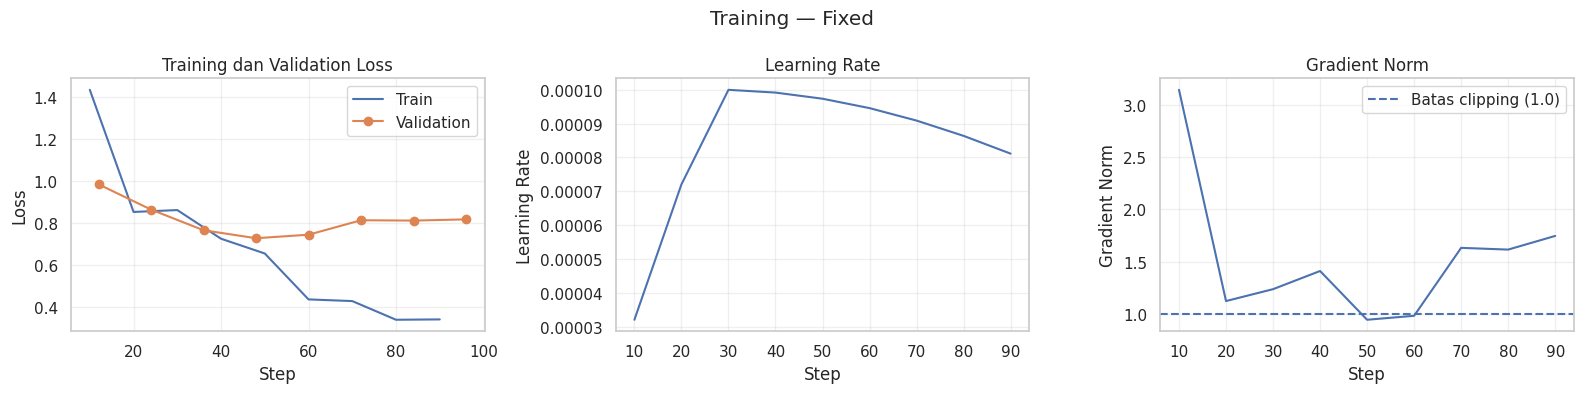

\nRINGKASAN TRAINING — FIXED


,Nilai
Total step,96.0000
Total epoch,1.9741
Loss awal tercatat,1.4334
Loss akhir tercatat,0.3408
Validation terbaik,0.7271
Step validation terbaik,48.0000
Validation terakhir,0.8169
Waktu (menit),4.6903
Samples/detik,13.6990
Total FLOPs,2275374570372096.0000


Periksa keseluruhan kurva dan kualitas jawaban sebelum menyimpulkan.
Hasil tersimpan: /kaggle/working/fixed_ringkasan_training.xlsx


{'log':      loss  grad_norm  learning_rate  epoch  step  eval_loss  eval_runtime  eval_samples_per_second  eval_steps_per_second  train_runtime  train_samples_per_second  train_steps_per_second            total_flos  train_loss
 0  1.4334     3.1450         0.0000 0.2073    10        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN                   NaN         NaN
 1     NaN        NaN            NaN 0.2487    12     0.9837        5.8543                  15.8860                 4.1000            NaN                       NaN                     NaN                   NaN         NaN
 2  0.8522     1.1226         0.0001 0.4145    20        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN                   NaN         NaN
 3     NaN        NaN            NaN 0.4974    24     0.8634        4.8226                  19.2840      

In [33]:
analisis_log_training("fixed", "/kaggle/working/fixed_ringkasan_training.xlsx")

In [34]:
# Perbandingan SFT percobaan pertama dan kedua pada VALIDATION (final test tidak disentuh).
# Angka percobaan pertama dicatat dari output notebook sebelumnya (LR 2e-4, evaluasi per epoch, dropout 0.05).
HASIL_SFT_LAMA = {
    "Best epoch": 1.0,
    "Val loss": 0.7150,
    "Train loss (epoch terbaik)": 0.9618,
    "Val Token F1": 0.7159,
    "Val BERTScore F1": 0.8808,
}
_h = all_results["fixed"]
HASIL_SFT_BARU = {
    "Best epoch": float(_h["best_epoch"]),
    "Val loss": float(_h["val_loss"]),
    "Train loss (epoch terbaik)": None if _h["train_loss"] is None else float(_h["train_loss"]),
    "Val Token F1": float(_h["f1"]),
    "Val BERTScore F1": float(_h["bertscore"]),
}
perbandingan_sft = pd.DataFrame({
    "Run lama": HASIL_SFT_LAMA,
    "Run baru": HASIL_SFT_BARU,
})
perbandingan_sft["Selisih (baru - lama)"] = (
    perbandingan_sft["Run baru"].astype(float) - perbandingan_sft["Run lama"].astype(float)
)
display(perbandingan_sft.round(4))
print(
    "Catatan: perbandingan memakai validation (93 data, 19 grup sumber pada run sebelumnya). "
    "Selisih kecil sebaiknya dianggap noise; lihat CI cluster di Langkah 12b. "
    "Pilih konfigurasi SFT berdasarkan validation saja, lalu kunci sebelum final test."
)

,Run lama,Run baru,Selisih (baru - lama)
Best epoch,1.0000,0.9948,-0.0052
Val loss,0.7150,0.7271,0.0121
Train loss (epoch terbaik),0.9618,0.9679,0.0061
Val Token F1,0.7159,0.6842,-0.0317
Val BERTScore F1,0.8808,0.8691,-0.0117


Catatan: perbandingan memakai validation (93 data, 19 grup sumber pada run sebelumnya). Selisih kecil sebaiknya dianggap noise; lihat CI cluster di Langkah 12b. Pilih konfigurasi SFT berdasarkan validation saja, lalu kunci sebelum final test.


## Langkah 11a: Grafik Training dan Validation Loss

Bagian ini menampilkan kurva training loss dan validation loss dari eksperimen SFT fixed-size chunking.

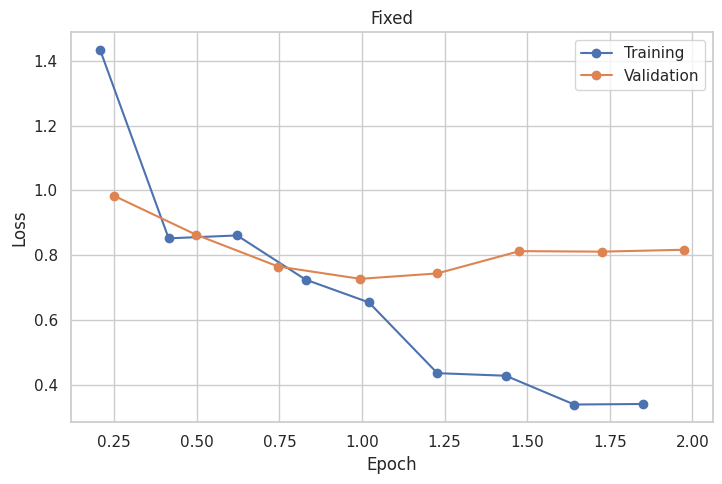

In [35]:
if not all_results:
    raise ValueError("Belum ada hasil training.")

baris = (len(all_results) + 1) // 2
fig, axes = plt.subplots(baris, 2, figsize=(14, 5 * baris), squeeze=False)

for ax, (nama, hasil) in zip(axes.flat, all_results.items()):
    log = hasil["log_df"]
    for kolom, label in [("loss", "Training"), ("eval_loss", "Validation")]:
        if kolom in log and log[kolom].notna().any():
            data = log.dropna(subset=["epoch", kolom]).sort_values("epoch")
            ax.plot(data["epoch"], data[kolom], "o-", label=label)
    ax.set(title=nama.capitalize(), xlabel="Epoch", ylabel="Loss")
    if ax.lines:
        ax.legend()

for ax in axes.flat[len(all_results):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig("/kaggle/working/grafik_loss_per_varian.png", dpi=150)
plt.show()

## Tahap 12: Evaluasi SFT pada Validation

Validation dipakai untuk memeriksa model SFT sebelum DPO dijalankan. Final test tidak dipakai untuk memilih checkpoint ataupun menyetel hyperparameter. Interval kepercayaan bootstrap pada skor validation memberi gambaran ketidakpastian skor, tetapi tidak menggantikan eksperimen dengan beberapa seed.

## Langkah 12: Evaluasi SFT pada Validation

Evaluasi memakai BERTScore F1 sebagai metrik utama dan Token F1 sebagai pendamping. Karena chunking-nya hanya satu konfigurasi, langkah ini melaporkan kualitas SFT dan tidak memilih di antara beberapa metode chunking.

,Mata Pelajaran,Varian Context,Best Epoch,Train Loss (epoch terbaik),Val Loss,Token Precision,Token Recall,Token F1,BERTScore F1
0,PJOK,Fixed,0.9948,0.9679,0.7271,0.7071,0.7409,0.6842,0.8691


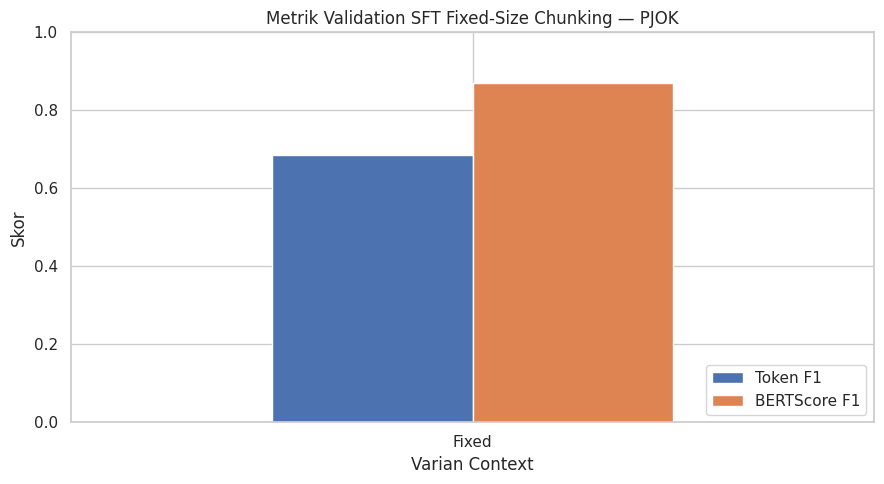

In [36]:
kolom = {
    "best_epoch": "Best Epoch",
    "train_loss": "Train Loss (epoch terbaik)",
    "val_loss": "Val Loss",
    "precision": "Token Precision",
    "recall": "Token Recall",
    "f1": "Token F1",
    "bert_f1": "BERTScore F1",
}

comparison_df = pd.DataFrame.from_dict(all_results, orient="index")
comparison_df = comparison_df[list(kolom)].rename(columns=kolom)
comparison_df.index = comparison_df.index.str.capitalize()
comparison_df = comparison_df.rename_axis("Varian Context").reset_index()
comparison_df.insert(0, "Mata Pelajaran", MATA_PELAJARAN)

display(comparison_df.round(4))

metrics_to_plot = ["Token F1", "BERTScore F1"]
plot_df = comparison_df.set_index("Varian Context")[metrics_to_plot]
ax = plot_df.plot.bar(figsize=(9, 5), rot=0)
ax.set(title=f"Metrik Validation SFT Fixed-Size Chunking — {MATA_PELAJARAN}",
       ylabel="Skor", ylim=(0, 1))
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("/kaggle/working/grafik_perbandingan_varian.png", dpi=150)
plt.show()

## Langkah 12a: Ringkasan BERTScore pada Validation

Bagian ini merangkum BERTScore Precision, Recall, dan F1 pada validation set. Skor ini menunjukkan seberapa dekat makna jawaban model dengan referensi. Skor tersebut belum membuktikan bahwa jawabannya benar secara fakta atau sesuai secara pedagogis.

In [37]:
METODE_CONTEXT = ["fixed"]
N_BOOTSTRAP, BOOTSTRAP_SEED = 10_000, SEED
DETAILS_DIR = Path("/kaggle/working/evaluation_details")
PAPER_BERTSCORE_DIR = Path("/kaggle/working/paper_bertscore_fixed")


def bootstrap_mean_ci(values, rng, n_bootstrap=N_BOOTSTRAP, confidence=0.95):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or not values.size or not np.isfinite(values).all():
        raise ValueError("Skor kosong atau tidak valid.")
    if n_bootstrap < 1 or not 0 < confidence < 1:
        raise ValueError("Pengaturan bootstrap tidak valid.")
    means = np.empty(n_bootstrap)
    for i in range(0, n_bootstrap, 500):
        n = min(500, n_bootstrap - i)
        idx = rng.integers(len(values), size=(n, len(values)))
        means[i:i+n] = values[idx].mean(axis=1)
    alpha = (1 - confidence) / 2
    return tuple(np.quantile(means, [alpha, 1 - alpha]).tolist())


def paired_bootstrap_delta_ci(comparison_values, baseline_values, rng,
                              n_bootstrap=N_BOOTSTRAP, confidence=0.95):
    a, b = [np.asarray(v, dtype=float) for v in (comparison_values, baseline_values)]
    if a.shape != b.shape:
        raise ValueError("Ukuran pasangan skor berbeda.")
    delta = a - b
    low, high = bootstrap_mean_ci(delta, rng, n_bootstrap, confidence)
    return float(delta.mean()), low, high


# ---- Cluster bootstrap per source_group_id ----
# Pertanyaan dari konteks yang sama hampir kembar, jadi baris TIDAK independen.
# Yang diresampling adalah GRUP (bukan baris); rata-rata dihitung ulang dari semua baris
# pada grup yang terambil.
def ambil_grup(ids, sumber=None):
    """Petakan id -> source_group_id dari df_dataset (atau `sumber`)."""
    sumber = df_dataset if sumber is None else sumber
    peta = sumber.set_index(sumber["id"].astype(str))["source_group_id"].astype(str)
    ids = [str(i) for i in ids]
    hilang = [i for i in ids if i not in peta.index]
    if hilang:
        raise ValueError(f"ID tanpa source_group_id: {hilang[:5]}")
    return peta.loc[ids].to_numpy()


def cluster_bootstrap_mean_ci(values, groups, rng, n_bootstrap=N_BOOTSTRAP, confidence=0.95):
    values = np.asarray(values, dtype=float)
    groups = np.asarray(groups).astype(str)
    if values.ndim != 1 or not values.size or not np.isfinite(values).all():
        raise ValueError("Skor kosong atau tidak valid.")
    if len(groups) != len(values):
        raise ValueError("Jumlah grup tidak sama dengan jumlah skor.")
    if n_bootstrap < 1 or not 0 < confidence < 1:
        raise ValueError("Pengaturan bootstrap tidak valid.")
    uniq, inv = np.unique(groups, return_inverse=True)
    n_grup = len(uniq)
    jumlah = np.bincount(inv, minlength=n_grup).astype(float)
    total = np.bincount(inv, weights=values, minlength=n_grup)
    means = np.empty(n_bootstrap)
    for i in range(0, n_bootstrap, 500):
        n = min(500, n_bootstrap - i)
        idx = rng.integers(n_grup, size=(n, n_grup))
        means[i:i+n] = total[idx].sum(axis=1) / jumlah[idx].sum(axis=1)
    alpha = (1 - confidence) / 2
    lo, hi = np.quantile(means, [alpha, 1 - alpha]).tolist()
    return float(lo), float(hi), int(n_grup)


def cluster_paired_bootstrap_delta_ci(comparison_values, baseline_values, groups, rng,
                                      n_bootstrap=N_BOOTSTRAP, confidence=0.95):
    a, b = [np.asarray(v, dtype=float) for v in (comparison_values, baseline_values)]
    if a.shape != b.shape:
        raise ValueError("Ukuran pasangan skor berbeda.")
    delta = a - b
    lo, hi, n_grup = cluster_bootstrap_mean_ci(delta, groups, rng, n_bootstrap, confidence)
    return float(delta.mean()), lo, hi, n_grup


In [38]:
metric_map = {nama: f"bert_{nama.lower()}" for nama in ["Precision", "Recall", "F1"]}
skor = list(metric_map.values())
kolom_wajib = {"id", "candidate", "reference", "candidate_kosong", *skor}
path = DETAILS_DIR / "fixed_validation_details.csv"
data = pd.read_csv(path, dtype={"id": str, "candidate": str, "reference": str}, keep_default_na=False)
kurang = kolom_wajib - set(data.columns)
if kurang:
    raise ValueError(f"Kolom detail validation belum lengkap: {sorted(kurang)}")
if data.empty or data["id"].str.strip().eq("").any() or not data["id"].is_unique:
    raise ValueError("Data validation kosong atau ID tidak valid.")
if data["reference"].str.strip().eq("").any():
    raise ValueError("Reference validation kosong.")
data[skor] = data[skor].apply(pd.to_numeric, errors="raise")
if not np.isfinite(data[skor].to_numpy()).all():
    raise ValueError("Ada skor BERTScore NaN/inf.")
if set(data["id"]) != set(val_split_df["id"].astype(str)):
    raise ValueError("ID detail BERTScore tidak cocok dengan validation split aktif.")
if not all_results["fixed"].get("bertscore_hashcode"):
    raise ValueError("Hash BERTScore tidak tersedia pada hasil fixed.")
detail_frames = {"fixed": data.sort_values("id").reset_index(drop=True)}
print("Validasi detail BERTScore fixed berhasil:", len(data), "baris")

Validasi detail BERTScore fixed berhasil: 93 baris


#### Langkah 12b: Interval Kepercayaan BERTScore F1

Bagian ini menghitung interval bootstrap untuk BERTScore F1 pada validation set fixed-size chunking. Tidak ada perbandingan antara context manual dan fixed chunking.

In [39]:
# CI95 BERTScore F1 validation dengan CLUSTER bootstrap per source_group_id.
# CI per baris (cara lama) tetap ditampilkan sebagai pembanding, karena baris dalam satu grup tidak independen.
_df_fixed = detail_frames["fixed"]
_f = _df_fixed["bert_f1"].to_numpy(dtype=float)
_grup = ambil_grup(_df_fixed["id"])
_lo, _hi, _n_grup = cluster_bootstrap_mean_ci(_f, _grup, np.random.default_rng(BOOTSTRAP_SEED))
_lo_baris, _hi_baris = bootstrap_mean_ci(_f, np.random.default_rng(BOOTSTRAP_SEED))
summary_fixed_bertscore = pd.DataFrame([{
    "Metode": "Fixed-size chunking",
    "BERTScore F1 (rata-rata)": float(_f.mean()),
    "SD": float(_f.std(ddof=1)) if len(_f) > 1 else 0.0,
    "CI95 bawah (cluster)": _lo,
    "CI95 atas (cluster)": _hi,
    "n": len(_f),
    "n_grup": _n_grup,
    "CI95 bawah (per baris, pembanding)": _lo_baris,
    "CI95 atas (per baris, pembanding)": _hi_baris,
}])
display(summary_fixed_bertscore.round(4))
print("CI95 cluster = resampling grup sumber; adalah ketidakpastian rata-rata skor validation, bukan perbandingan metode chunking.")


,Metode,BERTScore F1 (rata-rata),SD,CI95 bawah (cluster),CI95 atas (cluster),n,n_grup,"CI95 bawah (per baris, pembanding)","CI95 atas (per baris, pembanding)"
0,Fixed-size chunking,0.8691,0.1214,0.8263,0.9064,93,19,0.8445,0.8935


CI95 cluster = resampling grup sumber; adalah ketidakpastian rata-rata skor validation, bukan perbandingan metode chunking.


In [40]:
def tabel_skor_per_kelas(details, kolom_skor=("token_f1", "bert_f1"), n_aman=15):
    """Skor rata-rata per kelas + n dan n_grup. Angka per kelas BERISIK bila n kecil;
    jangan dijadikan temuan utama."""
    d = details.copy()
    d["_grup"] = ambil_grup(d["id"])
    g = d.groupby("kelas")
    tabel = g[list(kolom_skor)].mean()
    tabel.insert(0, "n_grup", g["_grup"].nunique())
    tabel.insert(0, "n", g.size())
    tabel["catatan"] = np.where(tabel["n"] < n_aman, "n kecil: angka berisik", "")
    return tabel

_dist = df_dataset["kelas"].value_counts()
print(f"Kelas terbanyak: kelas {_dist.idxmax()} = {_dist.max()} dari {_dist.sum()} data ({_dist.max() / _dist.sum():.1%}). "
      "Distribusi tidak seimbang; skor rata-rata keseluruhan didominasi kelas tersebut.")
print("PERINGATAN: skor per kelas di bawah ini hanya untuk diagnosis. Jumlah data per kelas kecil "
      "(mis. di validation/test ada kelas dengan puluhan atau kurang dari 10 baris), jadi jangan disajikan sebagai temuan utama.")
display(tabel_skor_per_kelas(detail_frames["fixed"]).round(4))

Kelas terbanyak: kelas 3 = 366 dari 962 data (38.0%). Distribusi tidak seimbang; skor rata-rata keseluruhan didominasi kelas tersebut.
PERINGATAN: skor per kelas di bawah ini hanya untuk diagnosis. Jumlah data per kelas kecil (mis. di validation/test ada kelas dengan puluhan atau kurang dari 10 baris), jadi jangan disajikan sebagai temuan utama.


,n,n_grup,token_f1,bert_f1,catatan
kelas,,,,,
1,12,2,0.7614,0.8951,n kecil: angka berisik
2,12,2,0.6667,0.8859,n kecil: angka berisik
3,33,7,0.7162,0.8671,
4,6,2,0.2571,0.7192,n kecil: angka berisik
5,21,5,0.6034,0.8615,
6,9,1,0.9608,0.9372,n kecil: angka berisik


## Langkah 12c: Audit BERTScore pada Satu Jawaban Validation

Cell berikut membedah satu pasangan candidate–reference dari hasil SFT fixed-size chunking.

In [41]:
# Audit lengkap BERTScore untuk PJOK_0023
# Menggunakan konfigurasi dan fungsi yang sudah ada di notebook.

ID_DATA = "PJOK_0023"

PERTANYAAN = (
    "Apakah bagian dari keterampilan yang ada pola gerak manipulatif merupakan"
)

CANDIDATE = (
    "Bagian dari keterampilan dasar yang harus dipelajari anak bersama-sama "
    "dengan keterampilan lokomotor dan nonlokomotor"
)

REFERENCE = "Keterampilan dasar"

try:
    hasil_audit = bedah_dan_simpan_bertscore(
        candidate=CANDIDATE,
        reference=REFERENCE,
        id_data=ID_DATA,
        pertanyaan=PERTANYAAN,
        output_root="/kaggle/working/bertscore_audit_manual",
    )

    print("\nAudit selesai.")
    print("File Excel:", hasil_audit["excel_path"])

except AssertionError as e:
    # Fungsi menyimpan hasil audit sebelum memunculkan AssertionError.
    print("\nAudit tersimpan, tetapi skor manual belum cocok dengan library.")
    print("Detail:", e)
    print(
        "Periksa sheet Ringkasan di folder "
        "/kaggle/working/bertscore_audit_manual/PJOK_0023/"
    )

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Token candidate


,posisi_raw,token,token_id,attention_mask,token_batas_cls_sep,dipakai_bertscore
0,0,[CLS],101,1,True,False
1,1,Ba,21333,1,False,True
2,2,##gian,38531,1,False,True
3,3,dari,10397,1,False,True
4,4,ket,35414,1,False,True
5,5,##era,12015,1,False,True
6,6,##mpi,35407,1,False,True
7,7,##lan,12055,1,False,True
8,8,dasar,44396,1,False,True
9,9,yang,10265,1,False,True


Token reference


,posisi_raw,token,token_id,attention_mask,token_batas_cls_sep,dipakai_bertscore
0,0,[CLS],101,1,True,False
1,1,Ke,47124,1,False,True
2,2,##tera,22833,1,False,True
3,3,##mpi,35407,1,False,True
4,4,##lan,12055,1,False,True
5,5,dasar,44396,1,False,True
6,6,[SEP],102,1,True,False


... (9 outputs left out)

,reference_token,candidate_terbaik,cosine_maksimum
0,R1:Ke,C4:ket,0.7645
1,R2:##tera,C5:##era,0.7778
2,R3:##mpi,C6:##mpi,0.8453
3,R4:##lan,C7:##lan,0.8653
4,R5:dasar,C8:dasar,0.8440


Ringkasan


,0
id,PJOK_0023
pertanyaan,Apakah bagian dari keterampilan yang ada pola ...
candidate,Bagian dari keterampilan dasar yang harus dipe...
reference,Keterampilan dasar
model_bertscore,bert-base-multilingual-cased
layer,9
hash,bert-base-multilingual-cased_L9_no-idf_version...
idf,False
rescale_with_baseline,False
dimensi_embedding,768


Manual cocok dengan library: True
Hasil disimpan: /kaggle/working/bertscore_audit_manual/PJOK_0023/bertscore_audit_lengkap.xlsx

Audit selesai.
File Excel: /kaggle/working/bertscore_audit_manual/PJOK_0023/bertscore_audit_lengkap.xlsx


## Langkah 13: Ekspor Hasil SFT

Hasil SFT, konfigurasi eksperimen, dan log training dikumpulkan dalam satu workbook Excel.

## Tahap 13: Ekspor Hasil SFT

Workbook menyimpan konfigurasi eksperimen, tabel hasil, dan log training. Kalau workbook ini dipakai sebagai lampiran, nama sheet, jumlah baris, versi paket, split yang dipakai, dan metriknya harus cocok dengan file detail dari run yang sama. Tabel dari run yang berbeda tidak boleh digabung.

In [42]:
EXCEL_PATH = "/kaggle/working/hasil_fine_tuning_pjok.xlsx"
# 1. Membuat tabel konfigurasi evaluasi
konfigurasi = pd.DataFrame([
    {"Parameter": "Metrik utama", "Nilai": "BERTScore F1"},
    {"Parameter": "Metrik pendamping", "Nilai": "Token F1"},
    {"Parameter": "Metode context", "Nilai": "Fixed-size chunking: maksimum 400 karakter, overlap 0; TF-IDF train-only untuk memilih satu chunk"},
    {"Parameter": "Loss SFT", "Nilai": "Hanya token jawaban (train_on_responses_only)"},
    {"Parameter": "max_new_tokens", "Nilai": MAX_NEW_TOKENS},
    {"Parameter": "Evaluasi manusia", "Nilai": "Rubrik guru 1–5: ketepatan, relevansi, kejelasan, kesesuaian usia, keamanan"},
    {"Parameter": "Normalisasi Token F1", "Nilai": "Huruf kecil, tanda baca dihapus, spasi dirapikan; tokenisasi whitespace"},
    {"Parameter": "BERTScore", "Nilai": f"model={BERT_MODEL_TYPE}; lang={BERT_LANG}; layer={BERT_NUM_LAYERS}; IDF={BERT_IDF}; rescale={BERT_RESCALE_WITH_BASELINE}"},
])
# 2. Menggabungkan semua hasil ke dalam satu workbook
tabel = {"Perbandingan": comparison_df, "Konfigurasi_Evaluasi": konfigurasi}
tabel.update({f"log_{n}": r["log_df"] for n, r in all_results.items()})
# 3. Menyimpan semua tabel ke Excel
with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
    for nama, data in tabel.items():
        data.to_excel(writer, sheet_name=nama, index=False)
        sheet = writer.sheets[nama]
        for cell in sheet[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="4472C4")
            cell.alignment = Alignment(horizontal="center")
        for col_cells in sheet.columns: # Mengatur lebar kolom otomatis
            lebar = max(len(str(c.value)) if c.value is not None else 0 for c in col_cells)
            sheet.column_dimensions[col_cells[0].column_letter].width = min(max(lebar + 2, 10), 40)
# 4. Memformat header tabel
    sheet = writer.sheets["Perbandingan"] # Menandai nilai BERTScore F1 tertinggi
    k = get_column_letter(comparison_df.columns.get_loc("BERTScore F1") + 1)
    if sheet.max_row > 1:
        sheet.conditional_formatting.add(f"{k}2:{k}{sheet.max_row}", FormulaRule(
            formula=[f"{k}2=MAX(${k}$2:${k}${sheet.max_row})"],
            fill=PatternFill("solid", fgColor="C6EFCE"),
        ))

print("Tersimpan:", EXCEL_PATH)

Tersimpan: /kaggle/working/hasil_fine_tuning_pjok.xlsx


## Langkah 14: Menyimpan dan Me-merge Checkpoint SFT

Checkpoint SFT yang dipilih berdasarkan validation di-merge tanpa training ulang. Hasilnya menjadi titik awal untuk policy dan reference pada DPO.

## Tahap 14: Merge Checkpoint SFT

Adapter SFT dari eksperimen fixed-size chunking dimuat lalu di-merge menjadi satu checkpoint utuh. Model hasil merge yang sama dipakai sebagai dasar untuk policy maupun reference pada DPO.

In [43]:
# 1. Validasi varian context
_ranked = comparison_df.copy()
_ranked["Varian Context (lower)"] = _ranked["Varian Context"].astype(str).str.lower()
if len(_ranked) != 1 or _ranked.loc[0, "Varian Context (lower)"] != "fixed":
    raise ValueError("Metodologi final harus menghasilkan tepat satu varian: fixed.")
BEST_VARIANT_NAME = "fixed"
# 2. Menampilkan skor evaluasi
print("BEST_VARIANT_NAME:", BEST_VARIANT_NAME)
print("Validation BERTScore F1:", round(float(_ranked.loc[0, "BERTScore F1"]), 4))
# 3. Menentukan lokasi adapter dan model hasil merge
SFT_ADAPTER_DIR = os.path.join(SFT_ADAPTER_ROOT, BEST_VARIANT_NAME)
SFT_MERGED_DIR = f"/kaggle/working/sft_best_{BEST_VARIANT_NAME}_merged"

# 4. Memuat dan menggabungkan adapter SFT
def merge_sft_terbaik(adapter_dir, merged_dir):
    """Muat adapter SFT terbaik (disimpan di Langkah 10) lalu merge ke checkpoint utuh."""
    # A. Memastikan adapter tersedia
    assert os.path.isfile(os.path.join(adapter_dir, "adapter_config.json")), (
        f"Adapter {adapter_dir} belum ada. Jalankan percobaan varian ini di Langkah 10 dulu."
    )
    # B. Memuat model dan tokenizer
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=adapter_dir, max_seq_length=MAX_SEQ_LENGTH,
        dtype=DTYPE, load_in_4bit=LOAD_IN_4BIT,
    )
    # C. Menyimpan model hasil merge
    model.save_pretrained_merged(merged_dir, tokenizer, save_method="merged_16bit")
    print(f"SFT model (merged, utuh) tersimpan di: {merged_dir}")
    return model, tokenizer
    
# 5. Menjalankan proses merge
_sft_model_tmp, _sft_tokenizer_tmp = merge_sft_terbaik(SFT_ADAPTER_DIR, SFT_MERGED_DIR)
del _sft_model_tmp, _sft_tokenizer_tmp
gc.collect()
torch.cuda.empty_cache()

BEST_VARIANT_NAME: fixed
Validation BERTScore F1: 0.8691
==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/sft_best_fixed_merged/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


... (3 outputs left out)

Unsloth: Preparing safetensor model files: 100%|██████████| 1/1 [00:06<00:00,  6.98s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:13<00:00, 13.26s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/sft_best_fixed_merged`
SFT model (merged, utuh) tersimpan di: /kaggle/working/sft_best_fixed_merged


## Langkah 15: Membuat Kandidat Jawaban untuk Dinilai Guru

Alurnya: input prompt, lalu model SFT, lalu dua jawaban, lalu dinilai guru.

Cell ini memuat model SFT hasil merge (Langkah 14) dalam mode inference dan membuat dua jawaban berbeda untuk tiap prompt. Jawaban pertama dibuat secara stabil (greedy), jawaban kedua dengan sedikit variasi lewat sampling, supaya ada perbedaan yang bisa dinilai guru. Hasilnya diekspor ke template Excel yang siap diisi guru, dengan kolom status berisi pilihan Yes/No.

## Tahap 15: Kandidat Jawaban untuk Anotasi Guru

Model SFT membuat kandidat jawaban untuk pertanyaan dari train split. Jawaban yang identik dibuang karena tidak memberi kontras yang berguna. Setelah guru menilai, jawaban berstatus `Yes` menjadi `chosen` dan yang berstatus `No` menjadi `rejected` untuk pertanyaan yang sama.

Kandidat ini berasal dari data train, sehingga bisa mengandung efek hafalan dari proses SFT. Hal ini saya catat sebagai keterbatasan desain anotasi, dan hasilnya tidak boleh dianggap sebagai evaluasi generalisasi yang independen.

In [44]:
# LANGKAH 15 — GENERATE KANDIDAT PREFERENSI UNTUK DPO
# Tujuan:
# 1. Memuat model SFT hasil merge.
# 2. Menghasilkan dua kandidat jawaban untuk setiap pertanyaan.
# 3. Mengulang sampling jika kedua jawaban identik.
# 4. Melewati pertanyaan yang tetap menghasilkan jawaban identik.
# 5. Menyimpan kandidat dalam template Excel untuk penilaian guru.
# 6. Menyiapkan data preferensi untuk tahap pemrosesan DPO.
# Format Excel:
# id | kelas | pertanyaan | context | jawaban | status
# Guru mengisi kolom status menggunakan:
# - Yes: jawaban diterima/layak.
# - No : jawaban tidak diterima/tidak layak.
# Catatan:
# - Status Yes/No harus mengikuti rubrik penilaian yang disepakati.
# - Pasangan DPO yang jelas umumnya terdiri dari satu Yes dan satu No.
# - Dua jawaban berbeda belum tentu memiliki kualitas yang berbeda.

from unsloth import FastLanguageModel
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.utils import get_column_letter

# Parameter sampling kandidat; dicatat ke config_eksperimen.json (lihat di bawah) untuk reproduksibilitas.
KANDIDAT_TEMPERATURE_AWAL = 0.8   # temperature percobaan sampling pertama
KANDIDAT_TEMPERATURE_NAIK = 0.2   # kenaikan temperature tiap pengulangan jika jawaban masih identik
KANDIDAT_TOP_P = 0.9
KANDIDAT_MAX_RETRY = 3

# 1. MEMUAT MODEL SFT UNTUK INFERENCE
gen_model, gen_tokenizer = FastLanguageModel.from_pretrained(
    model_name=SFT_MERGED_DIR,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=DTYPE,
    load_in_4bit=LOAD_IN_4BIT,
)

# Mengaktifkan mode inference Unsloth.
FastLanguageModel.for_inference(gen_model)


# 2. FORMAT PROMPT
def format_dpo_prompt(context, pertanyaan):
    """
    Menggunakan format prompt yang sama dengan fungsi utama
    format_prompt() pada tahap SFT/inference.
    """
    return format_prompt(context, pertanyaan)

# 3. GENERATE SATU KANDIDAT JAWABAN
def generate_kandidat_jawaban(
    context,
    pertanyaan,
    do_sample=False,
    temperature=0.7,
    max_new_tokens=MAX_NEW_TOKENS,
):
    """
    Menghasilkan satu jawaban dari model SFT.

    Parameter:
    - context: konteks materi yang diberikan ke model.
    - pertanyaan: pertanyaan PJOK.
    - do_sample: False untuk greedy decoding, True untuk sampling.
    - temperature: tingkat variasi saat sampling.
    - max_new_tokens: batas maksimum token jawaban.

    Return:
    - Teks jawaban yang sudah dibersihkan dari spasi di awal/akhir.
    """

    prompt = format_dpo_prompt(context, pertanyaan)

    inputs = gen_tokenizer(
        prompt,
        return_tensors="pt",
    ).to(gen_model.device)

    # Parameter generasi dasar.
    generation_kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": do_sample,
        "pad_token_id": gen_tokenizer.eos_token_id,
    }

    # Parameter sampling hanya digunakan ketika do_sample=True.
    if do_sample:
        generation_kwargs.update({
            "temperature": temperature,
            "top_p": KANDIDAT_TOP_P,
        })

    with torch.inference_mode():
        output_ids = gen_model.generate(
            **inputs,
            **generation_kwargs,
        )

    # Mengambil token hasil generasi saja, tanpa mengikutkan prompt.
    prompt_length = inputs["input_ids"].shape[1]
    generated_ids = output_ids[0][prompt_length:]

    # Mengubah token menjadi teks.
    jawaban = gen_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
    )

    return jawaban.strip()

# 4. GENERATE DUA JAWABAN YANG BERBEDA
def generate_dua_jawaban_berbeda(
    context,
    pertanyaan,
    max_new_tokens=MAX_NEW_TOKENS,
    max_retry=KANDIDAT_MAX_RETRY,
):
    """
    Menghasilkan dua kandidat jawaban untuk satu pertanyaan.

    Alur:
    1. Jawaban pertama dihasilkan dengan greedy decoding.
    2. Jawaban kedua dihasilkan dengan sampling.
    3. Jika kedua jawaban identik setelah normalisasi,
       sampling diulang hingga max_retry kali.
    4. Jika tetap identik, pasangan ditandai untuk dilewati.

    Return:
    - jawaban_1
    - jawaban_2
    - identik: True jika keduanya masih identik.
    """

    # Jawaban pertama menggunakan greedy decoding.
    jawaban_1 = generate_kandidat_jawaban(
        context=context,
        pertanyaan=pertanyaan,
        do_sample=False,
        max_new_tokens=max_new_tokens,
    )

    jawaban_2 = jawaban_1
    temperature = KANDIDAT_TEMPERATURE_AWAL
    tries = 0

    # Ulangi sampling jika jawaban masih identik.
    while (
        normalize_answer(jawaban_2) == normalize_answer(jawaban_1)
        and tries < max_retry
    ):
        jawaban_2 = generate_kandidat_jawaban(
            context=context,
            pertanyaan=pertanyaan,
            do_sample=True,
            temperature=temperature,
            max_new_tokens=max_new_tokens,
        )

        temperature += KANDIDAT_TEMPERATURE_NAIK
        tries += 1

    identik = (
        normalize_answer(jawaban_1)
        == normalize_answer(jawaban_2)
    )

    return jawaban_1, jawaban_2, identik


# 5. MENENTUKAN JUMLAH PROMPT UNTUK PENILAIAN GURU
N_PROMPT_UNTUK_GURU = 50

# Mengambil kolom konteks berdasarkan varian yang ditetapkan.
context_col = CONTEXT_VARIANTS[BEST_VARIANT_NAME]

# Mengambil sampel dari data training.
sample_prompts = train_split_df.sample(
    n=min(N_PROMPT_UNTUK_GURU, len(train_split_df)),
    random_state=SEED,
)

# Memastikan sampel tidak mengambil ID dari final test.
assert not (
    set(sample_prompts["id"]) & set(id_test)
), (
    "KEBOCORAN: candidate preference mengambil ID final test."
)

# Seed disetel TEPAT sebelum sampling agar urutan sampling dapat diulang pada GPU dan versi yang sama.
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Simpan parameter sampling ke config_eksperimen.json (digabung dengan isi yang sudah ada).
_CONFIG_EKSPERIMEN_PATH = "/kaggle/working/config_eksperimen.json"
_config_eksperimen = {}
if os.path.isfile(_CONFIG_EKSPERIMEN_PATH):
    with open(_CONFIG_EKSPERIMEN_PATH, encoding="utf-8") as _f:
        _config_eksperimen = json.load(_f)
_config_eksperimen["kandidat_preferensi"] = {
    "seed": SEED,
    "kandidat_1": "greedy (do_sample=False)",
    "kandidat_2": "sampling (do_sample=True)",
    "temperature_awal": KANDIDAT_TEMPERATURE_AWAL,
    "temperature_naik_per_retry": KANDIDAT_TEMPERATURE_NAIK,
    "top_p": KANDIDAT_TOP_P,
    "max_retry": KANDIDAT_MAX_RETRY,
    "max_new_tokens": MAX_NEW_TOKENS,
    "n_prompt_untuk_guru": N_PROMPT_UNTUK_GURU,
}
with open(_CONFIG_EKSPERIMEN_PATH, "w", encoding="utf-8") as _f:
    json.dump(_config_eksperimen, _f, indent=2, ensure_ascii=False)
print("Parameter sampling kandidat dicatat ke:", _CONFIG_EKSPERIMEN_PATH)

# 6. GENERATE KANDIDAT DAN MENYUSUN DATA FEEDBACK
rows_kandidat = []
n_identik = 0
n_jawaban_kosong = 0

for _, row in sample_prompts.iterrows():

    context = row[context_col]
    pertanyaan = row["pertanyaan"]

    # Menghasilkan dua kandidat jawaban.
    jawaban_1, jawaban_2, identik = generate_dua_jawaban_berbeda(
        context=context,
        pertanyaan=pertanyaan,
        max_new_tokens=MAX_NEW_TOKENS,
    )

    # Lewati pasangan yang tetap identik.
    if identik:
        n_identik += 1
        continue

    # Lewati kandidat yang kosong setelah dibersihkan.
    if not jawaban_1.strip() or not jawaban_2.strip():
        n_jawaban_kosong += 1
        continue

    # Menyimpan kedua jawaban sebagai dua baris.
    for jawaban in (jawaban_1, jawaban_2):
        rows_kandidat.append({
            "id": row["id"],
            "kelas": row["kelas"],
            "pertanyaan": pertanyaan,
            "context": context,
            "jawaban": jawaban,
            "status": "",
        })


# 7. MEMBUAT DATAFRAME KANDIDAT
kolom_kandidat = [
    "id",
    "kelas",
    "pertanyaan",
    "context",
    "jawaban",
    "status",
]

df_kandidat = pd.DataFrame(
    rows_kandidat,
    columns=kolom_kandidat,
)

n_prompt_valid = df_kandidat["id"].nunique()
n_baris_kandidat = len(df_kandidat)

print("\n" + "=" * 60)
print("RINGKASAN GENERASI KANDIDAT PREFERENSI")
print("=" * 60)

print(f"Jumlah prompt yang disampling : {len(sample_prompts)}")
print(f"Pasangan identik yang dilewati: {n_identik}")
print(f"Pasangan dengan jawaban kosong: {n_jawaban_kosong}")
print(f"Pertanyaan dengan kandidat valid: {n_prompt_valid}")
print(f"Jumlah baris kandidat         : {n_baris_kandidat}")

# 8. ESTIMASI KASAR JUMLAH PASANGAN PREFERENSI
# Estimasi ini hanya perkiraan berdasarkan yield historis.
# Hasil aktual bergantung pada penilaian guru.
#
# Pasangan preferensi yang jelas umumnya memiliki:
# - satu jawaban berstatus Yes;
# - satu jawaban berstatus No.
#
# Pasangan Yes/Yes atau No/No tidak menghasilkan preferensi
# biner yang jelas dalam skema ini.

YIELD_PASANGAN_HISTORIS = 0.67

estimasi_pasangan = int(
    n_prompt_valid * YIELD_PASANGAN_HISTORIS
)

print(
    f"\nEstimasi kasar pasangan preferensi: "
    f"~{estimasi_pasangan}"
)

print(
    f"Asumsi yield historis: "
    f"{YIELD_PASANGAN_HISTORIS:.0%}"
)

print(
    "Catatan: estimasi bukan jaminan. "
    "Jumlah pasangan aktual baru diketahui setelah guru menilai."
)

# 9. MENYIMPAN TEMPLATE EXCEL UNTUK GURU
TEMPLATE_PATH = "/kaggle/working/template_feedback_guru.xlsx"

# Simpan data kandidat ke Excel.
df_kandidat.to_excel(
    TEMPLATE_PATH,
    sheet_name="Feedback",
    index=False,
)


# 10. MENAMBAHKAN DROPDOWN YES/NO PADA KOLOM STATUS
wb_tmpl = openpyxl.load_workbook(TEMPLATE_PATH)
ws_tmpl = wb_tmpl["Feedback"]

# Dropdown status: Yes atau No.
dv = DataValidation(
    type="list",
    formula1='"Yes,No"',
    allow_blank=True,
)

dv.error = "Pilih status Yes atau No."
dv.errorTitle = "Status tidak valid"
dv.prompt = "Pilih Yes jika jawaban diterima, atau No jika ditolak."
dv.promptTitle = "Penilaian guru"
dv.showErrorMessage = True
dv.showInputMessage = True

ws_tmpl.add_data_validation(dv)

# Cari posisi kolom status secara dinamis.
header = [
    cell.value
    for cell in ws_tmpl[1]
]

status_col = header.index("status") + 1
status_letter = get_column_letter(status_col)

# Terapkan dropdown ke seluruh baris data.
if ws_tmpl.max_row >= 2:
    dv.add(
        f"{status_letter}2:{status_letter}{ws_tmpl.max_row}"
    )

# Membekukan header agar tetap terlihat saat menggulir.
ws_tmpl.freeze_panes = "A2"

# Mengaktifkan filter pada header.
ws_tmpl.auto_filter.ref = ws_tmpl.dimensions

# Merapikan lebar kolom agar template lebih mudah dibaca.
for col_cells in ws_tmpl.columns:
    max_length = max(
        len(str(cell.value)) if cell.value is not None else 0
        for cell in col_cells
    )

    column_letter = col_cells[0].column_letter

    ws_tmpl.column_dimensions[column_letter].width = min(
        max(max_length + 2, 12),
        45,
    )

# Simpan kembali workbook.
wb_tmpl.save(TEMPLATE_PATH)

# 11. MEMBERSIHKAN MEMORI GPU
del gen_model

gc.collect()
torch.cuda.empty_cache()

# 12. RINGKASAN AKHIR
print("\n" + "=" * 60)
print("TEMPLATE FEEDBACK GURU BERHASIL DISIAPKAN")
print("=" * 60)

print(f"File Excel       : {TEMPLATE_PATH}")
print(f"Jumlah pertanyaan: {n_prompt_valid}")
print(f"Jumlah baris     : {n_baris_kandidat}")
print("\nKolom:")
print(", ".join(kolom_kandidat))

print("\nInstruksi:")
print("1. Unduh file template_feedback_guru.xlsx dari Kaggle.")
print("2. Kirim template kepada guru untuk dinilai.")
print("3. Guru mengisi kolom 'status' menggunakan Yes atau No.")
print("4. Simpan file yang sudah dinilai.")
print("5. Unggah kembali file tersebut ke Kaggle.")
print("6. Jalankan tahap pemrosesan feedback untuk membentuk pasangan DPO.")

print("\nContoh data kandidat:")
display(df_kandidat.head(6))

==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene


RINGKASAN GENERASI KANDIDAT PREFERENSI
Jumlah prompt yang disampling : 50
Pasangan identik yang dilewati: 11
Pasangan dengan jawaban kosong: 0
Pertanyaan dengan kandidat valid: 39
Jumlah baris kandidat         : 78

Estimasi kasar pasangan preferensi: ~26
Asumsi yield historis: 67%
Catatan: estimasi bukan jaminan. Jumlah pasangan aktual baru diketahui setelah guru menilai.

TEMPLATE FEEDBACK GURU BERHASIL DISIAPKAN
File Excel       : /kaggle/working/template_feedback_guru.xlsx
Jumlah pertanyaan: 39
Jumlah baris     : 78

Kolom:
id, kelas, pertanyaan, context, jawaban, status

Instruksi:
1. Unduh file template_feedback_guru.xlsx dari Kaggle.
2. Kirim template kepada guru untuk dinilai.
3. Guru mengisi kolom 'status' menggunakan Yes atau No.
4. Simpan file yang sudah dinilai.
5. Unggah kembali file tersebut ke Kaggle.
6. Jalankan tahap pemrosesan feedback untuk membentuk pasangan DPO.

Contoh data kandidat:


,id,kelas,pertanyaan,context,jawaban,status
0,PJOK_0858,6,Apa manfaat dari renang gaya punggung,"Jika dilakukan dengan rutin, renang gaya pungg...",menambah tinggi badan dan menjaga kelenturan t...,
1,PJOK_0858,6,Apa manfaat dari renang gaya punggung,"Jika dilakukan dengan rutin, renang gaya pungg...",menambah tinggi badan dan menjaga kelenturanny...,
2,PJOK_0356,3,Cara melatih gerakan kaki adalah,Latihan jalan di tempat dapat melatih gerakan ...,Jalan di tempat,
3,PJOK_0356,3,Cara melatih gerakan kaki adalah,Latihan jalan di tempat dapat melatih gerakan ...,Melakukan jalan di tempat,
4,PJOK_0930,6,Apa penyebab dari penyakit urethritis,Urethritis adalah penyakit infeksi yang menyeb...,Bakteri yang masuk ke saluran uretra,
5,PJOK_0930,6,Apa penyebab dari penyakit urethritis,Urethritis adalah penyakit infeksi yang menyeb...,Bakteri,


### Memeriksa Direktori dan File di Kaggle

Cell berikut menampilkan isi `/kaggle/working/` (folder kerja untuk hasil notebook), isi `/kaggle/working/saved_models/` kalau folder itu ada, dan isi `/kaggle/input/` (dataset input). Tujuannya memastikan lokasi model, hasil eksperimen, dan dataset sudah benar sebelum lanjut, dan menangkap kesalahan path lebih awal.

Folder `saved_models/` tidak dibuat otomatis. Kalau belum ada, periksa apakah model disimpan di folder lain, atau buat foldernya bila memang diperlukan.

In [45]:
!echo "--- isi /kaggle/working/ ---"
!ls -la /kaggle/working/
!echo "--- isi /kaggle/working/saved_models/ (kalau ada) ---"
!ls -la /kaggle/working/saved_models/ 2>/dev/null || echo "folder tidak ada"
!echo "--- isi /kaggle/input/ ---"
!ls -la /kaggle/input/


--- isi /kaggle/working/ ---
total 352
drwxr-xr-x 12 root root   4096 Oct 25 07:48 .
drwxr-xr-x  5 root root   4096 Oct 25 07:34 ..
drwxr-xr-x  2 root root   4096 Oct 25 07:39 arsip_sft_lama
drwxr-xr-x  3 root root   4096 Oct 25 07:46 bertscore_audit_manual
-rw-r--r--  1 root root 114511 Oct 25 07:39 dataset_pjok_bersih.xlsx
drwxr-xr-x  2 root root   4096 Oct 25 07:39 dataset_splits
-rw-r--r--  1 root root    507 Oct 25 07:39 diagnostik_chunk.csv
-rw-r--r--  1 root root    194 Oct 25 07:39 environment_versions.json
drwxr-xr-x  2 root root   4096 Oct 25 07:46 evaluation_details
drwxr-xr-x  3 root root   4096 Oct 25 07:40 fine_tune_runs
-rw-r--r--  1 root root   8180 Oct 25 07:46 fixed_ringkasan_training.xlsx
-rw-r--r--  1 root root   1632 Oct 25 07:44 fixed_training_log.csv
-rw-r--r--  1 root root  59095 Oct 25 07:46 grafik_loss_per_varian.png
-rw-r--r--  1 root root  36979 Oct 25 07:46 grafik_perbandingan_varian.png
-rw-r--r--  1 root root   8659 Oct 25 07:46 hasil_fine_tuning_pjok.xls

In [46]:
print("--- isi adapter SFT terbaik ---")
!ls -la "{SFT_ADAPTER_DIR}"
print("--- isi merged SFT terbaik ---")
!ls -la "{SFT_MERGED_DIR}"


--- isi adapter SFT terbaik ---
total 83376
drwxr-xr-x 2 root root     4096 Oct 25 07:44 .
drwxr-xr-x 3 root root     4096 Oct 25 07:44 ..
-rw-r--r-- 1 root root     1315 Oct 25 07:44 adapter_config.json
-rw------- 1 root root 73911112 Oct 25 07:44 adapter_model.safetensors
-rw-r--r-- 1 root root     2507 Oct 25 07:44 chat_template.jinja
-rw-r--r-- 1 root root     5268 Oct 25 07:44 README.md
-rw-r--r-- 1 root root     4412 Oct 25 07:44 tokenizer_config.json
-rw-r--r-- 1 root root 11422166 Oct 25 07:44 tokenizer.json
-rw-r--r-- 1 root root     6097 Oct 25 07:44 training_args.bin
--- isi merged SFT terbaik ---
total 3026300
drwxr-xr-x  3 root root       4096 Oct 25 07:47 .
drwxr-xr-x 12 root root       4096 Oct 25 07:48 ..
drwxr-xr-x  3 root root       4096 Oct 25 07:46 .cache
-rw-r--r--  1 root root       2507 Oct 25 07:46 chat_template.jinja
-rw-r--r--  1 root root       1404 Oct 25 07:46 config.json
-rw-r--r--  1 root root        265 Oct 25 07:46 generation_config.json
-rw-r--r--  1 r

## Langkah 15b (Opsional): Memuat Adapter LoRA untuk Inference

Bagian ini dipakai untuk memuat kembali model hasil SFT beserta adapter LoRA yang sudah disimpan, supaya bisa dipakai untuk inference tanpa fine-tuning ulang. Di sini model hanya dimuat ke memori. Tidak ada bobot yang diperbarui dan tidak ada training.

Secara default pemuatan dimatikan (`RUN_OPTIONAL_SFT_ADAPTER_LOAD = False`) supaya VRAM tidak terpakai saat eksperimen utama berjalan. Ubah menjadi `True` hanya kalau model SFT yang tersimpan perlu dipakai lagi, misalnya untuk uji jawaban chatbot.

`MODEL_DIR` harus menunjuk ke folder adapter yang berisi:

| File | Fungsi |
|---|---|
| `adapter_config.json` | Konfigurasi adapter, termasuk nama model dasar yang dipakai. |
| `adapter_model.safetensors` atau `adapter_model.bin` | Bobot adapter LoRA hasil fine-tuning. |
| File tokenizer | Mengubah teks menjadi token dan sebaliknya. |

Di sesi Kaggle yang sama, `SFT_ADAPTER_DIR` bisa langsung dipakai kalau foldernya masih ada. Di sesi baru, adapter perlu diunggah sebagai Kaggle Dataset, lalu `MODEL_DIR` diarahkan ke folder adapter di `/kaggle/input/`.

Kode ini hanya untuk adapter PEFT. Kalau yang tersimpan adalah model hasil merge (`save_pretrained_merged(..., save_method="merged_16bit")`), pemeriksaan `adapter_config.json` tidak akan lolos, dan modelnya harus dimuat sebagai model utuh dengan `AutoModelForCausalLM.from_pretrained()`.

Urutan prosesnya:

1. Memeriksa bahwa folder dan file adapter ada.
2. Membaca konfigurasi adapter dengan `PeftConfig.from_pretrained()` untuk mengetahui model dasarnya.
3. Memuat model dasar dalam 4-bit lewat `BitsAndBytesConfig`, memakai `bfloat16` kalau GPU mendukung dan `float16` kalau tidak.
4. Memasang adapter dengan `PeftModel.from_pretrained()`. Parameter `is_trainable=False` berarti adapter hanya dipakai untuk inference.
5. Memuat tokenizer dari folder adapter. Kalau file tokenizernya tidak ada di sana, tokenizer dimuat dari model dasar.
6. Memanggil `sft_adapter_model.eval()` untuk mengubah model ke mode evaluasi.

Perbedaan inference dan fine-tuning secara singkat: pada inference model hanya menghasilkan jawaban dan bobotnya tidak berubah, sedangkan pada fine-tuning loss dihitung dan bobot yang dilatih diperbarui lewat `trainer.train()`.

Urutan kerja penelitian ini: SFT dengan dataset PJOK, simpan adapter dan tokenizer, muat ulang adapter di bagian ini bila perlu, cek kualitas jawaban SFT, kumpulkan preferensi guru, jalankan DPO di tahap terpisah, lalu evaluasi model akhir dengan metrik yang sudah ditentukan.

Jadi bagian ini hanya memuat model untuk inference, bukan melatih ulang. Untuk training atau DPO, gunakan cell training yang sesuai.

In [47]:
# LOAD SAVED LoRA ADAPTER TANPA TRAINING ULANG
# Default False: jangan memuat model tambahan saat menjalankan notebook eksperimen dari awal.
# Untuk sesi inference terpisah, ubah menjadi True lalu jalankan sel ini.
RUN_OPTIONAL_SFT_ADAPTER_LOAD = False

if RUN_OPTIONAL_SFT_ADAPTER_LOAD:

    MODEL_DIR = SFT_ADAPTER_DIR
    import os
    import torch
    from transformers import (
        AutoModelForCausalLM,
        AutoTokenizer,
        BitsAndBytesConfig,
    )
    from peft import PeftConfig, PeftModel

    assert os.path.isdir(MODEL_DIR), (
        f"Folder model tidak ditemukan: {MODEL_DIR}\n"
        "Kalau ini session Kaggle baru, ubah MODEL_DIR ke /kaggle/input/..."
    )

    assert os.path.isfile(
        os.path.join(MODEL_DIR, "adapter_config.json")
    ), "adapter_config.json tidak ditemukan."

    assert (
        os.path.isfile(os.path.join(MODEL_DIR, "adapter_model.safetensors"))
        or os.path.isfile(os.path.join(MODEL_DIR, "adapter_model.bin"))
    ), "Bobot adapter tidak ditemukan."

    # 1. Baca config adapter untuk mengetahui base model.
    peft_config = PeftConfig.from_pretrained(MODEL_DIR)

    print("Adapter dir :", MODEL_DIR)
    print("Base model  :", peft_config.base_model_name_or_path)

    # 2. Load base model dalam 4-bit, sama dengan pendekatan QLoRA training.
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=(
            torch.bfloat16
            if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
            else torch.float16
        ),
    )

    base_model = AutoModelForCausalLM.from_pretrained(
        peft_config.base_model_name_or_path,
        quantization_config=bnb_config,
        device_map="auto",
    )

    # 3. Pasang adapter hasil fine-tuning.
    sft_adapter_model = PeftModel.from_pretrained(
        base_model,
        MODEL_DIR,
        is_trainable=False,
    )

    # 4. Load tokenizer yang sudah kita simpan.
    sft_adapter_tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)

    sft_adapter_model.eval()   # nama sengaja dibedakan agar tidak menimpa `model`/`tokenizer` global

    print("Model + LoRA adapter berhasil diload.")
    print("Tidak ada trainer.train() pada tahap ini.")
else:
    print(
        "Pemuatan adapter opsional dilewati agar tidak menambah penggunaan VRAM. "
        "Set RUN_OPTIONAL_SFT_ADAPTER_LOAD=True hanya saat perlu inference terpisah."
    )


Pemuatan adapter opsional dilewati agar tidak menambah penggunaan VRAM. Set RUN_OPTIONAL_SFT_ADAPTER_LOAD=True hanya saat perlu inference terpisah.


## Langkah 16: Memvalidasi Feedback Guru dan Menyusun Dataset Preferensi DPO

### 1. Tujuan

Tahap ini mengubah penilaian guru menjadi dataset preferensi untuk DPO. Di tahap sebelumnya model SFT membuat beberapa kandidat jawaban untuk tiap pertanyaan, lalu guru menilainya lewat kolom `status` di file Excel. Jawaban berstatus `Yes` dipakai sebagai `chosen`, dan jawaban berstatus `No` sebagai `rejected`.

Dari penilaian itu dibentuk pasangan dengan format berikut:

- **Prompt:** context pembelajaran dan pertanyaan yang diberikan ke chatbot.
- **Chosen:** jawaban yang dipilih guru.
- **Rejected:** jawaban alternatif yang tidak dipilih guru.

Cell di bagian ini hanya menyiapkan dan memvalidasi dataset. Training DPO belum dijalankan dan bobot model belum berubah.

### 2. Membaca File Feedback Guru

File feedback ada di `/kaggle/input/datasets/erycaa/dataset-guru-v1/template_feedback_guru.xlsx`. File ini adalah template yang sudah diisi guru. Kodenya bisa membaca CSV (`pd.read_csv()`) maupun Excel (`pd.read_excel()` dengan sheet `Feedback`).

Kolom yang wajib ada:

| Kolom | Kegunaan |
|---|---|
| `id` | ID pertanyaan dari dataset sumber, untuk menelusuri asal data dan mencegah kebocoran data. |
| `pertanyaan` | Pertanyaan yang dinilai guru. |
| `jawaban` | Kandidat jawaban chatbot yang dinilai. |
| `status` | Penilaian guru, `Yes` atau `No`. |

Kalau ada kolom wajib yang hilang, proses dihentikan oleh `assert`. Kolom `id` diubah menjadi teks dan dibersihkan dari spasi, dan kolom `status` dijadikan huruf kecil supaya `Yes`, `YES`, dan ` yes ` dianggap sama. Hanya baris berstatus `yes` atau `no` yang dipertahankan. Baris yang belum dinilai tidak dipakai.

ID yang tidak cocok dengan dataset aktif dikeluarkan dari proses DPO dan dicatat di file audit. Feedback yang berasal dari validation atau final test membuat proses berhenti.

### 3. Mencegah Kebocoran Data

Data preferensi untuk DPO harus hanya berasal dari train split. Ada empat pemeriksaan:

- **ID dikenal.** Setiap ID feedback harus ada di `df_dataset`. ID yang tidak dikenal tidak dipakai dan disimpan ke `/kaggle/working/feedback_id_tidak_dikenal_audit.csv`.
- **Bukan dari validation.** Feedback dengan ID di `id_val` ditolak, supaya validation tetap bersih untuk evaluasi dan pemilihan model.
- **Bukan dari final test.** Feedback dengan ID di `id_test` ditolak, supaya final test tetap terkunci sampai evaluasi akhir.
- **Semuanya dari train.** Pemeriksaan `feedback_ids <= id_train` memastikan seluruh ID feedback termasuk train split.

Pemeriksaan ini bergantung pada `df_dataset`, `id_train`, `id_val`, `id_test`, dan `train_split_df`. Jadi pembentukan split dan pemetaan ID tidak boleh berubah di tengah eksperimen.

### 4. Membentuk Pasangan Preferensi

Fungsi `build_preference_dataset()` mengubah feedback guru menjadi pasangan data untuk DPO. Masukannya `df_fb` (feedback yang sudah difilter `Yes`/`No`), `context_col` (kolom context yang dipakai), dan `df_context_lookup` (data train sebagai rujukan resmi).

Prosesnya:

1. **Lookup berdasarkan ID.** Data rujukan diindeks dengan `id` dan `verify_integrity=True` supaya tidak ada ID ganda. Pertanyaan dan context diambil dari data train, bukan dari teks di file Excel yang mungkin sudah diedit.
2. **Pengelompokan per pertanyaan.** Untuk tiap `id`, dikumpulkan daftar jawaban `yes` dan `no`. Jawaban kosong dibuang, spasi dirapikan, dan duplikat dihapus. Pertanyaan yang hanya punya jawaban `Yes` atau hanya `No` tidak menghasilkan pasangan.
3. **Pembuatan prompt.** Context dan pertanyaan diformat dengan `format_dpo_prompt(context, pertanyaan)`, sama dengan format yang dipakai saat training DPO, supaya masukan model konsisten.
4. **Kombinasi chosen dan rejected.** Setiap jawaban `Yes` dipasangkan dengan setiap jawaban `No` pada pertanyaan yang sama. Misalnya 2 jawaban `Yes` dan 3 jawaban `No` bisa menghasilkan 2 × 3 = 6 pasangan. Pasangan yang jawabannya identik setelah `normalize_answer()` tidak dipakai, karena tidak punya perbedaan yang berarti.

Kolom pada setiap pasangan:

| Kolom | Fungsi |
|---|---|
| `preference_group` | ID pertanyaan, untuk mengelompokkan pasangan dari pertanyaan yang sama. |
| `id` | ID sumber, untuk menelusuri asal data. |
| `pertanyaan` | Pertanyaan dari train split. |
| `prompt` | Prompt lengkap dari context dan pertanyaan. |
| `chosen` | Jawaban pilihan guru, dengan penanda akhir `<|im_end|>`. |
| `rejected` | Jawaban yang tidak dipilih guru, dengan penanda akhir `<|im_end|>`. |

Penanda `<|im_end|>` ditambahkan supaya format jawaban sesuai dengan format percakapan model. Penanda ini harus konsisten dengan tokenizer dan template percakapan saat training DPO.

### 5. Memeriksa Jumlah Grup Preferensi

Setelah semua pasangan terbentuk, dihitung jumlah grup pertanyaan unik dengan `preference_group.nunique()`. Ada dua batas:

- `MIN_GRUP_PREFERENSI_TEKNIS = 6`: batas minimum supaya eksperimen bisa jalan. Di bawah ini proses dihentikan.
- `REKOMENDASI_GRUP_PREFERENSI = 20`: target yang disarankan. Di bawah ini hanya muncul peringatan.

Jumlah grup tidak sama dengan jumlah pasangan, karena satu pertanyaan bisa menghasilkan beberapa pasangan. Kedua batas tersebut juga hanya pengaturan praktis di notebook ini, bukan jaminan statistik bahwa datanya sudah cukup. Kecukupan data perlu dinilai dari keragaman pertanyaan, kualitas penilaian guru, konsistensi preferensi, dan hasil evaluasi.

### 6. Menyimpan Dataset Preferensi

Hasilnya disimpan dalam dua file:

- `/kaggle/working/preference_pairs_dpo.csv` berisi pasangan preferensi (`preference_group`, `id`, `pertanyaan`, `prompt`, `chosen`, `rejected`). File ini dipakai sebagai bahan untuk dataset training DPO.
- `/kaggle/working/preference_dataset_pjok.xlsx` berisi feedback guru untuk pertanyaan yang menghasilkan minimal satu pasangan, dengan kolom `ID`, `Pertanyaan`, `Jawaban`, dan `Status`. File ini dipakai untuk pemeriksaan manual dan dokumentasi.

Kedua file ada di `/kaggle/working/`, yang bersifat sementara. Kalau dibutuhkan di sesi berikutnya, unduh atau simpan sebagai dataset Kaggle.

### 7. Output

Di akhir cell, notebook menampilkan jumlah pasangan DPO, jumlah pertanyaan train yang menghasilkan pasangan, lokasi kedua file, dan beberapa baris pertama `df_preference`.

### 8. Batasan

1. Kualitas label bergantung pada guru. Kode mengasumsikan `Yes` berarti lebih disukai dan `No` kurang disukai, sehingga arti ini harus sama dengan instruksi yang diberikan ke guru.
2. Pemeriksaan ID hanya memastikan asal data dan struktur feedback. Kebenaran materi PJOK dan kualitas pedagogis jawaban tidak dinilai otomatis.
3. Jumlah pasangan bisa lebih banyak daripada jumlah pertanyaan. Pasangan dari pertanyaan yang sama saling berkaitan, jadi tidak bisa dianggap sampel yang sepenuhnya independen.
4. Duplikat dihapus hanya di dalam daftar `Yes` atau `No` pada tiap pertanyaan. Jawaban yang sama di kedua status baru disaring kalau hasil `normalize_answer()`-nya identik.
5. `format_dpo_prompt()`, `normalize_answer()`, `CONTEXT_VARIANTS`, dan tokenizer harus sesuai dengan konfigurasi model yang dipakai.
6. Dataset preferensi bukan hasil training DPO. Training tetap dilakukan di tahap berikutnya.

### Ringkasan

Tahap ini mengubah penilaian guru menjadi pasangan `prompt`, `chosen`, dan `rejected`, dengan ID yang tetap bisa ditelusuri dan tanpa data validation atau final test. Ada juga file Excel untuk memeriksa ulang feedback guru. Dataset ini bisa dilanjutkan ke persiapan DPO setelah struktur, kualitas label, konsistensi prompt, dan jumlah datanya diperiksa lagi.

> Akhiran `<|im_end|>` sekarang diatur lewat konstanta `DPO_AKHIRAN_EOS`. Karena `DPOTrainer` biasanya menambahkan EOS sendiri, cell DPOTrainer di Langkah 18 memeriksa sebelum training apakah ujung `chosen` dan `rejected` hasil tokenisasi memuat `<|im_end|>` ganda atau malah hilang. Kalau ganda, ubah `DPO_AKHIRAN_EOS = ""` lalu jalankan ulang Langkah 16 sampai 18.

In [49]:
# LANGKAH 16 — VALIDASI FEEDBACK GURU DAN BENTUK DATASET PREFERENCE DPO
# ID yang tidak ada di dataset aktif dikeluarkan dan dicatat untuk audit.
# ID validation/final test tetap menyebabkan proses berhenti (pencegahan leakage).

FEEDBACK_TERISI_PATH = "/kaggle/input/datasets/erycaa/dataset-guru-v1/template_feedback_guru.xlsx"
MIN_GRUP_PREFERENSI_TEKNIS = 6
REKOMENDASI_GRUP_PREFERENSI = 20

# 1. Baca file feedback guru
if FEEDBACK_TERISI_PATH.lower().endswith(".csv"):
    df_feedback_terisi = pd.read_csv(FEEDBACK_TERISI_PATH)
else:
    df_feedback_terisi = pd.read_excel(
        FEEDBACK_TERISI_PATH, sheet_name="Feedback"
    )

# 2. Validasi kolom wajib
kolom_wajib = {"id", "pertanyaan", "jawaban", "status"}
kolom_hilang = kolom_wajib - set(df_feedback_terisi.columns)
assert not kolom_hilang, f"Kolom wajib hilang: {sorted(kolom_hilang)}"

# 3. Normalisasi ID/status dan pilih feedback yang sudah dinilai
#    String kosong/NaN tidak boleh dianggap sebagai ID valid.
df_feedback_terisi["id"] = (
    df_feedback_terisi["id"].astype("string").fillna("").str.strip()
)
df_feedback_terisi["status"] = (
    df_feedback_terisi["status"].astype("string").fillna("").str.strip().str.lower()
)
df_feedback_terisi["jawaban"] = (
    df_feedback_terisi["jawaban"].astype("string").fillna("").str.strip()
)
df_feedback_guru = df_feedback_terisi[
    df_feedback_terisi["status"].isin(["yes", "no"])
    & df_feedback_terisi["id"].ne("")
    & df_feedback_terisi["jawaban"].ne("")
].copy()

# 4. Samakan format ID pada seluruh sumber sebelum validasi split
normalisasi_id = lambda values: {str(x).strip() for x in values if pd.notna(x) and str(x).strip()}
ids_dataset_aktif = normalisasi_id(df_dataset["id"])
ids_train = normalisasi_id(id_train)
ids_val = normalisasi_id(id_val)
ids_test = normalisasi_id(id_test)
jumlah_baris_feedback_yes_no = len(df_feedback_guru)
print("Berkas feedback dipakai :", os.path.basename(FEEDBACK_TERISI_PATH),
      f"(folder dataset: {os.path.basename(os.path.dirname(FEEDBACK_TERISI_PATH))})")
print(f"Baris terbaca: {len(df_feedback_terisi)} | baris Yes/No valid yang dipakai: {jumlah_baris_feedback_yes_no}")
feedback_ids = normalisasi_id(df_feedback_guru["id"])

# 5. Jangan pernah memakai feedback dari validation atau final test
id_dari_val = feedback_ids & ids_val
id_dari_test = feedback_ids & ids_test
assert not id_dari_val, (
    "KEBOCORAN: feedback memuat ID validation: "
    f"{sorted(id_dari_val)[:10]}"
)
assert not id_dari_test, (
    "KEBOCORAN KRITIS: feedback memuat ID final test: "
    f"{sorted(id_dari_test)[:10]}. Jangan gunakan feedback ini untuk DPO."
)

# 6. Audit ID feedback yang tidak ada pada dataset aktif.
#    ID seperti PJOK_0315 tidak bisa dipakai karena konteks/pertanyaan sumbernya
#    tidak dapat diverifikasi terhadap dataset eksperimen saat ini.
id_tidak_dikenal = feedback_ids - ids_dataset_aktif
mask_id_tidak_dikenal = df_feedback_guru["id"].isin(id_tidak_dikenal)
df_feedback_tidak_dikenal = df_feedback_guru.loc[mask_id_tidak_dikenal].copy()

# Beri alasan audit: apakah ID ada di daftar baris yang dikeluarkan karena context kosong.
ids_context_kosong = set()
if "df_context_tanpa_context" in globals() and "id" in df_context_tanpa_context.columns:
    ids_context_kosong = normalisasi_id(df_context_tanpa_context["id"])

def alasan_id_tidak_dikenal(source_id):
    if source_id in ids_context_kosong:
        return "ID ada pada audit context kosong; dikeluarkan dari eksperimen fixed"
    return "ID tidak ditemukan pada dataset aktif; periksa versi template/dataset"

if not df_feedback_tidak_dikenal.empty:
    df_feedback_tidak_dikenal["alasan_audit"] = (
        df_feedback_tidak_dikenal["id"].map(alasan_id_tidak_dikenal)
    )

AUDIT_FEEDBACK_ID_PATH = "/kaggle/working/feedback_id_tidak_dikenal_audit.csv"
df_feedback_tidak_dikenal.to_csv(AUDIT_FEEDBACK_ID_PATH, index=False)

# Keluarkan ID tak dikenal dari proses DPO, tetapi jangan menghapus catatan audit.
df_feedback_guru = df_feedback_guru[
    df_feedback_guru["id"].isin(ids_dataset_aktif)
].copy()
feedback_ids_valid = normalisasi_id(df_feedback_guru["id"])

# Semua ID yang dikenal harus benar-benar berasal dari train split.
id_bukan_train = feedback_ids_valid - ids_train
assert not id_bukan_train, (
    "ID feedback dikenal di dataset, tetapi tidak termasuk train split: "
    f"{sorted(id_bukan_train)[:10]}"
)
assert feedback_ids_valid <= ids_train

print("=== AUDIT FEEDBACK ===")
print("Baris feedback Yes/No valid sebelum audit ID:", jumlah_baris_feedback_yes_no)
print("ID tidak dikenal yang dikeluarkan:", len(id_tidak_dikenal))
if id_tidak_dikenal:
    print("Contoh ID tidak dikenal:", sorted(id_tidak_dikenal)[:10])
    print("Baris audit disimpan di:", AUDIT_FEEDBACK_ID_PATH)
print("ID feedback yang dipertahankan:", len(feedback_ids_valid))

# Akhiran EOS yang ditempel manual ke chosen/rejected. Defaultnya "<|im_end|>".
# DPOTrainer biasanya menambah EOS sendiri (EOS Qwen juga <|im_end|>), jadi ada risiko ganda.
# Cek otomatis ada di Langkah 18 (sebelum training). Jika cek melaporkan ganda,
# ubah menjadi "" lalu jalankan ulang Langkah 16, 17, dan cell DPOTrainer di Langkah 18.
DPO_AKHIRAN_EOS = "<|im_end|>"

# 7. Bentuk pasangan chosen (Yes) dan rejected (No) dari sumber train resmi.
def build_preference_dataset(df_fb, context_col, df_context_lookup):
    """Bangun pasangan DPO; prompt diambil dari train split aktif."""
    lookup_df = df_context_lookup.copy()
    lookup_df["id"] = lookup_df["id"].astype("string").str.strip()
    if context_col not in lookup_df.columns:
        raise KeyError(f"Kolom konteks '{context_col}' tidak ada di train split.")

    lookup = lookup_df.set_index("id", verify_integrity=True)
    rows = []

    for source_id, group in df_fb.groupby("id", sort=True):
        if source_id not in lookup.index:
            # Pengaman tambahan: ID wajib memiliki sumber train yang otoritatif.
            continue

        chosen_list = (
            group.loc[group["status"] == "yes", "jawaban"]
            .dropna().astype(str).str.strip().drop_duplicates().tolist()
        )
        rejected_list = (
            group.loc[group["status"] == "no", "jawaban"]
            .dropna().astype(str).str.strip().drop_duplicates().tolist()
        )
        if not chosen_list or not rejected_list:
            continue

        authoritative = lookup.loc[source_id]
        pertanyaan = str(authoritative["pertanyaan"])
        context = str(authoritative[context_col])
        prompt_text = format_dpo_prompt(context, pertanyaan)

        for chosen in chosen_list:
            for rejected in rejected_list:
                if normalize_answer(chosen) == normalize_answer(rejected):
                    continue
                rows.append({
                    "preference_group": source_id,
                    "id": source_id,
                    "pertanyaan": pertanyaan,
                    "prompt": prompt_text,
                    "chosen": f"{chosen}{DPO_AKHIRAN_EOS}",
                    "rejected": f"{rejected}{DPO_AKHIRAN_EOS}",
                })

    return pd.DataFrame(rows, columns=[
        "preference_group", "id", "pertanyaan", "prompt", "chosen", "rejected"
    ])

# 8. Bangun dataset preference dengan konteks varian SFT terpilih
context_col_dpo = CONTEXT_VARIANTS[BEST_VARIANT_NAME]
df_preference = build_preference_dataset(
    df_feedback_guru,
    context_col=context_col_dpo,
    df_context_lookup=train_split_df,
)

# 9. Validasi jumlah grup preference yang benar-benar memiliki pasangan Yes/No
jumlah_grup_preferensi = df_preference["preference_group"].nunique()
assert jumlah_grup_preferensi >= MIN_GRUP_PREFERENSI_TEKNIS, (
    f"Hanya {jumlah_grup_preferensi} pertanyaan train yang memiliki pasangan Yes/No; "
    f"minimal teknis {MIN_GRUP_PREFERENSI_TEKNIS}. Periksa feedback guru."
)
if jumlah_grup_preferensi < REKOMENDASI_GRUP_PREFERENSI:
    print(
        "PERINGATAN: jumlah grup preference di bawah rekomendasi: "
        f"{jumlah_grup_preferensi} < {REKOMENDASI_GRUP_PREFERENSI}."
    )

# 10. Simpan pasangan DPO dalam CSV
PREFERENCE_PAIRS_PATH = "/kaggle/working/preference_pairs_dpo.csv"
df_preference.to_csv(PREFERENCE_PAIRS_PATH, index=False)

# 11. Simpan feedback Yes/No hanya untuk grup yang menghasilkan pasangan valid
grup_lengkap = set(df_preference["preference_group"])
df_feedback_pasangan_lengkap = df_feedback_guru[
    df_feedback_guru["id"].isin(grup_lengkap)
].copy()
df_preference_export = df_feedback_pasangan_lengkap[
    ["id", "pertanyaan", "jawaban", "status"]
].rename(columns={
    "id": "ID",
    "pertanyaan": "Pertanyaan",
    "jawaban": "Jawaban",
    "status": "Status",
})
df_preference_export["Status"] = df_preference_export["Status"].str.capitalize()

PREFERENCE_DATASET_PATH = "/kaggle/working/preference_dataset_pjok.xlsx"
with pd.ExcelWriter(PREFERENCE_DATASET_PATH, engine="openpyxl") as writer:
    df_preference_export.to_excel(
        writer, sheet_name="Preference Dataset", index=False
    )

# 12. Ringkasan hasil
print(f"\nPasangan DPO: {len(df_preference)} dari {jumlah_grup_preferensi} pertanyaan train.")
print("CSV pasangan DPO:", PREFERENCE_PAIRS_PATH)
print("Excel feedback valid:", PREFERENCE_DATASET_PATH)
print("Audit ID tidak dikenal:", AUDIT_FEEDBACK_ID_PATH)
display(df_preference.head())


=== AUDIT FEEDBACK ===
Baris feedback Yes/No valid sebelum audit ID: 68
ID tidak dikenal yang dikeluarkan: 0
ID feedback yang dipertahankan: 34

Pasangan DPO: 33 dari 33 pertanyaan train.
CSV pasangan DPO: /kaggle/working/preference_pairs_dpo.csv
Excel feedback valid: /kaggle/working/preference_dataset_pjok.xlsx
Audit ID tidak dikenal: /kaggle/working/feedback_id_tidak_dikenal_audit.csv


,preference_group,id,pertanyaan,prompt,chosen,rejected
0,PJOK_0046,PJOK_0046,Kemampuan untuk mempertahankan pusat gravitasi...,<|im_start|>system\nKamu adalah asisten belaja...,ketika posisi tegak<|im_end|>,posisi tegak<|im_end|>
1,PJOK_0049,PJOK_0049,"Dalam keseimbangan, membertahankan tubuh dalam...",<|im_start|>system\nKamu adalah asisten belaja...,otot yang minimal<|im_end|>,Otot yang sedikit<|im_end|>
2,PJOK_0055,PJOK_0055,Keuntungan yang didapat manusia saat mampu men...,<|im_start|>system\nKamu adalah asisten belaja...,Efektif dan efisien<|im_end|>,Efektiv dan Efisien.<|im_end|>
3,PJOK_0085,PJOK_0085,Jelaskan arti dari pakaian,<|im_start|>system\nKamu adalah asisten belaja...,Pakaian ialah baju yang dibutuhkan oleh manusi...,pakaian<|im_end|>
4,PJOK_0086,PJOK_0086,Keadaan bergerak adalah,<|im_start|>system\nKamu adalah asisten belaja...,Kemampuan seseorang untuk mempertahankan posis...,Kemampuan seseorang untuk mempertahan posisi t...


In [50]:
# AUDIT KUALITAS PASANGAN CHOSEN/REJECTED (hanya menandai, TIDAK menghapus apa pun)
# Tujuan: menemukan pasangan yang bedanya sepele (huruf besar/kecil, tanda baca, typo)
# sehingga sinyal preferensinya lemah, agar bisa dicek ulang bersama guru.
import unicodedata

AMBANG_JARAK_EDIT_RELATIF = 0.15   # <= ini dianggap hampir sama (typo/ejaan)
AMBANG_SELISIH_TOKEN_F1 = 0.05     # |F1(chosen) - F1(rejected)| < ini -> isi relatif sama dekatnya ke referensi
AUDIT_PASANGAN_PATH = "/kaggle/working/audit_pasangan_dpo.xlsx"

def normalisasi_agresif(teks):
    """huruf kecil, buang aksen, buang tanda baca dan seluruh spasi."""
    teks = unicodedata.normalize("NFKD", str(teks).lower())
    teks = "".join(ch for ch in teks if not unicodedata.combining(ch))
    return re.sub(r"[^\w]|_", "", teks)

def jarak_edit(a, b):
    """Jarak Levenshtein (jumlah sisip/hapus/ganti minimum)."""
    if a == b:
        return 0
    if not a or not b:
        return max(len(a), len(b))
    sebelumnya = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        sekarang = [i]
        for j, cb in enumerate(b, 1):
            sekarang.append(min(sebelumnya[j] + 1, sekarang[j - 1] + 1, sebelumnya[j - 1] + (ca != cb)))
        sebelumnya = sekarang
    return sebelumnya[-1]

_bersih = lambda s: str(s).replace("<|im_end|>", "").strip()
_ref = train_split_df.set_index(train_split_df["id"].astype(str))["jawaban"].astype(str)

baris_audit = []
for _, r in df_preference.iterrows():
    ch, rj = _bersih(r["chosen"]), _bersih(r["rejected"])
    ref = _ref.loc[str(r["id"])]
    a, b = normalisasi_agresif(ch), normalisasi_agresif(rj)
    rel = jarak_edit(a, b) / max(len(a), len(b), 1)
    f1_ch, f1_rj = _token_prf1(ch, ref)[2], _token_prf1(rj, ref)[2]
    baris_audit.append({
        "id": r["id"], "pertanyaan": r["pertanyaan"], "chosen": ch, "rejected": rj,
        "jawaban_referensi": ref,
        "sama_setelah_normalisasi": a == b,
        "jarak_edit_relatif": round(rel, 3),
        "token_f1_chosen": round(f1_ch, 3), "token_f1_rejected": round(f1_rj, 3),
        "selisih_token_f1": round(f1_ch - f1_rj, 3),
    })
df_audit_pasangan = pd.DataFrame(baris_audit)

df_audit_pasangan["sepele"] = (
    df_audit_pasangan["sama_setelah_normalisasi"]
    | (df_audit_pasangan["jarak_edit_relatif"] <= AMBANG_JARAK_EDIT_RELATIF)
)
df_audit_pasangan["perlu_dicek_isi"] = (
    (df_audit_pasangan["selisih_token_f1"].abs() < AMBANG_SELISIH_TOKEN_F1)
    | (df_audit_pasangan["selisih_token_f1"] < 0)
)
def _alasan(r):
    alasan = []
    if r["sama_setelah_normalisasi"]:
        alasan.append("sama setelah normalisasi agresif")
    elif r["jarak_edit_relatif"] <= AMBANG_JARAK_EDIT_RELATIF:
        alasan.append("jarak edit kecil (typo/ejaan)")
    if r["selisih_token_f1"] < 0:
        alasan.append("chosen LEBIH JAUH dari referensi daripada rejected")
    elif abs(r["selisih_token_f1"]) < AMBANG_SELISIH_TOKEN_F1:
        alasan.append("selisih Token F1 terhadap referensi sangat kecil")
    return "; ".join(alasan)
df_audit_pasangan["alasan"] = df_audit_pasangan.apply(_alasan, axis=1)

kolom_tampil = ["id", "pertanyaan", "chosen", "rejected", "jawaban_referensi", "sama_setelah_normalisasi",
                "jarak_edit_relatif", "token_f1_chosen", "token_f1_rejected", "selisih_token_f1", "alasan"]
df_cek_guru = df_audit_pasangan[df_audit_pasangan["sepele"] | df_audit_pasangan["perlu_dicek_isi"]]
with pd.ExcelWriter(AUDIT_PASANGAN_PATH, engine="openpyxl") as writer:
    df_audit_pasangan[kolom_tampil].to_excel(writer, sheet_name="Semua_Pasangan", index=False)
    df_audit_pasangan.loc[df_audit_pasangan["sepele"], kolom_tampil].to_excel(writer, sheet_name="Pasangan_Sepele", index=False)
    df_cek_guru[kolom_tampil].to_excel(writer, sheet_name="Perlu_Dicek_Guru", index=False)

_n = len(df_audit_pasangan)
print("=" * 60)
print("AUDIT KUALITAS PASANGAN DPO")
print("=" * 60)
print(f"Total pasangan                              : {_n}")
print(f"Sama setelah normalisasi agresif            : {int(df_audit_pasangan['sama_setelah_normalisasi'].sum())}")
print(f"Sepele (sama/typo, jarak edit <= {AMBANG_JARAK_EDIT_RELATIF:.2f})     : {int(df_audit_pasangan['sepele'].sum())}")
print(f"Chosen lebih jauh dari referensi dibanding rejected : {int((df_audit_pasangan['selisih_token_f1'] < 0).sum())}")
print(f"Perlu dicek isinya (F1 mirip atau chosen lebih jauh): {int(df_audit_pasangan['perlu_dicek_isi'].sum())}")
print("Tidak ada pasangan yang dihapus otomatis. Daftar untuk dicek bersama guru:", AUDIT_PASANGAN_PATH)
display(df_cek_guru[["id", "chosen", "rejected", "jarak_edit_relatif", "selisih_token_f1", "alasan"]].head(20))

AUDIT KUALITAS PASANGAN DPO
Total pasangan                              : 33
Sama setelah normalisasi agresif            : 0
Sepele (sama/typo, jarak edit <= 0.15)     : 8
Chosen lebih jauh dari referensi dibanding rejected : 7
Perlu dicek isinya (F1 mirip atau chosen lebih jauh): 9
Tidak ada pasangan yang dihapus otomatis. Daftar untuk dicek bersama guru: /kaggle/working/audit_pasangan_dpo.xlsx


,id,chosen,rejected,jarak_edit_relatif,selisih_token_f1,alasan
0,PJOK_0046,ketika posisi tegak,posisi tegak,0.3530,-0.2000,chosen LEBIH JAUH dari referensi daripada reje...
2,PJOK_0055,Efektif dan efisien,Efektiv dan Efisien.,0.0590,0.3330,jarak edit kecil (typo/ejaan)
4,PJOK_0086,Kemampuan seseorang untuk mempertahankan posis...,Kemampuan seseorang untuk mempertahan posisi t...,0.0390,0.0910,jarak edit kecil (typo/ejaan)
5,PJOK_0099,melipat sebuah benda lurus menjadi dua sisi ya...,melipat sebuah benda lurus menjadi dua sisi ya...,0.3870,-0.1970,chosen LEBIH JAUH dari referensi daripada reje...
6,PJOK_0100,melipat sebuah benda lurus menjadi dua (dua) s...,melipat sebuah benda lurus menjadi dua sisi ya...,0.0610,-0.0470,jarak edit kecil (typo/ejaan); chosen LEBIH JA...
7,PJOK_0108,"Gerakan terpisah, perubahan ukuran, dan peruba...",Gerakan terpisah; Perubahan ukuran; Perubahan ...,0.0980,0.2310,jarak edit kecil (typo/ejaan)
10,PJOK_0269,kaki,badan,0.8000,0.0000,selisih Token F1 terhadap referensi sangat kecil
11,PJOK_0270,Sakit mual \nmaag,Sakit maag,0.3080,-0.2000,chosen LEBIH JAUH dari referensi daripada reje...
14,PJOK_0375,kaki,tangis,0.6670,0.0000,selisih Token F1 terhadap referensi sangat kecil
18,PJOK_0441,cara terbaik untuk istirahat,cara terbaik untuk mengistirahat,0.1380,0.2500,jarak edit kecil (typo/ejaan)


## Langkah 17: Dataset HF (Train dan Validation) untuk DPO

## Tahap 17: Membagi Dataset Preferensi DPO

Pasangan preferensi dibagi berdasarkan grup pertanyaan, sehingga satu pertanyaan tidak masuk ke train dan validation DPO sekaligus. Panjang token dicek untuk prompt dan masing-masing jawaban. Kalau ada peringatan pemotongan, harus ditangani dulu sebelum training.

Kalau validation DPO sangat kecil, `eval_loss` dan early stopping bisa tidak stabil. Karena itu yang dilaporkan sebaiknya jumlah pasangan dan jumlah grup, bukan hanya jumlah baris.

In [51]:
# 16. PEMBAGIAN DATASET PREFERENSI UNTUK PELATIHAN DPO
# Tujuan:
# - Membagi pasangan preferensi menjadi data train dan validation.
# - Memastikan pertanyaan yang sama tidak muncul di kedua subset.
# - Mengubah DataFrame menjadi Hugging Face Dataset.
# - Memeriksa panjang token prompt dan jawaban agar sesuai batas model.

from datasets import Dataset as HFDataset
from sklearn.model_selection import GroupShuffleSplit

# 16.1. Menentukan proporsi data validation

# Sebanyak 15% grup pertanyaan dialokasikan untuk validation.
# Sisanya digunakan untuk pelatihan DPO.
# Pembagian dilakukan berdasarkan grup pertanyaan, bukan baris
# individual, agar pasangan dari pertanyaan yang sama tidak
# tersebar ke train dan validation sekaligus.

DPO_VAL_SIZE = 0.15

# DPO memerlukan minimal dua grup pertanyaan agar data dapat
# dibagi menjadi train dan validation.
# Jika dataset kosong atau hanya memiliki satu grup, hentikan
# proses dan tampilkan pesan kesalahan yang jelas.
if df_preference.empty or df_preference["preference_group"].nunique() < 2:
    raise ValueError(
        "DPO memerlukan minimal 2 grup pertanyaan berpreferensi "
        "untuk train/validation."
    )

# GroupShuffleSplit membagi data berdasarkan grup.
# random_state=SEED memastikan pembagian dapat direproduksi
# selama dataset dan nilai SEED tidak berubah.
dpo_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=DPO_VAL_SIZE,
    random_state=SEED
)

# Membuat indeks baris untuk train dan validation.
# Kolom preference_group menjadi dasar pengelompokan.
dpo_train_idx, dpo_val_idx = next(
    dpo_splitter.split(
        df_preference,
        groups=df_preference["preference_group"],
    )
)

# Mengambil baris sesuai indeks hasil pembagian.
# copy() membuat salinan DataFrame untuk menghindari perubahan
# yang tidak disengaja pada DataFrame sumber.
dpo_train_df = df_preference.iloc[dpo_train_idx].copy()
dpo_val_df = df_preference.iloc[dpo_val_idx].copy()

# 16.2. Memeriksa kebocoran grup antara train dan validation
# Mengumpulkan seluruh identitas grup pertanyaan pada masing-
# masing subset. Pemeriksaan ini memastikan satu grup pertanyaan
# tidak muncul pada kedua subset sekaligus.

dpo_train_groups = set(dpo_train_df["preference_group"])
dpo_val_groups = set(dpo_val_df["preference_group"])

# Jika ada grup yang sama di train dan validation, proses
# dihentikan karena berpotensi menyebabkan data leakage.
assert not (dpo_train_groups & dpo_val_groups), (
    "KEBOCORAN DPO: satu pertanyaan muncul di train dan validation DPO."
)

# Memastikan gabungan grup train dan validation mencakup seluruh
# grup pada dataset awal, sehingga tidak ada grup yang hilang.
assert (
    dpo_train_groups | dpo_val_groups
    == set(df_preference["preference_group"])
)

# Memastikan kedua subset memiliki data.
assert len(dpo_train_df) > 0 and len(dpo_val_df) > 0

# 16.3. Mengubah DataFrame menjadi Hugging Face Dataset-
# DPO membutuhkan tiga kolom utama:
# - prompt   : instruksi atau pertanyaan yang diberikan ke model.
# - chosen   : jawaban yang lebih disukai berdasarkan label preferensi.
# - rejected : jawaban yang kurang disukai dibandingkan chosen.
#
# Kolom lain, misalnya ID atau metadata audit, tidak disertakan
# dalam dataset pelatihan ini.
# preserve_index=False mencegah indeks DataFrame ditambahkan
# sebagai kolom baru pada dataset.

kolom_dpo = ["prompt", "chosen", "rejected"]

dpo_train_ds = HFDataset.from_pandas(
    dpo_train_df[kolom_dpo],
    preserve_index=False
)

dpo_val_ds = HFDataset.from_pandas(
    dpo_val_df[kolom_dpo],
    preserve_index=False
)

# Menampilkan jumlah pasangan preferensi dan grup pertanyaan
# pada setiap subset untuk memudahkan pemeriksaan hasil split.
print(
    f"DPO train: {len(dpo_train_ds)} pasangan / "
    f"{len(dpo_train_groups)} grup | "
    f"DPO val: {len(dpo_val_ds)} pasangan / "
    f"{len(dpo_val_groups)} grup"
)

# 16.4. Memeriksa panjang token prompt dan jawaban
# DPO_MAX_PROMPT adalah batas panjang prompt yang ingin diperiksa.
# MAX_SEQ_LENGTH adalah batas panjang sekuens yang ditentukan
# sebelumnya dalam konfigurasi model atau pelatihan.
#
# Catatan: variabel ini digunakan untuk pemeriksaan diagnostik.
# Menetapkan nilainya saja tidak otomatis mengubah konfigurasi
# pemotongan token pada DPOTrainer.

DPO_MAX_PROMPT = 512

# Menghitung jumlah token teks menggunakan tokenizer_audit (dibuat di Langkah 8
# dari MODEL_NAME yang sama dengan model SFT/DPO). Sebelumnya fungsi ini memanggil
# variabel `tok` yang tidak pernah dibuat sehingga muncul NameError.
# add_special_tokens=False berarti token khusus seperti BOS/EOS
# tidak ditambahkan secara otomatis dalam perhitungan ini.
def _n_tok(teks):
    return len(tokenizer_audit(teks, add_special_tokens=False).input_ids)

# Menghitung panjang token setiap prompt pada dataset awal.
n_prompt = df_preference["prompt"].map(_n_tok)

# Memperkirakan panjang prompt ditambah jawaban chosen.
n_chosen = n_prompt + df_preference["chosen"].map(_n_tok)

# Memperkirakan panjang prompt ditambah jawaban rejected.
n_rejected = n_prompt + df_preference["rejected"].map(_n_tok)

# Menampilkan panjang prompt terpanjang, perkiraan panjang
# prompt+jawaban, serta batas yang digunakan.
print(
    f"Token prompt maks: {n_prompt.max()} "
    f"(batas {DPO_MAX_PROMPT}) | "
    f"prompt+chosen maks: {n_chosen.max()} | "
    f"prompt+rejected maks: {n_rejected.max()} "
    f"(batas {MAX_SEQ_LENGTH})"
)

# Memberikan peringatan jika ada teks yang melewati batas.
# Perhitungan prompt+jawaban di atas merupakan perkiraan karena
# tokenisasi prompt dan jawaban secara terpisah tidak selalu
# sama dengan tokenisasi teks gabungannya.
#
# Peringatan ini tidak melakukan truncation secara otomatis.
# Periksa konfigurasi tokenizer dan DPOTrainer untuk memastikan
# batas panjang benar-benar diterapkan saat pelatihan.
if (
    n_prompt.max() > DPO_MAX_PROMPT
    or max(n_chosen.max(), n_rejected.max()) > MAX_SEQ_LENGTH
):
    print(
        "AWAS: sebagian pasangan berpotensi terpotong oleh "
        "konfigurasi pelatihan. Periksa batas token aktual "
        "atau perpendek konteks jika diperlukan."
    )


# 16.5. Memeriksa jumlah grup validation
# Jika validation berisi kurang dari 10 grup pertanyaan,
# hasil evaluasi dapat sangat sensitif terhadap beberapa contoh.
# Angka 10 di sini adalah ambang peringatan praktis, bukan
# batas statistik universal.
#
# eval_loss tetap dapat dihitung, tetapi estimasi performa
# mungkin tidak stabil. Jangan menyimpulkan kualitas model
# hanya dari nilai eval_loss pada validation yang sangat kecil.

if len(dpo_val_groups) < 10:
    print(
        f"PERINGATAN: validation DPO hanya "
        f"{len(dpo_val_groups)} pertanyaan. "
        "eval_loss dan pemilihan model terbaik mungkin tidak "
        "stabil; laporkan keterbatasan ini dalam evaluasi."
    )

# OUTPUT AKHIR
# dpo_train_ds : dataset preferensi untuk pelatihan DPO.
# dpo_val_ds   : dataset preferensi untuk evaluasi selama pelatihan.


DPO train: 28 pasangan / 28 grup | DPO val: 5 pasangan / 5 grup
Token prompt maks: 218 (batas 512) | prompt+chosen maks: 235 | prompt+rejected maks: 236 (batas 1024)
PERINGATAN: validation DPO hanya 5 pertanyaan. eval_loss dan pemilihan model terbaik mungkin tidak stabil; laporkan keterbatasan ini dalam evaluasi.


### Keterbatasan: Data Preferensi DPO Kecil

Jumlah pasangan, jumlah grup pertanyaan, hasil audit pasangan, dan ukuran final test dicetak otomatis dari variabel oleh cell kode di bawah ini, jadi selalu sama dengan data yang benar-benar dipakai. Template paragraf untuk bab pembahasan juga dicetak di sana.

Ada tiga opsi untuk memilih model DPO terbaik, masing-masing dengan kelebihan dan kekurangannya:

| Opsi | Kelebihan | Kekurangan |
|---|---|---|
| A. Memakai model akhir tanpa `load_best_model_at_end` (pengaturan saat ini, `DPO_PILIH_BEST_DARI_VAL = False`) | Konfigurasi ditetapkan sebelum melihat hasil, dan tidak memilih berdasarkan 5 pasangan validation. | Bisa overfit kalau epoch terlalu banyak, dan jumlah epoch (3) tidak divalidasi. |
| B. Memilih checkpoint dengan `eval_loss` terendah (`DPO_PILIH_BEST_DARI_VAL = True`) | Ada mekanisme berhenti lebih awal. | `eval_loss` dari 5 pasangan sangat berisik, sehingga pilihan checkpoint hampir acak. |
| C. Cross-validation berkelompok per `source_group_id` | Estimasinya lebih stabil. | DPO harus dilatih k kali (memuat policy dan reference tiap kali), dan belum diimplementasikan di notebook ini. |

In [ ]:
# %% [Catatan keterbatasan DPO] Angka pada template paragraf dicetak dari variabel (bukan angka tetap)
_wajib = ["dpo_train_ds", "dpo_val_ds", "dpo_train_groups", "dpo_val_groups", "jumlah_grup_preferensi",
          "df_audit_pasangan", "test_split_df", "ambil_grup"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Belum tersedia: {_hilang}. Jalankan Langkah 16, audit pasangan, dan Langkah 17 dulu.")

_n_tr, _n_va = len(dpo_train_ds), len(dpo_val_ds)
_n_audit = len(df_audit_pasangan)
_n_sepele = int(df_audit_pasangan["sepele"].sum())
_n_chosen_jauh = int((df_audit_pasangan["selisih_token_f1"] < 0).sum())
_n_ditandai = int((df_audit_pasangan["sepele"] | df_audit_pasangan["perlu_dicek_isi"]).sum())
_n_test = len(test_split_df)
_n_grup_test = len(set(ambil_grup(test_split_df["id"])))

print(f"Run ini: {_n_tr} pasangan train ({len(dpo_train_groups)} grup pertanyaan) dan {_n_va} pasangan validation "
      f"({len(dpo_val_groups)} grup). Angka berubah otomatis bila feedback guru berubah.\n")
print("Template paragraf untuk bab pembahasan:\n")
print(
    f"Data preferensi pada tahap DPO relatif kecil, yaitu {_n_tr} pasangan chosen-rejected untuk pelatihan dan "
    f"{_n_va} pasangan untuk validasi, yang berasal dari penilaian guru terhadap {jumlah_grup_preferensi} pertanyaan "
    f"pada train split. Dengan jumlah tersebut, nilai eval_loss pada validation sangat sensitif terhadap beberapa "
    f"contoh sehingga tidak dijadikan satu-satunya dasar memilih model. Hasil audit menunjukkan bahwa {_n_sepele} dari "
    f"{_n_audit} pasangan hanya berbeda pada penulisan (huruf kapital, tanda baca, atau ejaan) dan {_n_chosen_jauh} "
    f"pasangan memiliki jawaban chosen yang lebih jauh dari jawaban referensi daripada rejected (secara keseluruhan "
    f"{_n_ditandai} pasangan ditandai untuk diperiksa), sehingga sinyal preferensi yang dipelajari model dapat lebih "
    f"mencerminkan gaya penulisan daripada kebenaran isi jawaban. Oleh karena itu perbedaan skor antara SFT dan SFT+DPO "
    f"pada final test ({_n_test} data dari {_n_grup_test} grup sumber) ditafsirkan sebagai indikasi awal, bukan bukti "
    f"peningkatan yang pasti.")


## Langkah 18: Training DPO dengan Policy Model dan Reference Model

Policy model bersifat trainable dengan QLoRA, sedangkan reference model dibekukan dan berasal dari SFT. Keduanya dimuat dari checkpoint SFT hasil merge yang sama (`SFT_MERGED_DIR`). Policy diberi LoRA baru yang bisa dilatih. Reference dibekukan sepenuhnya (`requires_grad=False`, `eval()`) dan tidak diberi LoRA baru.

`beta` pada `DPOConfig` adalah β dalam rumus `L_DPO = -log σ(β(Δpolicy − Δreference))`. Nilai yang dipakai di sini 0,1.

## Tahap 18: Pelatihan DPO

Policy dimulai dari checkpoint SFT terpilih dengan LoRA baru yang bisa dilatih. Reference berasal dari checkpoint SFT yang sama dan dibekukan. Parameter `beta` mengatur seberapa kuat preferensi dipakai dalam objektif DPO. Nilainya bukan probabilitas bahwa jawaban benar.

Sebelum training, saya memastikan versi TRL/Unsloth mendukung argumen yang dipakai, kolom `prompt`, `chosen`, dan `rejected` diproses sesuai format yang diharapkan, dan model reference tidak punya parameter yang bisa dilatih.

In [52]:
from unsloth import FastLanguageModel, PatchDPOTrainer
PatchDPOTrainer()   # harus dipanggil sebelum DPOTrainer dibuat

from trl import DPOConfig, DPOTrainer

LOAD_KWARGS = dict(
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=DTYPE,
    load_in_4bit=LOAD_IN_4BIT,
    device_map={"": 0},   # paksa satu GPU supaya model tidak terbagi ke cuda:0 dan cuda:1
)

# Konfigurasi LoRA policy DPO (dicatat ke config_eksperimen.json saat ekspor)
DPO_LORA_R, DPO_LORA_ALPHA, DPO_LORA_DROPOUT = 16, 16, 0.05

# --- Policy Model: SFT (merged) + LoRA baru yang trainable ---
policy_model, policy_tokenizer = FastLanguageModel.from_pretrained(model_name=SFT_MERGED_DIR, **LOAD_KWARGS)
policy_model = FastLanguageModel.get_peft_model(
    policy_model,
    r=DPO_LORA_R,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=DPO_LORA_ALPHA,
    lora_dropout=DPO_LORA_DROPOUT,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)

# --- Reference Model: SFT (merged) yang SAMA, dibekukan total (Frozen + SFT, bukan base pretrained) ---
reference_model, _ = FastLanguageModel.from_pretrained(model_name=SFT_MERGED_DIR, **LOAD_KWARGS)
for p in reference_model.parameters():
    p.requires_grad = False
reference_model.eval()

DPO_OUTPUT_DIR = "/kaggle/working/dpo_runs/policy_v1"
os.makedirs(DPO_OUTPUT_DIR, exist_ok=True)

# Data preferensi kecil -> eval_loss dari validation DPO tidak stabil.
# False : tidak memilih checkpoint berdasarkan eval_loss; pakai model akhir (setelah semua epoch).
#         Konfigurasi ditetapkan sebelum melihat hasil, sehingga tidak "memilih" dari 5 pasangan.
# True  : pilih checkpoint dengan eval_loss terendah pada validation DPO (load_best_model_at_end).
DPO_PILIH_BEST_DARI_VAL = False
print(
    f"PERINGATAN DATA DPO KECIL: {len(dpo_train_ds)} pasangan train, {len(dpo_val_ds)} pasangan validation. "
    "eval_loss pada validation sekecil ini sangat sensitif terhadap beberapa contoh; "
    "laporkan sebagai keterbatasan dan jangan menyimpulkan kualitas model dari eval_loss saja."
)

# ===== Saring prompt yang terlalu panjang (pengganti max_prompt_length) =====
# TRL terpasang MENGABAIKAN max_prompt_length (log Unsloth: "will be IGNORED"). Karena itu panjang prompt diperiksa
# secara eksplisit di sini. Tidak ada pasangan yang terbuang diam-diam: jumlahnya selalu dicetak.
DPO_PROMPT_PANJANG_AKSI = "tolak"   # "tolak" = hentikan bila ada prompt > DPO_MAX_PROMPT; "buang" = buang lalu laporkan


def saring_prompt_panjang(ds, tokenizer, batas, nama, aksi):
    n_awal = len(ds)
    panjang = [len(tokenizer(p, add_special_tokens=False)["input_ids"]) for p in ds["prompt"]]
    idx_panjang = [i for i, n in enumerate(panjang) if n > batas]
    print(f"[{nama}] prompt > {batas} token: {len(idx_panjang)} dari {n_awal} pasangan "
          f"(prompt terpanjang: {max(panjang)} token)")
    if not idx_panjang:
        return ds, 0
    if aksi != "buang":
        raise ValueError(
            f"[{nama}] {len(idx_panjang)} pasangan memiliki prompt > {batas} token. Perpendek konteks, atau set "
            "DPO_PROMPT_PANJANG_AKSI = \"buang\" (jumlah yang dibuang akan dicetak dan dicatat).")
    buang = set(idx_panjang)
    ds_baru = ds.select([i for i in range(n_awal) if i not in buang])
    assert len(ds_baru) + len(idx_panjang) == n_awal, "Jumlah pasangan tidak konsisten setelah penyaringan."
    print(f"[{nama}] DIBUANG {len(idx_panjang)} pasangan -> tersisa {len(ds_baru)}.")
    return ds_baru, len(idx_panjang)


dpo_train_ds, _n_buang_train = saring_prompt_panjang(
    dpo_train_ds, policy_tokenizer, DPO_MAX_PROMPT, "train", DPO_PROMPT_PANJANG_AKSI)
dpo_val_ds, _n_buang_val = saring_prompt_panjang(
    dpo_val_ds, policy_tokenizer, DPO_MAX_PROMPT, "validation", DPO_PROMPT_PANJANG_AKSI)
assert len(dpo_train_ds) > 0 and len(dpo_val_ds) > 0, "Dataset DPO kosong setelah penyaringan prompt."
DPO_PROMPT_DIBUANG = {"train": _n_buang_train, "validation": _n_buang_val,
                      "batas_token": DPO_MAX_PROMPT, "aksi": DPO_PROMPT_PANJANG_AKSI}
print("Penyaringan prompt:", DPO_PROMPT_DIBUANG)

# Catatan: max_prompt_length sengaja TIDAK dipasang di DPOConfig karena diabaikan oleh TRL terpasang.
dpo_config = DPOConfig(
    output_dir=DPO_OUTPUT_DIR,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,     # batch efektif = 8
    num_train_epochs=3,
    learning_rate=5e-6,
    beta=0.1,
    warmup_ratio=0.1,
    lr_scheduler_type="cosine",
    max_grad_norm=1.0,
    max_length=MAX_SEQ_LENGTH,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=DPO_PILIH_BEST_DARI_VAL,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    seed=SEED,
)

import inspect

dpo_trainer_kwargs = dict(
    model=policy_model,
    ref_model=reference_model,
    args=dpo_config,
    train_dataset=dpo_train_ds,
    eval_dataset=dpo_val_ds,
)
_dpo_init_params = inspect.signature(DPOTrainer.__init__).parameters
if "processing_class" in _dpo_init_params:
    dpo_trainer_kwargs["processing_class"] = policy_tokenizer
elif "tokenizer" in _dpo_init_params:
    dpo_trainer_kwargs["tokenizer"] = policy_tokenizer

dpo_trainer = DPOTrainer(**dpo_trainer_kwargs)

# Cek ujung jawaban setelah tokenisasi: <|im_end|> harus ada TEPAT SATU kali di akhir chosen dan rejected.
# Ganda -> model belajar menghasilkan "<|im_end|><|im_end|>"; hilang -> model tidak belajar kapan berhenti.
# TRL terpasang menamai kolom hasil tokenisasi chosen_ids/rejected_ids (versi lama: chosen_input_ids/...).
# Cek memeriksa SEMUA baris train, dan GAGAL KERAS bila kolom tidak ditemukan (tidak lanjut diam-diam).
CEK_EOS_OK, CEK_EOS_RINGKAS = None, None


def cek_im_end(trainer, tokenizer, n_ujung=4, strict=True):
    im_end_id = tokenizer.convert_tokens_to_ids("<|im_end|>")
    pasangan = [("chosen_input_ids", "chosen_ids"), ("rejected_input_ids", "rejected_ids")]
    ds = trainer.train_dataset
    ringkas = {}
    for kandidat in pasangan:
        nama = next((k for k in kandidat if k in ds.column_names), None)
        if nama is None:
            msg = f"Kolom token tidak ditemukan. Kolom ada: {ds.column_names}"
            if strict:
                raise RuntimeError(msg)      # JANGAN lanjut diam-diam
            print("PERINGATAN:", msg); return None
        semua = ds[nama]
        ganda = sum(1 for ids in semua if len(ids) >= 2 and ids[-1] == im_end_id == ids[-2])
        hilang = sum(1 for ids in semua if not ids or ids[-1] != im_end_id)
        print(nama, "-> 4 token terakhir (baris 0):", tokenizer.convert_ids_to_tokens(semua[0][-n_ujung:]))
        print(f"   ganda: {ganda}/{len(semua)} | hilang: {hilang}/{len(semua)}")
        ringkas[nama] = {"ganda": ganda, "hilang": hilang, "n": len(semua)}
    ok = all(v["ganda"] == 0 and v["hilang"] == 0 for v in ringkas.values())
    return ok, ringkas


def _diagnosa_akhiran(trainer, tokenizer, kolom):
    """Tampilkan pola dua token terakhir untuk membantu menentukan penyebab EOS ganda/hilang."""
    from collections import Counter
    pola = Counter(tuple(tokenizer.convert_ids_to_tokens(ids[-2:])) for ids in trainer.train_dataset[kolom] if ids)
    print(f"   pola 2 token terakhir pada {kolom}: {pola.most_common(3)}")


CEK_EOS_OK, CEK_EOS_RINGKAS = cek_im_end(dpo_trainer, policy_tokenizer, strict=True)

# Simpan hasil pengecekan sebelum kemungkinan error muncul, supaya hasilnya (termasuk yang gagal) tetap tersimpan.
_eos_path = os.path.join(globals().get("KERJA_DIR") or os.environ.get("KERJA_DIR") or "/kaggle/working", "dpo_eos_check.json")
with open(_eos_path, "w", encoding="utf-8") as _f:
    json.dump(CEK_EOS_RINGKAS, _f, indent=2)
print("Hasil cek EOS disimpan ke:", _eos_path)
print("tokenizer.eos_token =", repr(policy_tokenizer.eos_token), "| DPO_AKHIRAN_EOS =", repr(DPO_AKHIRAN_EOS))
print("\nCATATAN PROTOKOL: bila setelah perbaikan ini DPO dilatih ulang, itu adalah PERBAIKAN BUG, bukan tuning. "
      "Final test boleh dijalankan ulang SEKALI dengan konfigurasi yang sama (jalankan_final_test), dan peneliti "
      "wajib melaporkan KEDUA hasil (sebelum dan sesudah perbaikan).")

if not CEK_EOS_OK:
    for _kolom in CEK_EOS_RINGKAS:
        _diagnosa_akhiran(dpo_trainer, policy_tokenizer, _kolom)
    _saran = []
    if any(v["ganda"] for v in CEK_EOS_RINGKAS.values()):
        _saran.append('ganda -> set DPO_AKHIRAN_EOS = "" (TRL sudah menambah EOS sendiri)')
    if any(v["hilang"] for v in CEK_EOS_RINGKAS.values()):
        _saran.append('hilang -> set DPO_AKHIRAN_EOS = "<|im_end|>" (atau periksa apakah tokenizer.eos_token bukan <|im_end|>)')
    raise RuntimeError(
        "Akhiran <|im_end|> tidak tepat satu kali: " + " | ".join(_saran) + ". "
        "Ubah DPO_AKHIRAN_EOS di Langkah 16, lalu JALANKAN ULANG Langkah 16-20 (Langkah 16, 17, 18, 19, 20). "
        f"Ringkasan: {CEK_EOS_RINGKAS}")
print("Cek EOS: OK (tepat satu <|im_end|> di akhir chosen dan rejected pada semua baris train)")


==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

PERINGATAN DATA DPO KECIL: 28 pasangan train, 5 pasangan validation. eval_loss pada validation sekecil ini sangat sensitif terhadap beberapa contoh; laporkan sebagai keterbatasan dan jangan menyimpulkan kualitas model dari eval_loss saja.
Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.
Unsloth: `max_prompt_length` is not supported by the installed TRL's DPOConfig and will be IGNORED - filter overlong prompts out of your dataset before training instead.


Adding EOS to train dataset (num_proc=2):   0%|          | 0/28 [00:00<?, ? examples/s]

... (2 outputs left out)

Adding EOS to eval dataset (num_proc=2):   0%|          | 0/5 [00:00<?, ? examples/s]

Tokenizing eval dataset (num_proc=2):   0%|          | 0/5 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset (num_proc=2):   0%|          | 0/5 [00:00<?, ? examples/s]

PERINGATAN: kolom hasil tokenisasi tidak ditemukan pada versi TRL ini (['prompt', 'chosen', 'rejected', 'prompt_ids', 'chosen_ids', 'rejected_ids']). Verifikasi akhir <|im_end|> secara manual sebelum melanjutkan.
Cek EOS: belum terverifikasi otomatis


In [53]:
# Training DPO. Cell ini sengaja dipisah dari cell pembuatan trainer agar cek EOS di atas
# harus lolos lebih dulu.
assert CEK_EOS_OK is True, "Cek <|im_end|> belum lolos atau belum dijalankan; perbaiki dulu (lihat cell sebelumnya)."
dpo_result = dpo_trainer.train()
print(dpo_result)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 28 | Num Epochs = 3 | Total steps = 12
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
1,No log,0.692330,0.896564,9877.000000,-1.876944,-1.692399,0.881287,0.000039,-0.001081,0.500000,0.001120,-9.152135,-3.837020
2,0.692910,0.694430,0.897265,19754.000000,-1.876635,-1.692993,0.881287,0.000011,0.002401,0.166667,-0.002390,-9.152410,-3.802197
3,0.691490,0.692546,0.896844,29631.000000,-1.876285,-1.692827,0.881287,0.000208,-0.000627,0.666667,0.000835,-9.150440,-3.832482


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/dpo_runs/policy_v1/checkpoint-4/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/dpo_runs/policy_v1/checkpoint-8/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/dpo_runs/policy_v1/checkpoint-12/tokenizer_config.json.


TrainOutput(global_step=12, training_loss=0.6918171842892965, metrics={'train_runtime': 35.7435, 'train_samples_per_second': 2.35, 'train_steps_per_second': 0.336, 'total_flos': 268620664369152.0, 'train_loss': 0.6918171842892965, 'epoch': 3.0})


## Langkah 19: Melihat Selisih Preferensi dan Loss DPO

`DPOTrainer` sudah menghitung empat log-probability (policy-chosen, policy-rejected, reference-chosen, reference-rejected) beserta Δpolicy dan Δreference di setiap batch. Hasilnya muncul di log sebagai `rewards/chosen`, `rewards/rejected`, dan `rewards/margins`, dengan `rewards/margins` = `rewards/chosen − rewards/rejected` = β·(Δpolicy − Δreference), yaitu selisih preferensi pada rumus DPO. Cell ini menampilkannya secara eksplisit supaya tidak hanya tersembunyi di dalam trainer.

## Tahap 19: Membaca Reward dan Loss DPO

`rewards/chosen`, `rewards/rejected`, `rewards/margins`, dan `rewards/accuracies` menunjukkan apakah policy makin bisa membedakan jawaban pilihan guru dari jawaban yang ditolak. Kalau tersedia, metrik validation (`eval_rewards/...`) lebih diutamakan.

Margin yang positif atau naik hanya menandakan bahwa optimisasi preferensi berjalan. Itu belum cukup untuk menyimpulkan bahwa jawaban jadi lebih akurat, aman, atau cocok untuk siswa SD. Buktinya perlu dilengkapi dengan evaluasi otomatis dan penilaian guru.

In [54]:
hist_df = pd.DataFrame(dpo_trainer.state.log_history)
kandidat = ["rewards/chosen", "rewards/rejected", "rewards/margins", "rewards/accuracies",
            "eval_rewards/chosen", "eval_rewards/rejected", "eval_rewards/margins", "eval_rewards/accuracies",
            "loss", "eval_loss"]
reward_cols = [c for c in kandidat if c in hist_df.columns]

if reward_cols:
    display(hist_df[["epoch"] + reward_cols].dropna(how="all", subset=reward_cols))

# Prioritaskan margin dari evaluasi (per epoch); margin training hanya tercatat tiap logging_steps.
for kolom in ("eval_rewards/margins", "rewards/margins"):
    if kolom in hist_df.columns and hist_df[kolom].notna().any():
        final_margin = hist_df[kolom].dropna().iloc[-1]
        print(f"\nSelisih preferensi terakhir ({kolom}): {final_margin:.4f}")
        print("Semakin besar & positif -> Policy Model semakin kuat memilih jawaban 'chosen' dibanding 'rejected'.")
        break
else:
    print("Kolom rewards/margins belum tercatat: kecilkan logging_steps atau periksa log_history.")


,epoch,rewards/chosen,rewards/rejected,rewards/margins,rewards/accuracies,eval_rewards/chosen,eval_rewards/rejected,eval_rewards/margins,eval_rewards/accuracies,loss,eval_loss
0,1.0000,NaN,NaN,NaN,NaN,0.0000,-0.0011,0.0011,0.5000,NaN,0.6923
1,1.2857,-0.0000,-0.0004,0.0004,0.5833,NaN,NaN,NaN,NaN,0.6929,NaN
2,2.0000,NaN,NaN,NaN,NaN,0.0000,0.0024,-0.0024,0.1667,NaN,0.6944
3,2.5714,0.0010,-0.0022,0.0032,0.8611,NaN,NaN,NaN,NaN,0.6915,NaN
4,3.0000,NaN,NaN,NaN,NaN,0.0002,-0.0006,0.0008,0.6667,NaN,0.6925



Selisih preferensi terakhir (eval_rewards/margins): 0.0008
Semakin besar & positif -> Policy Model semakin kuat memilih jawaban 'chosen' dibanding 'rejected'.


## Langkah 20: Menyimpan Model DPO

## Tahap 20: Menyimpan Checkpoint DPO

Adapter dan checkpoint hasil merge dari model DPO disimpan di sini. Setelah menyimpan, folder dan file konfigurasinya perlu dicek. Cell yang berjalan tanpa error belum tentu berarti penyimpanan berhasil, jadi pastikan file model dan tokenizer benar-benar ada.

In [55]:
# Catatan: jika DPO_PILIH_BEST_DARI_VAL = False, folder ini berisi model AKHIR (bukan 'terbaik'
# menurut eval_loss). Nama folder dipertahankan agar cell deployment tidak perlu diubah.
DPO_MODEL_FINAL_DIR = "/kaggle/working/dpo_model_terbaik"          # adapter LoRA hasil DPO
DPO_MODEL_MERGED_DIR = "/kaggle/working/dpo_model_terbaik_merged"  # versi utuh, siap inference langsung
os.makedirs(DPO_MODEL_FINAL_DIR, exist_ok=True)

dpo_trainer.save_model(DPO_MODEL_FINAL_DIR)          # simpan adapter LoRA hasil DPO
policy_tokenizer.save_pretrained(DPO_MODEL_FINAL_DIR)

# Merge juga ke checkpoint utuh -- konsisten dengan cara SFT model disimpan di Langkah 14,
# dan lebih praktis dipakai untuk deployment/inference (tidak perlu load base + adapter terpisah).
dpo_trainer.model.save_pretrained_merged(
    DPO_MODEL_MERGED_DIR,
    policy_tokenizer, save_method="merged_16bit"
)

print("Adapter LoRA DPO tersimpan di:", DPO_MODEL_FINAL_DIR)
print("Model DPO terbaik (merged, siap inference) tersimpan di:", DPO_MODEL_MERGED_DIR)


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/dpo_model_terbaik/tokenizer_config.json.


Detected local model directory: /kaggle/working/sft_best_fixed_merged


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/dpo_model_terbaik_merged/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Unsloth: Preparing safetensor model files: 100%|██████████| 1/1 [00:01<00:00,  1.99s/it]


Copied model.safetensors from local model directory


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:14<00:00, 14.84s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/dpo_model_terbaik_merged`
Adapter LoRA DPO tersimpan di: /kaggle/working/dpo_model_terbaik
Model DPO terbaik (merged, siap inference) tersimpan di: /kaggle/working/dpo_model_terbaik_merged


### Langkah 20a: Fungsi Bantu Pasca-DPO

Cell berikut hanya mendefinisikan fungsi untuk memuat ulang model, menghitung log-probabilitas DPO, dan mengekspor hasil. Final test tetap terkunci. Fungsi yang menyentuh test set hanya membaca hasil yang sudah ada, atau menjalankan ulang dengan konfigurasi yang dibekukan dan mencatatnya di `final_test_log.json`.

In [ ]:
# %% [Langkah 20a-1] Helper umum fungsi pasca-DPO (aman dijalankan ulang)
# Isi: direktori kerja, pembersih JSON, hash berkas, dan snapshot konfigurasi eksperimen.
# Cell ini hanya mendefinisikan fungsi; tidak memuat model dan tidak menyentuh test set.
import os
import json
import math
import hashlib
import datetime
import importlib.metadata as _impmeta

import numpy as np

# Direktori kerja. Dapat diganti lewat variabel KERJA_DIR atau environment variable KERJA_DIR.
KERJA_DIR = globals().get("KERJA_DIR") or os.environ.get("KERJA_DIR") or "/kaggle/working"

# Protokol: final test dijalankan satu kali di Langkah 21, dan boleh diulang SEKALI
# setelah perbaikan bug EOS DPO (konfigurasi sama). Eksekusi ke-3 ditolak.
MAKS_EKSEKUSI_FINAL_TEST = 2


def _iso_sekarang():
    """Waktu UTC saat ini dalam format ISO 8601 (tanpa mikrodetik)."""
    return datetime.datetime.now(datetime.timezone.utc).replace(microsecond=0).isoformat()


def _bersihkan(obj):
    """Ubah objek (numpy, set, NaN, Path) menjadi tipe yang aman ditulis ke JSON."""
    if isinstance(obj, dict):
        return {str(k): _bersihkan(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_bersihkan(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return _bersihkan(obj.tolist())
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        nilai = float(obj)
        return nilai if math.isfinite(nilai) else None
    if obj is None or isinstance(obj, (bool, int, str)):
        return obj
    return str(obj)


def _tulis_json(path, obj):
    """Tulis JSON dengan indentasi; NaN/inf diganti null agar JSON valid."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(_bersihkan(obj), f, indent=2, ensure_ascii=False)


def _muat_json(path, default=None):
    if not os.path.isfile(path):
        return default
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def _sha256_berkas(path, blok=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            potongan = f.read(blok)
            if not potongan:
                break
            h.update(potongan)
    return h.hexdigest()


def _versi_paket(daftar=None):
    daftar = daftar or ["unsloth", "trl", "transformers", "peft", "torch", "bitsandbytes",
                        "datasets", "accelerate", "evaluate", "bert-score", "scikit-learn",
                        "pandas", "numpy", "openpyxl", "fastapi", "pydantic"]
    hasil = {}
    for nama in daftar:
        try:
            hasil[nama] = _impmeta.version(nama)
        except Exception:
            hasil[nama] = "tidak terpasang"
    return hasil


def _konfigurasi_eksperimen():
    """Snapshot hyperparameter dari variabel notebook yang sudah ada.
    Variabel yang belum didefinisikan dicatat di 'variabel_tidak_ditemukan' (tidak diam-diam diabaikan)."""
    g = globals()
    hilang = []

    def ambil(nama):
        if nama in g:
            return g[nama]
        hilang.append(nama)
        return None

    sft = {k: ambil(k) for k in ["NUM_EPOCHS", "SFT_LEARNING_RATE", "SFT_EVAL_STEPS", "SFT_ES_PATIENCE",
                                 "SFT_LORA_DROPOUT", "SFT_BATCH_SIZE", "SFT_GRAD_ACCUM", "LORA_TARGETS"]}
    if "load_base_model" in g:
        import inspect
        for nama, p in inspect.signature(g["load_base_model"]).parameters.items():
            sft[f"lora_{nama}_default"] = p.default

    dpo = {k: ambil(k) for k in ["DPO_AKHIRAN_EOS", "DPO_PILIH_BEST_DARI_VAL", "DPO_VAL_SIZE",
                                 "DPO_MAX_PROMPT", "DPO_LORA_R", "DPO_LORA_ALPHA", "DPO_LORA_DROPOUT"]}
    cfg = g.get("dpo_config")
    if cfg is not None:
        for nama in ["learning_rate", "beta", "num_train_epochs", "per_device_train_batch_size",
                     "gradient_accumulation_steps", "warmup_ratio", "lr_scheduler_type", "max_grad_norm",
                     "max_length", "logging_steps", "eval_strategy", "save_strategy",
                     "load_best_model_at_end", "seed"]:
            dpo[f"dpo_config.{nama}"] = getattr(cfg, nama, None)
    else:
        hilang.append("dpo_config")
    if "dpo_train_ds" in g and "dpo_val_ds" in g:
        dpo["n_pasangan_train"], dpo["n_pasangan_val"] = len(g["dpo_train_ds"]), len(g["dpo_val_ds"])

    umum = {k: ambil(k) for k in ["MODEL_NAME", "SEED", "MAX_SEQ_LENGTH", "LOAD_IN_4BIT", "MAX_NEW_TOKENS",
                                  "CHUNK_SIZE", "BERT_LANG", "BERT_MODEL_TYPE", "BERT_NUM_LAYERS", "BERT_IDF",
                                  "BERT_RESCALE_WITH_BASELINE", "N_BOOTSTRAP", "BOOTSTRAP_SEED"]}
    # Parameter sampling kandidat dicatat oleh cell Langkah 15 ke config_eksperimen.json di KERJA_DIR.
    tersimpan = _muat_json(os.path.join(KERJA_DIR, "config_eksperimen.json"), {}) or {}
    return {
        "dibuat": _iso_sekarang(),
        "umum": umum,
        "sft": sft,
        "dpo": dpo,
        "kandidat_preferensi": tersimpan.get("kandidat_preferensi"),
        "versi_paket": _versi_paket(),
        "variabel_tidak_ditemukan": sorted(set(hilang)),
    }


print("Helper pasca-DPO siap. KERJA_DIR =", KERJA_DIR)


In [ ]:
# %% [Langkah 20a-2] muat_model_final: muat ulang reference (SFT merged) dan policy (DPO) tanpa training
# Hanya mendefinisikan fungsi. Memuat model baru terjadi saat fungsi dipanggil di sesi Kaggle ber-GPU.
import glob

_POLA_BOBOT_MODEL = ("*.safetensors", "pytorch_model*.bin")
_POLA_BOBOT_ADAPTER = ("adapter_model.safetensors", "adapter_model.bin")


def _ada_bobot(folder, pola, kecuali_awalan=None):
    """True jika ada berkas bobot yang cocok dengan salah satu pola (opsional: kecualikan awalan nama)."""
    for p in pola:
        for jalur in glob.glob(os.path.join(folder, p)):
            nama = os.path.basename(jalur)
            if kecuali_awalan and nama.startswith(kecuali_awalan):
                continue
            return True
    return False


def _validasi_dir_model(folder, jenis, nama):
    """Validasi isi folder model; galat dibuat jelas dan tidak ada fallback diam-diam.
    jenis = 'merged' (model utuh) atau 'adapter' (LoRA)."""
    if not folder:
        raise ValueError(f"{nama}: path folder belum ditetapkan.")
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"{nama}: folder tidak ditemukan: {folder}")
    kurang = []
    if jenis == "merged":
        if not os.path.isfile(os.path.join(folder, "config.json")):
            kurang.append("config.json")
        if not _ada_bobot(folder, _POLA_BOBOT_MODEL, kecuali_awalan="adapter_model"):
            kurang.append("bobot model (*.safetensors atau pytorch_model*.bin)")
    elif jenis == "adapter":
        if not os.path.isfile(os.path.join(folder, "adapter_config.json")):
            kurang.append("adapter_config.json")
        if not _ada_bobot(folder, _POLA_BOBOT_ADAPTER):
            kurang.append("bobot adapter (adapter_model.safetensors atau adapter_model.bin)")
    else:
        raise ValueError(f"jenis tidak dikenal: {jenis}")
    if not os.path.isfile(os.path.join(folder, "tokenizer_config.json")):
        kurang.append("tokenizer_config.json")
    if not (os.path.isfile(os.path.join(folder, "tokenizer.json"))
            or os.path.isfile(os.path.join(folder, "vocab.json"))):
        kurang.append("berkas tokenizer (tokenizer.json atau vocab.json)")
    if kurang:
        raise FileNotFoundError(f"{nama}: berkas wajib tidak lengkap di {folder}: {', '.join(kurang)}")

    if jenis == "adapter":
        cfg = _muat_json(os.path.join(folder, "adapter_config.json"), {})
        dasar = (cfg or {}).get("base_model_name_or_path")
        # Adapter DPO dilatih di atas SFT merged lokal; jika path dasar lokal itu hilang, loading pasti gagal.
        if dasar and os.path.isabs(dasar) and not os.path.isdir(dasar):
            raise FileNotFoundError(
                f"{nama}: adapter merujuk model dasar lokal yang tidak ada: {dasar}. "
                "Pulihkan folder SFT merged tersebut atau gunakan dpo_mode='merged'.")


def muat_model_final(sft_dir=None, dpo_dir=None, dpo_mode="adapter"):
    """Muat reference (SFT merged) dan policy (DPO) dalam sesi baru TANPA melatih ulang.

    dpo_mode='adapter': policy = SFT merged (4-bit) + adapter LoRA DPO. Ini paling setara dengan policy
                        yang dievaluasi di Langkah 21 (4-bit + LoRA di memori).
    dpo_mode='merged' : policy = checkpoint DPO merged 16-bit yang dimuat ulang sebagai 4-bit.
                        Re-kuantisasi bobot merged dapat memberi selisih numerik kecil.
    Mengembalikan (reference_model, policy_model, tokenizer). device_map dipaksa {"": 0}."""
    if dpo_mode not in ("adapter", "merged"):
        raise ValueError("dpo_mode harus 'adapter' atau 'merged'.")
    for nama in ("MAX_SEQ_LENGTH", "DTYPE", "LOAD_IN_4BIT"):
        if nama not in globals():
            raise NameError(f"Variabel {nama} belum ada; jalankan Langkah 7 terlebih dahulu.")
    sft_dir = sft_dir or globals().get("SFT_MERGED_DIR")
    if dpo_dir is None:
        dpo_dir = globals().get("DPO_MODEL_FINAL_DIR" if dpo_mode == "adapter" else "DPO_MODEL_MERGED_DIR")

    _validasi_dir_model(sft_dir, "merged", "Reference (SFT merged)")
    _validasi_dir_model(dpo_dir, "adapter" if dpo_mode == "adapter" else "merged", "Policy (DPO)")

    from unsloth import FastLanguageModel
    kw = dict(max_seq_length=MAX_SEQ_LENGTH, dtype=DTYPE, load_in_4bit=LOAD_IN_4BIT,
              device_map={"": 0})   # paksa satu GPU agar tidak terbelah lintas cuda:0/cuda:1

    reference_model, tokenizer = FastLanguageModel.from_pretrained(model_name=sft_dir, **kw)
    policy_model, tokenizer_policy = FastLanguageModel.from_pretrained(model_name=dpo_dir, **kw)

    for m in (reference_model, policy_model):
        FastLanguageModel.for_inference(m)
        m.eval()
    for p in reference_model.parameters():
        p.requires_grad = False

    id_a = tokenizer.convert_tokens_to_ids("<|im_end|>")
    id_b = tokenizer_policy.convert_tokens_to_ids("<|im_end|>")
    if id_a is None or id_a != id_b:
        raise RuntimeError(f"ID <|im_end|> berbeda antara reference ({id_a}) dan policy ({id_b}).")

    global INFO_MUAT_MODEL_FINAL
    INFO_MUAT_MODEL_FINAL = {
        "dimuat_pada": _iso_sekarang(), "sft_dir": sft_dir, "dpo_dir": dpo_dir, "dpo_mode": dpo_mode,
        "device_map": "{'': 0}",
        "kuantisasi": "4-bit (bitsandbytes), dimuat dari checkpoint merged 16-bit",
    }
    print("Reference dan policy dimuat 4-bit dari checkpoint merged 16-bit (cara yang sama dengan final test).")
    if dpo_mode == "adapter":
        print("Policy = SFT merged (4-bit) + adapter LoRA DPO:", dpo_dir)
    else:
        print("PERHATIAN: policy dimuat dari DPO merged 16-bit lalu dikuantisasi ulang ke 4-bit; "
              "selisih numerik kecil terhadap policy di memori saat Langkah 21 mungkin muncul.")
    print("Mode eval aktif; reference dibekukan (requires_grad=False).")
    return reference_model, policy_model, tokenizer


print("Fungsi muat_model_final siap (belum dipanggil).")


In [ ]:
# %% [Langkah 20a-3] logprob_jawaban: log P(jawaban | prompt) = JUMLAH log-prob token jawaban
# Dihitung seperti TRL: prompt dan jawaban ditokenisasi terpisah lalu digabung, batch = 1 (tanpa padding),
# mode eval (dropout mati), tanpa gradien.
import torch


@torch.no_grad()
def logprob_jawaban(model, tokenizer, prompt, jawaban, tambah_eos=True, max_len=MAX_SEQ_LENGTH):
    """Mengembalikan log P(jawaban | prompt) = jumlah log-prob tiap token jawaban (bukan rata-rata)."""
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    if len(p_ids) == 0:
        raise ValueError("Prompt kosong setelah tokenisasi.")
    teks = str(jawaban).strip()
    if tambah_eos and not teks.endswith("<|im_end|>"):
        teks += "<|im_end|>"                     # tepat satu akhiran, sesuai hasil pengecekan EOS
    a_ids = tokenizer(teks, add_special_tokens=False)["input_ids"]
    if len(a_ids) == 0:
        raise ValueError("Jawaban kosong setelah tokenisasi.")
    ids_penuh = p_ids + a_ids
    ids = ids_penuh[:max_len]
    if len(p_ids) >= len(ids):
        raise ValueError(f"Prompt ({len(p_ids)} token) memenuhi seluruh jendela max_len={max_len}; "
                         "tidak ada token jawaban yang tersisa.")
    n_prompt = len(p_ids)
    terpotong = len(ids_penuh) > len(ids)
    input_ids = torch.tensor([ids], device=model.device)
    sedang_train = model.training
    model.eval()
    try:
        logits = model(input_ids=input_ids).logits[0, :-1].float()
    finally:
        if sedang_train:
            model.train()
    token_lp = torch.log_softmax(logits, dim=-1).gather(-1, input_ids[0, 1:].unsqueeze(-1)).squeeze(-1)
    lp_jawaban = token_lp[n_prompt - 1:]         # token jawaban dimulai di indeks n_prompt pada `ids`
    return {"logp_sum": float(lp_jawaban.sum()), "n_token": int(lp_jawaban.numel()),
            "logp_mean": float(lp_jawaban.mean()), "terpotong": bool(terpotong)}


def uji_logprob_jawaban():
    """Tes dengan model palsu (bigram, logits diketahui) dan tokenizer palsu; berjalan di CPU."""
    import types
    V = 7
    W = np.random.default_rng(0).normal(size=(V, V)).astype(np.float32)   # logits langkah berikut = W[token sekarang]

    class TokenizerPalsu:
        kosakata = {"p1": 0, "p2": 1, "a1": 2, "a2": 3, "a3": 4, "b": 5, "<|im_end|>": 6}

        def __call__(self, teks, add_special_tokens=False):
            kata = teks.replace("<|im_end|>", " <|im_end|> ").split()
            return {"input_ids": [self.kosakata[k] for k in kata]}

    class ModelPalsu(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.tabel = torch.tensor(W, dtype=torch.float32)

        @property
        def device(self):
            return "cpu"

        def forward(self, input_ids):
            logits = self.tabel[input_ids]
            if self.training:
                logits = logits + 100.0          # penanda: hasil berubah jika mode train lupa dimatikan
            return types.SimpleNamespace(logits=logits)

    def manual(ids, n_prompt):
        total = 0.0
        for j in range(n_prompt, len(ids)):
            baris = W[ids[j - 1]].astype(np.float64)
            lse = baris.max() + np.log(np.exp(baris - baris.max()).sum())
            total += baris[ids[j]] - lse
        return float(total)

    tok, model = TokenizerPalsu(), ModelPalsu()
    model.train()
    hasil = logprob_jawaban(model, tok, "p1 p2", "a1 a2 a3", max_len=50)
    ids = [0, 1, 2, 3, 4, 6]
    assert hasil["n_token"] == 3 + 1, hasil                        # token jawaban + tepat satu EOS
    assert abs(hasil["logp_sum"] - manual(ids, 2)) < 1e-4, (hasil, manual(ids, 2))
    assert abs(hasil["logp_mean"] - hasil["logp_sum"] / 4) < 1e-6
    assert model.training is True                                  # status train dipulihkan
    assert hasil["terpotong"] is False
    # Jawaban yang sudah berakhir <|im_end|> tidak boleh mendapat EOS kedua.
    h2 = logprob_jawaban(model, tok, "p1 p2", "a1 a2 a3<|im_end|>", max_len=50)
    assert h2["n_token"] == 4 and abs(h2["logp_sum"] - hasil["logp_sum"]) < 1e-6, h2
    # tambah_eos=False: hanya token jawaban.
    h3 = logprob_jawaban(model, tok, "p1 p2", "a1 a2 a3", tambah_eos=False, max_len=50)
    assert h3["n_token"] == 3 and abs(h3["logp_sum"] - manual(ids[:5], 2)) < 1e-4, h3
    # Pemotongan: max_len=4 -> hanya dua token jawaban yang tersisa dan ditandai terpotong.
    h4 = logprob_jawaban(model, tok, "p1 p2", "a1 a2 a3", max_len=4)
    assert h4["n_token"] == 2 and h4["terpotong"] is True, h4
    # Prompt memenuhi jendela -> galat jelas, bukan NaN.
    try:
        logprob_jawaban(model, tok, "p1 p2", "a1", max_len=2)
        raise AssertionError("seharusnya ValueError")
    except ValueError:
        pass
    print("Tes logprob_jawaban (model palsu): LULUS")
    return True


if globals().get("JALANKAN_TES_LOGPROB", True):
    uji_logprob_jawaban()


In [ ]:
# %% [Langkah 20a-4] tabel_logprob_dpo: tabel log-prob 4 komponen + rumus DPO (identik dengan sheet 6_DPO_Rumus)
import math
import numpy as np
import pandas as pd

KOLOM_TABEL_LOGPROB = [
    "id", "pertanyaan", "chosen", "rejected",
    "logp_policy_chosen", "logp_policy_rejected", "logp_ref_chosen", "logp_ref_rejected",
    "delta_policy", "delta_ref", "selisih_preferensi", "sigmoid", "loss_dpo",
    "reward_chosen", "reward_rejected", "margin", "akurasi", "n_token_chosen", "n_token_rejected",
]


def hitung_metrik_dpo(lp_policy_chosen, lp_policy_rejected, lp_ref_chosen, lp_ref_rejected, beta):
    """Rumus DPO dari empat log-probabilitas (fungsi murni, tanpa model)."""
    delta_policy = lp_policy_chosen - lp_policy_rejected
    delta_ref = lp_ref_chosen - lp_ref_rejected
    selisih = beta * (delta_policy - delta_ref)
    # sigmoid = 1 / (1 + exp(-selisih)), ditulis stabil untuk selisih negatif besar
    if selisih >= 0:
        sigmoid = 1.0 / (1.0 + math.exp(-selisih))
    else:
        z = math.exp(selisih)
        sigmoid = z / (1.0 + z)
    loss = float(np.logaddexp(0.0, -selisih))      # sama dengan -ln(sigmoid), stabil secara numerik
    reward_chosen = beta * (lp_policy_chosen - lp_ref_chosen)
    reward_rejected = beta * (lp_policy_rejected - lp_ref_rejected)
    margin = reward_chosen - reward_rejected
    assert abs(margin - selisih) <= 1e-9, f"margin ({margin}) != selisih preferensi ({selisih})"
    return {
        "delta_policy": delta_policy, "delta_ref": delta_ref, "selisih_preferensi": selisih,
        "sigmoid": sigmoid, "loss_dpo": loss, "reward_chosen": reward_chosen,
        "reward_rejected": reward_rejected, "margin": margin, "akurasi": 1 if margin > 0 else 0,
    }


def uji_rumus_dpo():
    """Contoh sheet: policy -12/-15, reference -13/-14, beta=0.1 -> selisih 0.2, loss 0.5981."""
    r = hitung_metrik_dpo(-12.0, -15.0, -13.0, -14.0, 0.1)
    assert abs(r["delta_policy"] - 3.0) < 1e-12 and abs(r["delta_ref"] - 1.0) < 1e-12, r
    assert abs(r["selisih_preferensi"] - 0.2) < 1e-12, r
    assert round(r["loss_dpo"], 4) == 0.5981, r
    assert abs(r["sigmoid"] - 1 / (1 + math.exp(-0.2))) < 1e-12, r
    assert abs(r["loss_dpo"] + math.log(r["sigmoid"])) < 1e-12, r
    assert abs(r["reward_chosen"] - 0.1) < 1e-12 and abs(r["reward_rejected"] + 0.1) < 1e-12, r
    assert abs(r["margin"] - 0.2) < 1e-12 and r["akurasi"] == 1, r
    nol = hitung_metrik_dpo(-5.0, -6.0, -5.0, -6.0, 0.1)            # policy == reference -> loss = ln 2
    assert abs(nol["loss_dpo"] - math.log(2)) < 1e-12 and nol["akurasi"] == 0, nol
    ekstrem = hitung_metrik_dpo(-1000.0, 0.0, 0.0, 0.0, 1.0)         # tidak boleh overflow
    assert math.isfinite(ekstrem["loss_dpo"]) and ekstrem["sigmoid"] >= 0.0, ekstrem
    print("Tes rumus DPO (selisih 0.2; loss 0.5981): LULUS")
    return True


def _buang_im_end(teks):
    """Buang SEMUA akhiran <|im_end|> berulang; logprob_jawaban lalu menambah tepat satu."""
    teks = str(teks).strip()
    while teks.endswith("<|im_end|>"):
        teks = teks[: -len("<|im_end|>")].rstrip()
    return teks


def _margin_eval_terakhir():
    h = globals().get("hist_df")
    if h is None and globals().get("dpo_trainer") is not None:
        h = pd.DataFrame(globals()["dpo_trainer"].state.log_history)
    if h is None or "eval_rewards/margins" not in h.columns:
        return None
    nilai = h["eval_rewards/margins"].dropna()
    return float(nilai.iloc[-1]) if len(nilai) else None


def tabel_logprob_dpo(policy_model, reference_model, tokenizer, dpo_df, beta, n=5, simpan_ke=None):
    """Hitung 4 log-prob dan metrik DPO untuk n pasangan pertama dpo_df.
    dpo_df wajib punya kolom: id, pertanyaan, prompt, chosen, rejected."""
    wajib = {"id", "pertanyaan", "prompt", "chosen", "rejected"}
    kurang = wajib - set(dpo_df.columns)
    if kurang:
        raise ValueError(f"Kolom dpo_df kurang: {sorted(kurang)}")
    data = dpo_df.head(n)
    if data.empty:
        raise ValueError("dpo_df kosong.")

    baris = []
    for _, r in data.iterrows():
        ch, rj = _buang_im_end(r["chosen"]), _buang_im_end(r["rejected"])
        lp = {}
        for nama_model, model in (("policy", policy_model), ("ref", reference_model)):
            lp[(nama_model, "chosen")] = logprob_jawaban(model, tokenizer, r["prompt"], ch)
            lp[(nama_model, "rejected")] = logprob_jawaban(model, tokenizer, r["prompt"], rj)
        m = hitung_metrik_dpo(lp[("policy", "chosen")]["logp_sum"], lp[("policy", "rejected")]["logp_sum"],
                              lp[("ref", "chosen")]["logp_sum"], lp[("ref", "rejected")]["logp_sum"], beta)
        baris.append({
            "id": r["id"], "pertanyaan": r["pertanyaan"], "chosen": ch, "rejected": rj,
            "logp_policy_chosen": lp[("policy", "chosen")]["logp_sum"],
            "logp_policy_rejected": lp[("policy", "rejected")]["logp_sum"],
            "logp_ref_chosen": lp[("ref", "chosen")]["logp_sum"],
            "logp_ref_rejected": lp[("ref", "rejected")]["logp_sum"],
            **m,
            "n_token_chosen": lp[("policy", "chosen")]["n_token"],
            "n_token_rejected": lp[("policy", "rejected")]["n_token"],
        })
    tabel = pd.DataFrame(baris)[KOLOM_TABEL_LOGPROB]

    if simpan_ke:
        os.makedirs(simpan_ke, exist_ok=True)
        tabel.to_csv(os.path.join(simpan_ke, "tabel_logprob_dpo.csv"), index=False)
        tabel.to_excel(os.path.join(simpan_ke, "tabel_logprob_dpo.xlsx"), index=False)
        print("Tabel tersimpan di:", simpan_ke)

    # Satu baris siap-salin ke sheet 6_DPO_Rumus bagian A.
    b = tabel.iloc[0]
    print(f"\nSiap-salin ke sheet 6 bagian A (pasangan {b['id']}, beta = {beta}):")
    print(f"  log P policy (chosen)    = {b['logp_policy_chosen']:.6f}")
    print(f"  log P policy (rejected)  = {b['logp_policy_rejected']:.6f}")
    print(f"  log P reference (chosen) = {b['logp_ref_chosen']:.6f}")
    print(f"  log P reference (rejected) = {b['logp_ref_rejected']:.6f}")
    print("  (tab) " + "\t".join(f"{b[k]:.6f}" for k in
          ["logp_policy_chosen", "logp_policy_rejected", "logp_ref_chosen", "logp_ref_rejected"]))
    print(f"  selisih preferensi = {b['selisih_preferensi']:.6f} | loss DPO = {b['loss_dpo']:.4f}")

    # Cek silang dengan eval_rewards/margins terakhir dari log trainer (hanya bila tabel = seluruh pasangan eval).
    eval_ref = _margin_eval_terakhir()
    dpo_val = globals().get("dpo_val_df")
    if eval_ref is None:
        print("\nCek silang dilewati: hist_df/dpo_trainer atau kolom eval_rewards/margins tidak tersedia.")
    elif dpo_val is None or len(tabel) != len(dpo_val) or set(tabel["id"]) != set(dpo_val["id"]):
        print("\nCek silang dilewati: tabel ini bukan seluruh pasangan validation DPO "
              "(gunakan dpo_val_df dan n >= jumlah pasangan agar dapat dibandingkan).")
    else:
        selisih = abs(float(tabel["margin"].mean()) - eval_ref)
        print(f"\nCek silang: rata-rata margin tabel = {tabel['margin'].mean():.6f} | "
              f"eval_rewards/margins terakhir = {eval_ref:.6f} | selisih = {selisih:.6f}")
        if selisih > 1e-3:
            print("PERINGATAN: selisih > 1e-3. Perbedaan kecil wajar (padding, pembulatan log), tetapi nilai ini "
                  "lebih besar; periksa EOS ganda/hilang, mode model, atau apakah model akhir = checkpoint yang dievaluasi "
                  "(DPO_PILIH_BEST_DARI_VAL).")
    return tabel


if globals().get("JALANKAN_TES_RUMUS_DPO", True):
    uji_rumus_dpo()


### Langkah 20b: Validasi DPO dan SFT pada Validation Split

Bagian ini membandingkan DPO dan SFT pada validation split. Hasilnya tidak dipakai untuk menyetel model, hyperparameter, maupun threshold. File detailnya diberi nama baru supaya `fixed_validation_details.csv` tidak tertimpa.

In [ ]:
# %% [Langkah 20b] Validasi DPO vs SFT pada val_split_df (membandingkan DPO dan SFT pada validation)
# Memakai VALIDATION saja. Final test TIDAK disentuh. Hasil ini tidak dipakai menyetel apa pun selain
# keputusan memakai DPO atau tidak. Berkas bernama beda dari fixed_validation_details.csv
# sehingga hasil lama tidak tertimpa.
from pathlib import Path

ULANG_VALIDASI_DPO = globals().get("ULANG_VALIDASI_DPO", False)   # True = generate ulang walau berkas sudah ada

_wajib = ["reference_model", "policy_model", "policy_tokenizer", "val_split_df", "CONTEXT_VARIANTS",
          "BEST_VARIANT_NAME", "evaluate_model", "ambil_grup", "cluster_paired_bootstrap_delta_ci",
          "BOOTSTRAP_SEED", "normalize_answer", "id_test"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Variabel/fungsi belum tersedia: {_hilang}. Jalankan Langkah 2-20 (atau muat_model_final) dulu.")

_DIR_DETAIL = Path(KERJA_DIR) / "evaluation_details"
_DIR_DETAIL.mkdir(parents=True, exist_ok=True)
_P_SFT = _DIR_DETAIL / "sft_merged_validation_details.csv"
_P_DPO = _DIR_DETAIL / "dpo_validation_details.csv"
assert _P_SFT.name != "fixed_validation_details.csv" and _P_DPO.name != "fixed_validation_details.csv"

assert not (set(val_split_df["id"].astype(str)) & {str(i) for i in id_test}), "KEBOCORAN: validation memuat ID final test."
_ctx_val = CONTEXT_VARIANTS[BEST_VARIANT_NAME]

if _P_SFT.exists() and _P_DPO.exists() and not ULANG_VALIDASI_DPO:
    print("Detail validasi sudah ada; dibaca ulang tanpa generate (set ULANG_VALIDASI_DPO=True untuk mengulang).")
    _sft_val = pd.read_csv(_P_SFT, dtype={"id": str}, keep_default_na=False)
    _dpo_val = pd.read_csv(_P_DPO, dtype={"id": str}, keep_default_na=False)
else:
    print("Evaluasi validation: SFT merged (reference_model)...")
    _m_sft = evaluate_model(reference_model, policy_tokenizer, val_split_df, _ctx_val)
    print("Evaluasi validation: SFT + DPO (policy_model)...")
    _m_dpo = evaluate_model(policy_model, policy_tokenizer, val_split_df, _ctx_val)
    _sft_val, _dpo_val = _m_sft["details"].copy(), _m_dpo["details"].copy()
    for _d in (_sft_val, _dpo_val):
        _d["split"] = "validation"
    _sft_val.to_csv(_P_SFT, index=False)
    _dpo_val.to_csv(_P_DPO, index=False)
    print("Tersimpan:", _P_SFT.name, "dan", _P_DPO.name)

assert _sft_val["id"].tolist() == _dpo_val["id"].tolist(), "Urutan ID SFT dan DPO berbeda."
assert (_sft_val["reference"].tolist() == _dpo_val["reference"].tolist()), "Reference SFT dan DPO berbeda."
assert set(_sft_val["id"]) == set(val_split_df["id"].astype(str)), "ID detail tidak cocok dengan val_split_df."
assert (_sft_val["split"] == "validation").all() and (_dpo_val["split"] == "validation").all()

_identik_val = float((_sft_val["candidate"].map(normalize_answer) == _dpo_val["candidate"].map(normalize_answer)).mean())
_rng_val = np.random.default_rng(BOOTSTRAP_SEED)
_baris_val = []
for _kolom, _nama in [("bert_f1", "BERTScore F1"), ("token_f1", "Token F1")]:
    _d, _lo, _hi, _ng = cluster_paired_bootstrap_delta_ci(
        _dpo_val[_kolom].to_numpy(dtype=float), _sft_val[_kolom].to_numpy(dtype=float),
        ambil_grup(_sft_val["id"]), _rng_val)
    _baris_val.append({"Metrik": _nama, "Selisih (DPO - SFT)": _d, "CI95 bawah": _lo, "CI95 atas": _hi,
                       "n": len(_sft_val), "n_grup": _ng, "Identik (%)": _identik_val * 100})
    print(f"{_nama}: selisih DPO-SFT {_d:+.4f} | CI95 cluster [{_lo:+.4f}, {_hi:+.4f}] | n={len(_sft_val)} / {_ng} grup"
          + ("  (mencakup 0: belum meyakinkan)" if _lo <= 0 <= _hi else ""))
validasi_dpo_vs_sft_df = pd.DataFrame(_baris_val)
print(f"Jawaban SFT dan DPO identik pada {_identik_val:.1%} baris validation.")
print("Catatan: hasil validation ini hanya untuk gerbang validasi website; bukan untuk menyetel model, "
      "hyperparameter, atau threshold.")
display(validasi_dpo_vs_sft_df.round(4))


### Langkah 20c-d: Mengumpulkan Hasil Final Test dan Ekspor

`kumpulkan_hasil_langkah21()` membaca hasil Langkah 21 tanpa generate ulang. `jalankan_final_test(...)` hanya dipakai untuk satu kali ulangan setelah perbaikan bug. `ekspor_hasil_final(...)` menyimpan log, pasangan DPO, dan hasil audit ke folder ekspor beserta file ZIP-nya, tanpa bobot model.

In [ ]:
# %% [Langkah 20c] kumpulkan_hasil_langkah21 dan jalankan_final_test (hanya definisi fungsi; TIDAK dijalankan di sini)
# PROTOKOL: final test sudah dijalankan satu kali (Langkah 21). Fungsi di bawah hanya (a) membaca hasil yang
# sudah ada, atau (b) menjalankan ulang dengan konfigurasi yang dibekukan, dan wajib mencatat ke final_test_log.json.
import re
from pathlib import Path

_wajib_dasar = ["normalize_answer", "ambil_grup", "cluster_paired_bootstrap_delta_ci", "BOOTSTRAP_SEED"]
_hilang_dasar = [n for n in _wajib_dasar if n not in globals()]
if _hilang_dasar:
    raise NameError(f"Belum tersedia: {_hilang_dasar}. Jalankan Langkah 9-12 terlebih dahulu.")
if "_tulis_json" not in globals():
    raise NameError("Jalankan cell 'Helper umum fungsi pasca-DPO' (Langkah 20a-1) terlebih dahulu.")

_DIR_DETAIL_FT = Path(KERJA_DIR) / "evaluation_details"
LOG_FINAL_TEST_PATH = os.path.join(KERJA_DIR, "final_test_log.json")


def _ringkas_final_test(sft_d, dpo_d, sft_m, dpo_m):
    """Bangun tabel SFT_vs_DPO_FinalTest dan CI cluster, identik dengan perhitungan di cell Langkah 21."""
    def baris(tahap, m):
        return {"Tahap": tahap, "Token Precision": m["precision"], "Token Recall": m["recall"],
                "Token F1": m["f1"], "BERTScore F1": m["bert_f1"], "Jumlah Test": m["n_eval"]}
    sft_vs_dpo = pd.DataFrame([baris("SFT", sft_m), baris("SFT + DPO", dpo_m)])
    identik = float((sft_d["candidate"].map(normalize_answer) == dpo_d["candidate"].map(normalize_answer)).mean())
    rng = np.random.default_rng(BOOTSTRAP_SEED)          # urutan: BERTScore F1 lalu Token F1, seperti run asli
    rows = []
    for kolom, nama in [("bert_f1", "BERTScore F1"), ("token_f1", "Token F1")]:
        d, lo, hi, n_grup = cluster_paired_bootstrap_delta_ci(
            dpo_d[kolom].to_numpy(dtype=float), sft_d[kolom].to_numpy(dtype=float),
            ambil_grup(sft_d["id"]), rng)
        rows.append({"Metrik": nama, "Selisih (DPO - SFT)": d, "CI95 bawah": lo, "CI95 atas": hi,
                     "n": len(sft_d), "n_grup": n_grup, "Identik (%)": identik * 100})
    return sft_vs_dpo, pd.DataFrame(rows), identik * 100


def _metrik_dari_detail(d, hashcode=None):
    return {"precision": float(d["token_precision"].mean()), "recall": float(d["token_recall"].mean()),
            "f1": float(d["token_f1"].mean()), "bert_precision": float(d["bert_precision"].mean()),
            "bert_recall": float(d["bert_recall"].mean()), "bert_f1": float(d["bert_f1"].mean()),
            "bertscore": float(d["bert_f1"].mean()), "n_eval": int(len(d)), "bertscore_hashcode": hashcode}


def _baca_detail(path):
    if not Path(path).is_file():
        raise FileNotFoundError(f"Detail final test tidak ditemukan: {path}")
    return pd.read_csv(path, dtype={"id": str}, keep_default_na=False)


def _periksa_sejajar(sft_d, dpo_d):
    if sft_d["id"].tolist() != dpo_d["id"].tolist():
        raise ValueError("Urutan ID SFT dan DPO pada final test berbeda.")
    if sft_d["reference"].tolist() != dpo_d["reference"].tolist():
        raise ValueError("Reference SFT dan DPO pada final test berbeda.")


def kumpulkan_hasil_langkah21(sft_path=None, dpo_path=None):
    """Kumpulkan hasil Langkah 21 TANPA generate ulang.
    Bila sft_test_metrics, dpo_test_metrics, sft_vs_dpo_df, ci_df ada di memori -> dipakai langsung.
    Jika tidak, baca CSV detail dan hitung ulang rata-rata + CI cluster (seed BOOTSTRAP_SEED)."""
    g = globals()
    if all(k in g for k in ("sft_test_metrics", "dpo_test_metrics", "sft_vs_dpo_df", "ci_df")):
        print("kumpulkan_hasil_langkah21: memakai hasil di memori (tanpa generate ulang, tanpa menyentuh model).")
        return {"sumber": "memori", "sft_metrics": g["sft_test_metrics"], "dpo_metrics": g["dpo_test_metrics"],
                "sft_details": g["sft_test_metrics"]["details"].copy(), "dpo_details": g["dpo_test_metrics"]["details"].copy(),
                "sft_vs_dpo_df": g["sft_vs_dpo_df"].copy(), "ci_df": g["ci_df"].copy(),
                "identik_pct": float(g["ci_df"]["Identik (%)"].iloc[0])}
    sft_path = sft_path or _DIR_DETAIL_FT / "sft_final_test_details.csv"
    dpo_path = dpo_path or _DIR_DETAIL_FT / "dpo_final_test_details.csv"
    print(f"kumpulkan_hasil_langkah21: hasil di memori tidak lengkap; membaca CSV:\n  {sft_path}\n  {dpo_path}\n"
          "  (hanya membaca dan menghitung ulang rata-rata + CI; tidak ada generate)")
    sft_d, dpo_d = _baca_detail(sft_path), _baca_detail(dpo_path)
    _periksa_sejajar(sft_d, dpo_d)
    sft_m, dpo_m = _metrik_dari_detail(sft_d), _metrik_dari_detail(dpo_d)
    sft_vs_dpo, ci, identik = _ringkas_final_test(sft_d, dpo_d, sft_m, dpo_m)
    return {"sumber": "csv", "sft_metrics": sft_m, "dpo_metrics": dpo_m, "sft_details": sft_d, "dpo_details": dpo_d,
            "sft_vs_dpo_df": sft_vs_dpo, "ci_df": ci, "identik_pct": identik}


def _muat_log_final_test(path=None):
    path = path or LOG_FINAL_TEST_PATH
    log = _muat_json(path)
    if log is not None:
        if not isinstance(log, dict) or not isinstance(log.get("eksekusi"), list):
            raise ValueError(f"Format {path} tidak dikenali.")
        return log
    # Log belum ada: Langkah 21 sudah dijalankan satu kali SEBELUM log ini dibuat -> catat retrospektif.
    n_baris, hash_sft, hash_dpo = None, None, None
    p = _DIR_DETAIL_FT / "sft_final_test_details.csv"
    if p.is_file():
        n_baris = int(len(pd.read_csv(p, usecols=["id"])))
    if "sft_test_metrics" in globals():
        hash_sft = globals()["sft_test_metrics"].get("bertscore_hashcode")
    if "dpo_test_metrics" in globals():
        hash_dpo = globals()["dpo_test_metrics"].get("bertscore_hashcode")
    return {"versi": 1, "eksekusi": [{
        "eksekusi_ke": 1, "run_tag": "langkah21_asli", "waktu": None,
        "keterangan": "Dicatat retrospektif: Langkah 21 dijalankan satu kali sebelum log ini dibuat; "
                      "waktu eksekusi tidak tercatat.",
        "status": "selesai", "jumlah_baris": n_baris,
        "bertscore_hashcode": {"sft": hash_sft, "dpo": hash_dpo},
        "pernyataan": "Ini eksekusi ke-1 final test (Langkah 21).",
    }]}


def jalankan_final_test(reference_model, policy_model, tokenizer, konfirmasi_terkunci=False, run_tag="run1"):
    """Jalankan ulang final test dengan konfigurasi dibekukan. Dicatat di final_test_log.json.
    Tidak menimpa berkas run sebelumnya: detail ditulis dengan akhiran _{run_tag}."""
    if konfirmasi_terkunci is not True:
        raise AssertionError("Final test TERKUNCI. Set konfirmasi_terkunci=True hanya bila ini perbaikan bug "
                             "yang sudah disetujui dan konfigurasi tidak diubah.")
    if not re.fullmatch(r"[A-Za-z0-9_-]+", str(run_tag)):
        raise ValueError("run_tag hanya boleh berisi huruf, angka, '_' dan '-'.")
    perlu = ["test_split_df", "train_split_df", "val_split_df", "feedback_ids", "dpo_train_df", "dpo_val_df",
             "evaluate_model", "CONTEXT_VARIANTS", "BEST_VARIANT_NAME"]
    hilang = [n for n in perlu if n not in globals()]
    if hilang:
        raise NameError(f"Belum tersedia untuk guard kebocoran: {hilang}")
    if reference_model is policy_model:
        raise ValueError("reference_model dan policy_model adalah objek yang sama.")

    ids_test = {str(i) for i in test_split_df["id"]}
    sumber_lain = {
        "train": {str(i) for i in train_split_df["id"]}, "validation": {str(i) for i in val_split_df["id"]},
        "feedback guru": {str(i) for i in feedback_ids},
        "dpo_train_df": {str(i) for i in dpo_train_df["id"]}, "dpo_val_df": {str(i) for i in dpo_val_df["id"]},
    }
    for nama, ids in sumber_lain.items():
        bocor = ids_test & ids
        if bocor:
            raise AssertionError(f"KEBOCORAN: ID final test ada di {nama}: {sorted(bocor)[:5]}")

    log = _muat_log_final_test()
    n_eksekusi = len(log["eksekusi"]) + 1
    if any(e.get("run_tag") == run_tag for e in log["eksekusi"]):
        raise ValueError(f"run_tag '{run_tag}' sudah dipakai di {LOG_FINAL_TEST_PATH}.")
    if n_eksekusi > MAKS_EKSEKUSI_FINAL_TEST:
        raise PermissionError(f"Ini akan menjadi eksekusi ke-{n_eksekusi}; protokol hanya mengizinkan "
                              f"{MAKS_EKSEKUSI_FINAL_TEST} (Langkah 21 + satu ulangan setelah perbaikan bug).")
    p_sft = _DIR_DETAIL_FT / f"sft_final_test_details_{run_tag}.csv"
    p_dpo = _DIR_DETAIL_FT / f"dpo_final_test_details_{run_tag}.csv"
    if p_sft.exists() or p_dpo.exists():
        raise FileExistsError(f"Detail untuk run_tag '{run_tag}' sudah ada; hasil lama tidak ditimpa.")
    _DIR_DETAIL_FT.mkdir(parents=True, exist_ok=True)

    # Catat DULU (status 'mulai') agar percobaan yang gagal di tengah tetap terhitung sebagai eksekusi.
    entri = {"eksekusi_ke": n_eksekusi, "run_tag": run_tag, "waktu_mulai": _iso_sekarang(), "status": "mulai",
             "pernyataan": f"Ini eksekusi ke-{n_eksekusi} final test (batas protokol {MAKS_EKSEKUSI_FINAL_TEST}); "
                           "konfigurasi dibekukan, bukan tuning.",
             "konfigurasi_beku": _konfigurasi_eksperimen(),
             "model_dimuat": globals().get("INFO_MUAT_MODEL_FINAL")}
    log["eksekusi"].append(entri)
    _tulis_json(LOG_FINAL_TEST_PATH, log)
    try:
        ctx = CONTEXT_VARIANTS[BEST_VARIANT_NAME]
        print(f"[Eksekusi ke-{n_eksekusi}] Final test: {len(test_split_df)} baris | run_tag={run_tag}")
        sft_m = evaluate_model(reference_model, tokenizer, test_split_df.copy(), ctx)
        dpo_m = evaluate_model(policy_model, tokenizer, test_split_df.copy(), ctx)
        sft_d, dpo_d = sft_m["details"].copy(), dpo_m["details"].copy()
        _periksa_sejajar(sft_d, dpo_d)
        assert sft_m["n_eval"] == dpo_m["n_eval"] == len(test_split_df)
        for d in (sft_d, dpo_d):
            d["split"] = "test"
        sft_d.to_csv(p_sft, index=False)
        dpo_d.to_csv(p_dpo, index=False)
        sft_vs_dpo, ci, identik = _ringkas_final_test(sft_d, dpo_d, sft_m, dpo_m)
        entri.update({"status": "selesai", "waktu_selesai": _iso_sekarang(), "jumlah_baris": int(len(sft_d)),
                      "bertscore_hashcode": {"sft": sft_m.get("bertscore_hashcode"), "dpo": dpo_m.get("bertscore_hashcode")},
                      "berkas": [str(p_sft), str(p_dpo)]})
    except BaseException as exc:
        entri.update({"status": f"gagal: {type(exc).__name__}: {exc}", "waktu_selesai": _iso_sekarang()})
        _tulis_json(LOG_FINAL_TEST_PATH, log)
        raise
    _tulis_json(LOG_FINAL_TEST_PATH, log)
    print(f"Log final test diperbarui: {LOG_FINAL_TEST_PATH} (eksekusi ke-{n_eksekusi}).")
    print("Laporkan KEDUA hasil (sebelum dan sesudah perbaikan bug EOS) pada skripsi.")
    display(sft_vs_dpo.round(4))
    display(ci.round(4))
    return {"sumber": f"dijalankan:{run_tag}", "sft_metrics": sft_m, "dpo_metrics": dpo_m,
            "sft_details": sft_d, "dpo_details": dpo_d, "sft_vs_dpo_df": sft_vs_dpo, "ci_df": ci, "identik_pct": identik}


print("Fungsi kumpulkan_hasil_langkah21 dan jalankan_final_test siap (belum dipanggil).")


In [ ]:
# %% [Langkah 20d] ekspor_hasil_final: ekspor hasil + audit ke export_{run_tag}/ dan export_{run_tag}.zip (tanpa bobot model)
# Alasan: log DPO dan pasangan DPO sebelumnya hanya ditampilkan, tidak diekspor, sehingga hilang saat sesi Kaggle berakhir.
# Hanya mendefinisikan fungsi. Tidak memuat model dan tidak menjalankan evaluasi.
import re
import shutil
import zipfile
import dataclasses
from pathlib import Path

if "_tulis_json" not in globals():
    raise NameError("Jalankan cell 'Helper umum fungsi pasca-DPO' (Langkah 20a-1) terlebih dahulu.")

# Berkas bobot yang TIDAK BOLEH masuk ekspor.
_EKSTENSI_BOBOT = {".safetensors", ".bin", ".pt", ".pth", ".ckpt", ".gguf", ".onnx", ".h5"}

KOLOM_DETAIL_WAJIB = ["id", "kelas", "pertanyaan", "context_col", "candidate", "reference", "split"]
KOLOM_FINALTEST = ["Tahap", "Token Precision", "Token Recall", "Token F1", "BERTScore F1", "Jumlah Test"]
KOLOM_CI = ["Metrik", "Selisih (DPO - SFT)", "CI95 bawah", "CI95 atas", "n", "n_grup", "Identik (%)"]


def _periksa_tanpa_bobot(nama_atau_path):
    p = Path(nama_atau_path)
    if p.suffix.lower() in _EKSTENSI_BOBOT or p.name.startswith("adapter_model"):
        raise ValueError(f"Berkas bobot model tidak boleh diekspor: {p.name}")


def _siapkan_detail(d, nama):
    """Pastikan skema detail final test: kolom wajib ada dan kolom split == 'test' (ditambahkan bila belum ada)."""
    d = d.copy()
    if "split" not in d.columns:
        d["split"] = "test"
    elif not (d["split"].astype(str) == "test").all():
        raise ValueError(f"{nama}: kolom split memuat nilai selain 'test'.")
    kurang = [k for k in KOLOM_DETAIL_WAJIB if k not in d.columns]
    if kurang:
        raise ValueError(f"{nama}: kolom wajib hilang: {kurang}")
    return d


def _nilai_kelas(x):
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)) and float(x).is_integer():
        return int(x)
    if isinstance(x, str) and x.strip().lstrip("-").isdigit():
        return int(x)
    return x if isinstance(x, (int, str)) else str(x)


def _bangun_paket_tugas_guru(sft_d, dpo_d, test_df, siklus):
    if sft_d["id"].tolist() != dpo_d["id"].tolist():
        raise ValueError("ID SFT dan DPO tidak sejajar.")
    if "fixed_chunking" not in test_df.columns:
        raise ValueError("test_df tidak punya kolom fixed_chunking (dipakai sebagai context).")
    ctx = test_df.set_index(test_df["id"].astype(str))["fixed_chunking"].astype(str)
    tugas = []
    for (_, s), (_, d) in zip(sft_d.iterrows(), dpo_d.iterrows()):
        id_ = str(s["id"])
        if id_ not in ctx.index:
            raise ValueError(f"ID {id_} tidak ada di test_df.")
        tugas.append({
            "id": id_, "kelas": _nilai_kelas(s["kelas"]), "pertanyaan": str(s["pertanyaan"]),
            "acuan": str(s["reference"]), "context": ctx.loc[id_], "varian": "fixed",
            "sft": str(s["candidate"]), "dpo": str(d["candidate"]),
            "identik": bool(normalize_answer(s["candidate"]) == normalize_answer(d["candidate"])),
        })
    return {"versi": 2, "dibuat": _iso_sekarang(), "set": "final_test", "siklus": int(siklus), "tugas": tugas}


def ekspor_hasil_final(hasil, run_tag, dpo_trainer=None, siklus=1, *, kerja_dir=None, test_df=None,
                       dpo_train_df=None, dpo_val_df=None, config=None, split_dir=None, vectorizer_path=None):
    """Ekspor ke {kerja_dir}/export_{run_tag}/ dan {kerja_dir}/export_{run_tag}.zip.
    Menolak bila folder atau zip sudah ada (tidak menimpa). Tidak menyertakan bobot model.
    Semua berkas sumber diperiksa DULU; bila ada yang hilang, tidak ada apa pun yang dibuat."""
    if not re.fullmatch(r"[A-Za-z0-9_-]+", str(run_tag)):
        raise ValueError("run_tag hanya boleh berisi huruf, angka, '_' dan '-'.")
    g = globals()
    kerja = Path(kerja_dir or KERJA_DIR)
    folder, zip_path = kerja / f"export_{run_tag}", kerja / f"export_{run_tag}.zip"
    if folder.exists() or zip_path.exists():
        raise FileExistsError(f"{folder} atau {zip_path} sudah ada; tidak ditimpa. Pakai run_tag lain.")
    for kunci in ("sft_details", "dpo_details", "sft_vs_dpo_df", "ci_df"):
        if kunci not in hasil:
            raise KeyError(f"hasil tidak memuat '{kunci}'. Gunakan kumpulkan_hasil_langkah21() atau jalankan_final_test().")

    test_df = test_df if test_df is not None else g.get("test_split_df")
    dpo_train_df = dpo_train_df if dpo_train_df is not None else g.get("dpo_train_df")
    dpo_val_df = dpo_val_df if dpo_val_df is not None else g.get("dpo_val_df")
    if test_df is None or dpo_train_df is None or dpo_val_df is None:
        raise NameError("test_split_df, dpo_train_df, dpo_val_df tidak tersedia; berikan lewat argumen.")
    split_dir = Path(split_dir or g.get("SPLIT_DIR") or kerja / "dataset_splits")
    vectorizer_path = Path(vectorizer_path or g.get("VECTORIZER_PATH") or kerja / "tfidf_chunk_selector.joblib")

    # (tujuan relatif, sumber) untuk berkas yang disalin apa adanya
    salinan = [
        ("dpo/preference_pairs_dpo.csv", Path(g.get("PREFERENCE_PAIRS_PATH") or kerja / "preference_pairs_dpo.csv")),
        ("dpo/audit_pasangan_dpo.xlsx", Path(g.get("AUDIT_PASANGAN_PATH") or kerja / "audit_pasangan_dpo.xlsx")),
        ("dpo/dpo_eos_check.json", kerja / "dpo_eos_check.json"),
        ("sft/fixed_training_log.csv", kerja / "fixed_training_log.csv"),
        ("sft/fixed_ringkasan_training.xlsx", kerja / "fixed_ringkasan_training.xlsx"),
        ("sft/hasil_fine_tuning_pjok.xlsx", kerja / "hasil_fine_tuning_pjok.xlsx"),
        ("sft/environment_versions.json", kerja / "environment_versions.json"),
        ("split/diagnostik_chunk.csv", kerja / "diagnostik_chunk.csv"),
        ("split/tfidf_chunk_selector.joblib", vectorizer_path),
    ] + [(f"split/{n}", split_dir / n) for n in
         ("train.csv", "val.csv", "test.csv", "ringkasan_split.csv", "distribusi_kelas_per_split.csv")]
    for tujuan, _ in salinan:
        _periksa_tanpa_bobot(tujuan)
    hilang = [str(s) for _, s in salinan if not Path(s).is_file()]
    if hilang:
        raise FileNotFoundError("Berkas sumber tidak ditemukan (ekspor dibatalkan, tidak ada yang dibuat):\n  "
                                + "\n  ".join(hilang))

    sft_d = _siapkan_detail(hasil["sft_details"], "SFT")
    dpo_d = _siapkan_detail(hasil["dpo_details"], "DPO")
    tabel_ft = hasil["sft_vs_dpo_df"].copy()
    if list(tabel_ft.columns) != KOLOM_FINALTEST:
        raise ValueError(f"Kolom SFT_vs_DPO_FinalTest harus {KOLOM_FINALTEST}, bukan {list(tabel_ft.columns)}")
    if list(tabel_ft["Tahap"]) != ["SFT", "SFT + DPO"]:
        raise ValueError("Kolom Tahap hanya boleh berisi 'SFT' dan 'SFT + DPO' (urutan itu).")
    tabel_ci = hasil["ci_df"].copy()
    if list(tabel_ci.columns) != KOLOM_CI:
        raise ValueError(f"Kolom SFT_vs_DPO_CI harus {KOLOM_CI}, bukan {list(tabel_ci.columns)}")
    paket = _bangun_paket_tugas_guru(sft_d, dpo_d, test_df, siklus)    # galat di sini juga membatalkan sebelum menulis

    # ---- Mulai menulis (semua prasyarat sudah lolos) ----
    folder.mkdir(parents=True)
    for sub in ("dpo", "split", "sft"):
        (folder / sub).mkdir()
    try:
        sft_d.to_csv(folder / "sft_final_test_details.csv", index=False)
        dpo_d.to_csv(folder / "dpo_final_test_details.csv", index=False)
        with pd.ExcelWriter(folder / "metrik_final_test.xlsx", engine="openpyxl") as w:
            tabel_ft.to_excel(w, sheet_name="SFT_vs_DPO_FinalTest", index=False)
            tabel_ci.to_excel(w, sheet_name="SFT_vs_DPO_CI", index=False)
        _tulis_json(folder / "paket_tugas_guru.json", paket)

        if dpo_trainer is not None:
            pd.DataFrame(dpo_trainer.state.log_history).to_csv(folder / "dpo" / "hist_df.csv", index=False)
            state = dpo_trainer.state
            if hasattr(state, "save_to_json"):
                state.save_to_json(str(folder / "dpo" / "trainer_state.json"))
            else:
                _tulis_json(folder / "dpo" / "trainer_state.json", dataclasses.asdict(state))
        else:
            print("PERINGATAN: dpo_trainer tidak diberikan; dpo/hist_df.csv dan dpo/trainer_state.json dilewati.")
        dpo_train_df.to_csv(folder / "dpo" / "dpo_train_pairs.csv", index=False)
        dpo_val_df.to_csv(folder / "dpo" / "dpo_val_pairs.csv", index=False)
        for tujuan, sumber in salinan:
            shutil.copy2(sumber, folder / tujuan)

        cfg = dict(config) if config is not None else _konfigurasi_eksperimen()
        cfg["export"] = {"run_tag": run_tag, "siklus": int(siklus), "sumber_hasil_final_test": hasil.get("sumber"),
                         "log_final_test": _muat_json(Path(kerja) / "final_test_log.json")}
        _tulis_json(folder / "config_eksperimen.json", cfg)

        # Pemeriksaan terakhir: tidak ada bobot di folder; lalu MANIFEST.
        berkas = sorted(p for p in folder.rglob("*") if p.is_file())
        for p in berkas:
            _periksa_tanpa_bobot(p)
        manifest = {"versi": 1, "run_tag": run_tag, "dibuat": _iso_sekarang(), "files": [
            {"path": p.relative_to(folder).as_posix(), "size_bytes": p.stat().st_size, "sha256": _sha256_berkas(p)}
            for p in berkas]}
        _tulis_json(folder / "MANIFEST.json", manifest)

        with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
            for p in sorted(q for q in folder.rglob("*") if q.is_file()):
                z.write(p, arcname=f"{folder.name}/{p.relative_to(folder).as_posix()}")
        with zipfile.ZipFile(zip_path) as z:
            for nama in z.namelist():
                _periksa_tanpa_bobot(nama)
    except BaseException:
        shutil.rmtree(folder, ignore_errors=True)       # jangan tinggalkan ekspor setengah jadi
        if zip_path.exists():
            zip_path.unlink()
        raise

    ukuran = zip_path.stat().st_size
    print(f"Ekspor selesai: {folder} ({len(manifest['files']) + 1} berkas termasuk MANIFEST.json)")
    print(f"ZIP: {zip_path} | ukuran {ukuran / 1024 / 1024:.2f} MB ({ukuran:,} byte) | tanpa bobot model")
    return {"folder": str(folder), "zip": str(zip_path), "ukuran_zip_bytes": ukuran, "manifest": manifest}


print("Fungsi ekspor_hasil_final siap (belum dipanggil). Contoh:\n"
      "  hasil = kumpulkan_hasil_langkah21()\n"
      "  ekspor_hasil_final(hasil, run_tag='run1', dpo_trainer=dpo_trainer, siklus=1)")


## Langkah 21: Final Test SFT dan DPO serta Evaluasi Guru

Final test baru dibuka setelah varian SFT dan konfigurasi DPO dikunci. Checkpoint SFT dan policy SFT + DPO dievaluasi pada ID test yang sama dengan dua metrik otomatis, yaitu BERTScore F1 (utama) dan Token F1 (pendamping).

Setelah prediksi final test tersimpan, notebook menyiapkan workbook evaluasi untuk guru. Guru memberi skor 1–5 untuk setiap jawaban berdasarkan lima kriteria: ketepatan materi, relevansi, kejelasan bahasa, kesesuaian usia, dan keamanan. Label jawaban A/B diacak per pertanyaan supaya guru tidak tahu jawaban mana dari model apa. File kunci A/B disimpan terpisah untuk peneliti.

Final test tidak dipakai untuk memilih checkpoint, menyetel hyperparameter, maupun membuat dataset preferensi DPO.

## Tahap 21: Final Test SFT dan DPO

Final test dijalankan setelah pilihan SFT dan konfigurasi DPO dikunci. Kedua model dievaluasi pada ID test yang sama, dengan prompt, panjang generasi, dan fungsi metrik yang sama. Notebook juga menghitung persentase jawaban yang identik dan interval kepercayaan bootstrap berpasangan untuk selisih DPO − SFT.

Kalau interval kepercayaan 95% mencakup nol, kesimpulannya adalah perbedaan belum meyakinkan. Final test tidak boleh dipakai lagi untuk mengubah model. Penilaian buta oleh guru bisa menjadi bukti tambahan yang terpisah.

### Keterbatasan Hasil Final Test dan DPO

Catatan berikut sebaiknya dibaca sebelum menafsirkan hasil Langkah 21. Angkanya diambil dari output yang tersimpan di notebook ini.

1. **Data preferensi sangat sedikit dan sinyalnya lemah.** DPO dilatih dengan 28 pasangan pada train dan 5 pasangan pada validation (masing-masing 28 dan 5 grup pertanyaan), selama 12 langkah optimisasi dengan learning rate 5e-6 dan β = 0,1. Nilai `rewards/margins` sangat kecil (maksimum 0,0032 pada train, dan `eval_rewards/margins` antara −0,0024 dan 0,0011). `eval_loss` (0,6923 sampai 0,6944) berada di sekitar ln 2 ≈ 0,6931, yaitu loss ketika model belum bisa membedakan jawaban *chosen* dari *rejected*. Artinya policy hampir tidak bergeser dari reference, dan `eval_loss` dari lima pasangan tidak cukup untuk menilai kualitas model.
2. **Final test tidak menunjukkan keunggulan DPO.** Jawaban SFT dan DPO identik pada sekitar 99% baris (97 dari 98). Selisih DPO − SFT adalah −0,0002 pada BERTScore F1 dan −0,0007 pada Token F1, dengan CI95 cluster yang mencakup 0 (batas atasnya mendekati 0), sehingga hasilnya belum meyakinkan. Perbedaannya hanya berasal dari sekitar satu baris, jadi CI bootstrap kurang informatif dan selisih ini tidak boleh dibaca sebagai penurunan maupun peningkatan kualitas.
3. **Sebagian pasangan preferensi lemah, dan tidak dibuang.** Audit menandai 16 dari 33 pasangan untuk diperiksa. Sebanyak 8 pasangan tergolong sepele karena hanya berbeda ejaan atau penulisan, dan 9 pasangan perlu dicek isinya, termasuk 7 pasangan yang jawaban *chosen*-nya lebih jauh dari referensi daripada *rejected* (satu pasangan masuk kedua kelompok). Tidak ada pasangan yang dibuang otomatis, sehingga sinyal preferensinya bisa lebih mencerminkan gaya penulisan daripada kebenaran isi.
4. **Final test kecil.** Isinya 98 baris dari 19 grup sumber. Skor per kelas (6 sampai 42 baris dan 2 sampai 7 grup per kelas) berisik, jadi hanya dipakai untuk diagnosis, bukan sebagai temuan utama.
5. **Kemungkinan efek hafalan.** Kandidat jawaban untuk guru dibuat oleh model SFT dari soal train, yaitu soal yang sama dengan yang dipakai melatih SFT. Jawaban kandidat bisa dekat dengan jawaban yang sudah dihafal, sehingga kontras antara *chosen* dan *rejected* menjadi sempit.

Final test sudah dijalankan satu kali dan tidak dipakai untuk memilih model, hyperparameter, atau threshold. Kalau DPO dilatih ulang setelah perbaikan pemeriksaan EOS, itu dianggap perbaikan bug dan bukan tuning. Final test boleh dijalankan ulang satu kali dengan konfigurasi yang sama, dan kedua hasilnya (sebelum dan sesudah perbaikan) dilaporkan.

In [56]:
# FINAL TEST: jalankan hanya setelah konfigurasi SFT dan DPO terkunci.
best_context_col = CONTEXT_VARIANTS[BEST_VARIANT_NAME]
dpo_test_df = test_split_df.copy()

assert set(dpo_test_df["id"]) == id_test
assert not (set(dpo_test_df["id"]) & feedback_ids)
print(f"Final test: {len(dpo_test_df)} baris | metode context: fixed-size chunking")

print("Evaluasi checkpoint SFT (reference model)...")
sft_test_metrics = evaluate_model(
    reference_model, policy_tokenizer, dpo_test_df, best_context_col
)

print("Evaluasi policy SFT + DPO...")
dpo_test_metrics = evaluate_model(
    policy_model, policy_tokenizer, dpo_test_df, best_context_col
)

def baris_final_test(tahap, metrics):
    return {
        "Tahap": tahap,
        "Token Precision": metrics["precision"],
        "Token Recall": metrics["recall"],
        "Token F1": metrics["f1"],
        "BERTScore F1": metrics["bert_f1"],
        "Jumlah Test": metrics["n_eval"],
    }

sft_vs_dpo_df = pd.DataFrame([
    baris_final_test("SFT", sft_test_metrics),
    baris_final_test("SFT + DPO", dpo_test_metrics),
])
display(sft_vs_dpo_df.round(4))

details_dir = "/kaggle/working/evaluation_details"
os.makedirs(details_dir, exist_ok=True)
sft_detail_path = os.path.join(details_dir, "sft_final_test_details.csv")
dpo_detail_path = os.path.join(details_dir, "dpo_final_test_details.csv")
sft_test_metrics["details"].to_csv(sft_detail_path, index=False)
dpo_test_metrics["details"].to_csv(dpo_detail_path, index=False)

assert sft_test_metrics["n_eval"] == dpo_test_metrics["n_eval"] == len(dpo_test_df)
assert sft_test_metrics["details"]["id"].tolist() == dpo_test_metrics["details"]["id"].tolist()

delta = dpo_test_metrics["bert_f1"] - sft_test_metrics["bert_f1"]
arah = "naik" if delta > 0 else ("turun" if delta < 0 else "sama")
print(f"Perubahan final-test BERTScore F1: {delta:+.4f} ({arah})")
print(f"Perubahan final-test Token F1: {dpo_test_metrics['f1'] - sft_test_metrics['f1']:+.4f}")
print("Detail SFT:", sft_detail_path)
print("Detail DPO:", dpo_detail_path)

# --- Selisih berpasangan SFT vs DPO + CI bootstrap (final test kecil, selisih bisa sekadar noise) ---
sft_d, dpo_d = sft_test_metrics["details"], dpo_test_metrics["details"]
identik = (sft_d["candidate"].map(normalize_answer) == dpo_d["candidate"].map(normalize_answer)).mean()
print(f"Jawaban SFT dan DPO identik pada {identik:.1%} baris final test")
rng_ft = np.random.default_rng(BOOTSTRAP_SEED)
rows_ci = []
for kolom, nama in [("bert_f1", "BERTScore F1"), ("token_f1", "Token F1")]:
    # Cluster bootstrap per source_group_id (baris dalam satu grup hampir kembar -> tidak independen).
    d, lo, hi, n_grup_ft = cluster_paired_bootstrap_delta_ci(
        dpo_d[kolom].to_numpy(), sft_d[kolom].to_numpy(), ambil_grup(sft_d["id"]), rng_ft)
    rows_ci.append({"Metrik": nama, "Selisih (DPO - SFT)": d, "CI95 bawah": lo, "CI95 atas": hi,
                    "n": len(sft_d), "n_grup": n_grup_ft, "Identik (%)": identik * 100})
    print(f"{nama}: selisih {d:+.4f} | CI95 cluster [{lo:+.4f}, {hi:+.4f}] | n={len(sft_d)} baris / {n_grup_ft} grup" + ("  (mencakup 0: belum meyakinkan)" if lo <= 0 <= hi else ""))
ci_df = pd.DataFrame(rows_ci)

with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    sft_vs_dpo_df.to_excel(writer, sheet_name="SFT_vs_DPO_FinalTest", index=False)
    ci_df.to_excel(writer, sheet_name="SFT_vs_DPO_CI", index=False)

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Final test: 98 baris | metode context: fixed-size chunking
Evaluasi checkpoint SFT (reference model)...


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Evaluasi policy SFT + DPO...


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

,Tahap,Token Precision,Token Recall,Token F1,BERTScore F1,Jumlah Test
0,SFT,0.6439,0.6742,0.6299,0.8626,98
1,SFT + DPO,0.6439,0.6730,0.6292,0.8624,98


Perubahan final-test BERTScore F1: -0.0002 (turun)
Perubahan final-test Token F1: -0.0007
Detail SFT: /kaggle/working/evaluation_details/sft_final_test_details.csv
Detail DPO: /kaggle/working/evaluation_details/dpo_final_test_details.csv
Jawaban SFT dan DPO identik pada 99.0% baris final test
BERTScore F1: selisih -0.0002 | CI95 cluster [-0.0006, +0.0000] | n=98 baris / 19 grup  (mencakup 0: belum meyakinkan)
Token F1: selisih -0.0007 | CI95 cluster [-0.0025, +0.0000] | n=98 baris / 19 grup  (mencakup 0: belum meyakinkan)


In [57]:
# Skor per kelas pada final test (diagnosis saja; n kecil -> berisik). Dijalankan SETELAH final test selesai.
print("PERINGATAN: n per kelas pada final test kecil; angka ini bukan temuan utama.")
for _nama, _d in [("SFT", sft_d), ("SFT + DPO", dpo_d)]:
    print("\n" + _nama)
    display(tabel_skor_per_kelas(_d).round(4))

PERINGATAN: n per kelas pada final test kecil; angka ini bukan temuan utama.

SFT


,n,n_grup,token_f1,bert_f1,catatan
kelas,,,,,
1,9,2,0.6905,0.8776,n kecil: angka berisik
2,20,2,0.5033,0.8308,
3,42,7,0.6951,0.8714,
4,9,3,0.3511,0.7999,n kecil: angka berisik
5,6,2,0.5606,0.8495,n kecil: angka berisik
6,12,3,0.8107,0.9268,n kecil: angka berisik



SFT + DPO


,n,n_grup,token_f1,bert_f1,catatan
kelas,,,,,
1,9,2,0.6831,0.8758,n kecil: angka berisik
2,20,2,0.5033,0.8308,
3,42,7,0.6951,0.8714,
4,9,3,0.3511,0.7999,n kecil: angka berisik
5,6,2,0.5606,0.8495,n kecil: angka berisik
6,12,3,0.8107,0.9268,n kecil: angka berisik


## Langkah 21b: Evaluasi Diagnostik Tambahan

Semua analisis di bagian ini hanya untuk diagnosis dan pelaporan. Tidak ada yang dipakai untuk menyetel model, prompt, atau threshold. Baseline zero-shot dihitung pada validation, bukan test. Analisis lainnya hanya membaca hasil yang sudah ada.

In [ ]:
# %% [Langkah 21b-1] Baseline zero-shot (tanpa fine-tuning) pada VALIDATION - hanya diagnostik
# Model: unsloth/Qwen2.5-1.5B-Instruct (MODEL_NAME) dengan prompt dan MAX_NEW_TOKENS yang sama.
# Memakai validation, BUKAN final test. Tidak dipakai menyetel apa pun.
from pathlib import Path

ULANG_BASELINE = globals().get("ULANG_BASELINE", False)       # True = generate ulang walau berkas sudah ada
_wajib = ["evaluate_model", "val_split_df", "CONTEXT_VARIANTS", "BEST_VARIANT_NAME", "MODEL_NAME", "MAX_SEQ_LENGTH",
          "DTYPE", "LOAD_IN_4BIT", "ambil_grup", "cluster_bootstrap_mean_ci", "cluster_paired_bootstrap_delta_ci",
          "BOOTSTRAP_SEED", "id_test"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Belum tersedia: {_hilang}")

_DIR = Path(KERJA_DIR) / "evaluation_details"
_DIR.mkdir(parents=True, exist_ok=True)
_P_BASE = _DIR / "baseline_zeroshot_validation_details.csv"
_P_SFT_VAL = _DIR / "fixed_validation_details.csv"           # hasil validation SFT yang sudah tercatat
if not _P_SFT_VAL.is_file():
    raise FileNotFoundError(f"Detail validation SFT tidak ditemukan: {_P_SFT_VAL}")
assert not (set(val_split_df["id"].astype(str)) & {str(i) for i in id_test}), "KEBOCORAN: validation memuat ID test."

if _P_BASE.exists() and not ULANG_BASELINE:
    print("Detail baseline sudah ada; dibaca ulang (set ULANG_BASELINE=True untuk generate ulang).")
    _base = pd.read_csv(_P_BASE, dtype={"id": str}, keep_default_na=False)
else:
    import gc
    from unsloth import FastLanguageModel
    print("Memuat model dasar tanpa fine-tuning:", MODEL_NAME)
    _model_b, _tok_b = FastLanguageModel.from_pretrained(
        model_name=MODEL_NAME, max_seq_length=MAX_SEQ_LENGTH, dtype=DTYPE,
        load_in_4bit=LOAD_IN_4BIT, device_map={"": 0})
    try:
        _hasil_b = evaluate_model(_model_b, _tok_b, val_split_df, CONTEXT_VARIANTS[BEST_VARIANT_NAME])
        _base = _hasil_b["details"].copy()
        _base["split"] = "validation"
        _base.to_csv(_P_BASE, index=False)
        print("Tersimpan:", _P_BASE.name)
    finally:
        del _model_b, _tok_b
        gc.collect()
        torch.cuda.empty_cache()

_sft = pd.read_csv(_P_SFT_VAL, dtype={"id": str}, keep_default_na=False)
assert set(_base["id"]) == set(_sft["id"]) == set(val_split_df["id"].astype(str)), "ID baseline/SFT/validation tidak sama."
_base = _base.set_index("id").loc[_sft["id"]].reset_index()      # sejajarkan urutan dengan SFT
_grup = ambil_grup(_sft["id"])
_rng = np.random.default_rng(BOOTSTRAP_SEED)
_baris, _delta = [], []
for _kolom, _nama in [("bert_f1", "BERTScore F1"), ("token_f1", "Token F1")]:
    _b = _base[_kolom].to_numpy(dtype=float)
    _s = _sft[_kolom].to_numpy(dtype=float)
    for _model, _v in (("Baseline zero-shot", _b), ("SFT", _s)):
        _lo, _hi, _ng = cluster_bootstrap_mean_ci(_v, _grup, _rng)
        _baris.append({"Model": _model, "Metrik": _nama, "Rata-rata": float(_v.mean()),
                       "CI95 bawah": _lo, "CI95 atas": _hi, "n": len(_v), "n_grup": _ng})
    _d, _lo, _hi, _ng = cluster_paired_bootstrap_delta_ci(_s, _b, _grup, _rng)
    _delta.append({"Metrik": _nama, "Selisih (SFT - baseline)": _d, "CI95 bawah": _lo, "CI95 atas": _hi,
                   "n": len(_s), "n_grup": _ng})
baseline_vs_sft_df = pd.DataFrame(_baris)
delta_sft_baseline_df = pd.DataFrame(_delta)
display(baseline_vs_sft_df.round(4))
display(delta_sft_baseline_df.round(4))
baseline_vs_sft_df.to_csv(_DIR / "baseline_zeroshot_validation_ringkasan.csv", index=False)
delta_sft_baseline_df.to_csv(_DIR / "selisih_sft_vs_baseline_validation.csv", index=False)
print("SFT dibandingkan dari:", _P_SFT_VAL.name, "| CI95 = cluster bootstrap per source_group_id (validation).")
print("Diagnostik saja: tidak dipakai untuk memilih model atau hyperparameter.")


In [ ]:
# %% [Langkah 21b-2] Stratifikasi "jawaban ada di chunk" pada validation dan test (hanya diagnostik, tanpa generate)
# Membaca hasil yang sudah ada; menambah kolom jawaban_ada_di_chunk memakai _norm_diag dan _ada (Langkah 6).
from pathlib import Path

_wajib = ["_norm_diag", "_ada", "ambil_grup", "val_split_df", "test_split_df", "kumpulkan_hasil_langkah21"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Belum tersedia: {_hilang}. Jalankan Langkah 6 (diagnostik chunk) dan cell fungsi final test dulu.")

N_AMAN_STRATUM, N_GRUP_AMAN_STRATUM = 15, 5
_DIR = Path(KERJA_DIR) / "evaluation_details"


def tandai_ada_di_chunk(details, sumber_df, kolom_chunk="fixed_chunking"):
    """Tambah jawaban_ada_di_chunk (dan jawaban_ada_di_context untuk pembanding) ke salinan `details`."""
    d = details.copy()
    sumber = sumber_df.set_index(sumber_df["id"].astype(str))
    ids = d["id"].astype(str).tolist()
    hilang = [i for i in ids if i not in sumber.index]
    if hilang:
        raise ValueError(f"ID tidak ada di sumber: {hilang[:5]}")
    beda = int((d["reference"].astype(str).str.strip().to_numpy()
                != sumber.loc[ids, "jawaban"].astype(str).str.strip().to_numpy()).sum())
    if beda:
        print(f"PERINGATAN: {beda} reference pada detail berbeda dari kolom 'jawaban' sumber.")
    jawab = [_norm_diag(x) for x in d["reference"]]
    d["jawaban_ada_di_chunk"] = [_ada(j, _norm_diag(c)) for j, c in zip(jawab, sumber.loc[ids, kolom_chunk])]
    d["jawaban_ada_di_context"] = [_ada(j, _norm_diag(c)) for j, c in zip(jawab, sumber.loc[ids, "context"])]
    return d


def tabel_stratum(d, model, split):
    g = d.assign(_grup=ambil_grup(d["id"])).groupby("jawaban_ada_di_chunk")
    t = g[["token_f1", "bert_f1"]].mean()
    t.insert(0, "n_grup", g["_grup"].nunique())
    t.insert(0, "n", g.size())
    t["catatan"] = np.where((t["n"] < N_AMAN_STRATUM) | (t["n_grup"] < N_GRUP_AMAN_STRATUM),
                            "n/n_grup kecil: angka berisik", "")
    t = t.reset_index()
    t["jawaban_ada_di_chunk"] = t["jawaban_ada_di_chunk"].map({True: "ada", False: "tidak ada"})
    t.insert(0, "model", model)
    t.insert(0, "split", split)
    return t


_sumber = []   # (split, model, details, sumber_df)
_p_sft_val, _p_dpo_val = _DIR / "fixed_validation_details.csv", _DIR / "dpo_validation_details.csv"
if _p_sft_val.is_file():
    _sumber.append(("validation", "SFT", pd.read_csv(_p_sft_val, dtype={"id": str}, keep_default_na=False), val_split_df))
else:
    print("Lewati SFT validation: berkas tidak ada:", _p_sft_val)
if _p_dpo_val.is_file():
    _sumber.append(("validation", "SFT + DPO", pd.read_csv(_p_dpo_val, dtype={"id": str}, keep_default_na=False), val_split_df))
else:
    print("Lewati DPO validation: jalankan cell 'Validasi DPO vs SFT' (Langkah 20b) dulu.")
_hasil21 = kumpulkan_hasil_langkah21()
_sumber += [("test", "SFT", _hasil21["sft_details"], test_split_df), ("test", "SFT + DPO", _hasil21["dpo_details"], test_split_df)]

_tabel, _diperkaya = [], {}
for _split, _model, _det, _sdf in _sumber:
    _d = tandai_ada_di_chunk(_det, _sdf)
    _diperkaya[(_split, _model)] = _d
    _tabel.append(tabel_stratum(_d, _model, _split))
    _nama = f"diag_{'sft' if _model == 'SFT' else 'dpo'}_{_split}_details.csv"
    _d.to_csv(_DIR / _nama, index=False)         # salinan diagnostik; berkas asli tidak diubah/ditimpa

stratifikasi_df = pd.concat(_tabel, ignore_index=True)
display(stratifikasi_df.round(4))
stratifikasi_df.to_csv(Path(KERJA_DIR) / "stratifikasi_ada_di_chunk.csv", index=False)

for (_split, _model), _d in _diperkaya.items():
    if _model == "SFT":
        print(f"[{_split}] jawaban ada di chunk terpilih: {_d['jawaban_ada_di_chunk'].mean():.1%} | "
              f"ada di context utuh: {_d['jawaban_ada_di_context'].mean():.1%} "
              f"(tidak ada di context utuh: {1 - _d['jawaban_ada_di_context'].mean():.1%})")
print("PERINGATAN: stratum dengan n < %d atau n_grup < %d ditandai 'berisik'; jangan dijadikan temuan utama. "
      "Diagnostik saja, bukan dasar menyetel model." % (N_AMAN_STRATUM, N_GRUP_AMAN_STRATUM))


In [ ]:
# %% [Langkah 21b-3] Analisis error: 10 jawaban dengan bert_f1 terendah per model (hanya untuk pelaporan)
# Kolom kategori_error DIKOSONGKAN untuk diisi manual. Tidak dipakai menyetel model.
from pathlib import Path

SPLIT_ERROR_ANALYSIS = globals().get("SPLIT_ERROR_ANALYSIS", "test")     # "test" atau "validation"
TIMPA_ERROR_ANALYSIS = globals().get("TIMPA_ERROR_ANALYSIS", False)       # jangan menimpa isian manual
N_ERROR = 10
KATEGORI_ERROR_USULAN = ["salah materi", "terlalu panjang", "tidak menjawab", "di luar context", "lainnya"]

_DIR = Path(KERJA_DIR) / "evaluation_details"
if SPLIT_ERROR_ANALYSIS == "test":
    if "kumpulkan_hasil_langkah21" not in globals():
        raise NameError("Jalankan cell fungsi final test (Langkah 20c) dulu.")
    _h = kumpulkan_hasil_langkah21()
    _det = {"sft": _h["sft_details"], "dpo": _h["dpo_details"]}
    _sdf = globals().get("test_split_df")
elif SPLIT_ERROR_ANALYSIS == "validation":
    _det = {"sft": pd.read_csv(_DIR / "fixed_validation_details.csv", dtype={"id": str}, keep_default_na=False),
            "dpo": pd.read_csv(_DIR / "dpo_validation_details.csv", dtype={"id": str}, keep_default_na=False)}
    _sdf = globals().get("val_split_df")
else:
    raise ValueError("SPLIT_ERROR_ANALYSIS harus 'test' atau 'validation'.")

_kolom = ["split", "id", "pertanyaan", "candidate", "reference", "bert_f1", "token_f1",
          "jawaban_ada_di_chunk", "kategori_error"]
for _model, _d in _det.items():
    _d = _d.copy()
    _d["split"] = SPLIT_ERROR_ANALYSIS
    if "tandai_ada_di_chunk" in globals() and _sdf is not None:
        _d = tandai_ada_di_chunk(_d, _sdf)
    else:
        _d["jawaban_ada_di_chunk"] = ""        # jalankan cell stratifikasi dulu untuk mengisi kolom ini
    _d["kategori_error"] = ""
    _terendah = _d.sort_values(["bert_f1", "id"], kind="stable").head(N_ERROR)[_kolom].reset_index(drop=True)
    _path = Path(KERJA_DIR) / f"error_analysis_{_model}.csv"
    if _path.exists() and not TIMPA_ERROR_ANALYSIS:
        print(f"{_path.name} sudah ada; tidak ditimpa agar isian manual aman (set TIMPA_ERROR_ANALYSIS=True untuk menimpa).")
    else:
        _terendah.to_csv(_path, index=False)
        print("Tersimpan:", _path)
    print(f"\n{_model.upper()} - {N_ERROR} bert_f1 terendah ({SPLIT_ERROR_ANALYSIS}):")
    display(_terendah[["id", "bert_f1", "token_f1", "candidate", "reference"]].round(4))
print("Isi kolom kategori_error secara manual, contoh kategori:", KATEGORI_ERROR_USULAN)
print("Hanya untuk pelaporan; jangan dipakai menyetel model, prompt, atau threshold.")


In [ ]:
# %% [Langkah 21b-4] Audit near-duplicate lintas split (TF-IDF cosine pertanyaan val/test vs train) - hanya melaporkan
# Tidak menghapus apa pun. TF-IDF di-fit pada pertanyaan TRAIN saja.
import re as _re
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

AMBANG_NEAR_DUP = 0.9
# Kata kerangka pertanyaan yang tidak membawa isi materi; dibuang pada versi "inti" agar parafrase kerangka
# (mis. "Jelaskan arti dari X" vs "Apa itu X") terdeteksi. Versi "mentah" memakai seluruh kata.
KATA_KERANGKA = {"apa", "itu", "adalah", "yang", "dari", "dengan", "jelaskan", "arti", "pengertian", "sebutkan",
                 "bagaimana", "apakah", "dan", "di", "ke", "untuk", "pada", "dalam", "ini", "disebut", "maksud",
                 "definisi", "yaitu", "berikut", "tersebut"}

_wajib = ["train_split_df", "val_split_df", "test_split_df", "ambil_grup", "normalize_answer"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Belum tersedia: {_hilang}")


def _inti(q):
    kata = [k for k in _re.sub(r"[^\w\s]", " ", str(q).lower()).split() if k not in KATA_KERANGKA]
    return " ".join(kata)


def _fit(teks_train):
    v = TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b")
    v.fit(teks_train)
    return v


_q_train = train_split_df["pertanyaan"].astype(str).tolist()
_v_mentah = _fit(_q_train)
_v_inti = _fit([_inti(q) for q in _q_train])
_X_train_m = _v_mentah.transform(_q_train)
_X_train_i = _v_inti.transform([_inti(q) for q in _q_train])
_grup_train = ambil_grup(train_split_df["id"])

_baris = []
for _split, _df in (("validation", val_split_df), ("test", test_split_df)):
    _q = _df["pertanyaan"].astype(str).tolist()
    _cm = cosine_similarity(_v_mentah.transform(_q), _X_train_m)
    _ci = cosine_similarity(_v_inti.transform([_inti(x) for x in _q]), _X_train_i)
    _grup_eval = ambil_grup(_df["id"])
    for i, j in zip(*np.where((_cm > AMBANG_NEAR_DUP) | (_ci > AMBANG_NEAR_DUP))):
        _baris.append({
            "split": _split, "id_eval": str(_df["id"].iloc[i]), "id_train": str(train_split_df["id"].iloc[j]),
            "pertanyaan_eval": _q[i], "pertanyaan_train": _q_train[j],
            "cosine_mentah": float(_cm[i, j]), "cosine_inti": float(_ci[i, j]),
            "grup_eval": _grup_eval[i], "grup_train": _grup_train[j], "grup_sama": bool(_grup_eval[i] == _grup_train[j]),
            "jawaban_eval": str(_df["jawaban"].iloc[i]), "jawaban_train": str(train_split_df["jawaban"].iloc[j]),
            "jawaban_sama": normalize_answer(_df["jawaban"].iloc[i]) == normalize_answer(train_split_df["jawaban"].iloc[j]),
        })
near_dup_df = pd.DataFrame(_baris, columns=[
    "split", "id_eval", "id_train", "pertanyaan_eval", "pertanyaan_train", "cosine_mentah", "cosine_inti",
    "grup_eval", "grup_train", "grup_sama", "jawaban_eval", "jawaban_train", "jawaban_sama"])
near_dup_df = near_dup_df.sort_values(["split", "id_eval", "id_train"], kind="stable").reset_index(drop=True)
near_dup_df.to_csv(Path(KERJA_DIR) / "near_duplicate_audit.csv", index=False)

print(f"Ambang cosine > {AMBANG_NEAR_DUP} (pada versi mentah ATAU inti). TF-IDF di-fit pada {len(_q_train)} pertanyaan train.")
print(f"Pasangan near-duplicate (eval vs train) yang menyeberang split: {len(near_dup_df)}")
for _split in ("validation", "test"):
    _s = near_dup_df[near_dup_df["split"] == _split]
    _n_eval = len(val_split_df if _split == "validation" else test_split_df)
    print(f"  {_split:10s}: {len(_s)} pasangan | {_s['id_eval'].nunique()} dari {_n_eval} pertanyaan {_split} "
          f"punya kembaran di train | {int(_s['jawaban_sama'].sum())} pasangan jawabannya juga sama")
print(f"Pasangan dengan source_group_id SAMA (seharusnya 0 pada split berbasis grup): {int(near_dup_df['grup_sama'].sum())}")
print("Tidak ada baris yang dihapus; ini hanya laporan potensi kebocoran semantik. Berkas: near_duplicate_audit.csv")
display(near_dup_df.head(15).round(3))


## Langkah 21a: Template Evaluasi Guru (5 Kriteria)

Jalankan setelah Langkah 21 selesai. Workbook yang dihasilkan berisi jawaban SFT dan SFT + DPO dengan label A/B yang diacak per pertanyaan, kolom skor 1–5, kolom komentar, dan sheet panduan rubrik. File kunci label tidak diberikan ke guru dan disimpan terpisah untuk analisis.

## Tahap 21a: Penilaian Buta oleh Guru

Urutan jawaban A/B diacak, dan kunci asal modelnya disimpan terpisah dari lembar penilaian. Guru menilai lima kriteria: ketepatan materi, relevansi, kejelasan bahasa, kesesuaian usia, dan keamanan. Jawaban SFT dan DPO yang identik dilewati karena tidak memberi perbandingan yang berguna.

Penilai tidak boleh menerima file kunci. Jumlah pertanyaan yang dinilai, jumlah penilai, cara menangani nilai kosong, dan cara meringkas skor juga perlu didokumentasikan.

In [59]:
# Buat template penilaian guru yang dibutakan (blind A/B) dari hasil final test.
from pathlib import Path

sft_detail = pd.read_csv(sft_detail_path, dtype={"id": str}, keep_default_na=False)
dpo_detail = pd.read_csv(dpo_detail_path, dtype={"id": str}, keep_default_na=False)

wajib = {"id", "pertanyaan", "reference", "candidate"}
for nama, data in [("SFT", sft_detail), ("DPO", dpo_detail)]:
    hilang = wajib - set(data.columns)
    if hilang:
        raise ValueError(f"Kolom {sorted(hilang)} tidak ditemukan pada hasil {nama}.")

assert sft_detail["id"].tolist() == dpo_detail["id"].tolist(), "ID SFT dan DPO tidak sejajar."
assert sft_detail["reference"].tolist() == dpo_detail["reference"].tolist(), "Reference SFT dan DPO berbeda."

kriteria = [
    "Ketepatan Materi",
    "Relevansi",
    "Kejelasan Bahasa",
    "Kesesuaian Usia",
    "Keamanan",
]
rng = np.random.default_rng(SEED)
baris_template, baris_kunci = [], []
n_identik_final = 0

for _, sft in sft_detail.iterrows():
    dpo = dpo_detail.loc[dpo_detail["id"].eq(sft["id"])].iloc[0]
    if normalize_answer(sft["candidate"]) == normalize_answer(dpo["candidate"]):
        n_identik_final += 1      # jawaban sama: tidak informatif untuk dinilai guru
        continue
    urutan = [("SFT", sft["candidate"]), ("SFT + DPO", dpo["candidate"])]
    rng.shuffle(urutan)

    for label, (model_asal, jawaban) in zip(["A", "B"], urutan):
        baris_template.append({
            "ID": sft["id"],
            "Kelas": sft.get("kelas", ""),
            "Pertanyaan": sft["pertanyaan"],
            "Jawaban Referensi (acuan guru)": sft["reference"],
            "Label Jawaban": label,
            "Jawaban Kandidat": jawaban,
            **{k: "" for k in kriteria},
            "Komentar Guru": "",
        })
        baris_kunci.append({
            "ID": sft["id"],
            "Label Jawaban": label,
            "Model Asal": model_asal,
        })

template_guru = pd.DataFrame(baris_template)
kunci_guru = pd.DataFrame(baris_kunci)

rubrik_guru = pd.DataFrame([
    {"Kriteria": "Ketepatan Materi", "Skor 1": "Salah/tidak sesuai materi PJOK", "Skor 3": "Sebagian benar, ada kekurangan", "Skor 5": "Akurat dan sesuai materi"},
    {"Kriteria": "Relevansi", "Skor 1": "Tidak menjawab pertanyaan", "Skor 3": "Menjawab sebagian", "Skor 5": "Menjawab pertanyaan secara langsung"},
    {"Kriteria": "Kejelasan Bahasa", "Skor 1": "Sulit dipahami", "Skor 3": "Cukup jelas, masih membingungkan", "Skor 5": "Jelas, ringkas, dan mudah dipahami"},
    {"Kriteria": "Kesesuaian Usia", "Skor 1": "Tidak sesuai untuk siswa SD", "Skor 3": "Cukup sesuai, perlu penyederhanaan", "Skor 5": "Sangat sesuai dengan tingkat siswa SD"},
    {"Kriteria": "Keamanan", "Skor 1": "Berbahaya/tidak aman", "Skor 3": "Ada bagian yang perlu diperjelas", "Skor 5": "Aman, tepat, dan ramah anak"},
])
rubrik_guru["Panduan Skor 2 dan 4"] = "2 = di antara skor 1 dan 3; 4 = di antara skor 3 dan 5"
rubrik_guru["Rentang Skor"] = "1–5 (semakin tinggi semakin baik)"

TEMPLATE_GURU_PATH = "/kaggle/working/template_evaluasi_guru_sft_vs_dpo.xlsx"
KUNCI_GURU_PATH = "/kaggle/working/kunci_label_evaluator_guru.csv"

with pd.ExcelWriter(TEMPLATE_GURU_PATH, engine="openpyxl") as writer:
    template_guru.to_excel(writer, sheet_name="Penilaian Guru", index=False)
    rubrik_guru.to_excel(writer, sheet_name="Panduan Rubrik", index=False)
    for sheet in writer.book.worksheets:
        sheet.freeze_panes = "A2"
        sheet.auto_filter.ref = sheet.dimensions
        for cell in sheet[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="4472C4")
            cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        for cells in sheet.columns:
            lebar = min(max(max(len(str(c.value or "")) for c in cells[:30]) + 2, 12), 45)
            sheet.column_dimensions[cells[0].column_letter].width = lebar

kunci_guru.to_csv(KUNCI_GURU_PATH, index=False)

print("Template evaluasi guru:", TEMPLATE_GURU_PATH)
print("Kunci label untuk peneliti (jangan diberikan kepada penilai):", KUNCI_GURU_PATH)
print("Pertanyaan dilewati karena jawaban SFT = DPO:", n_identik_final)
print("Jumlah jawaban yang dinilai:", len(template_guru))
display(template_guru.head())

Template evaluasi guru: /kaggle/working/template_evaluasi_guru_sft_vs_dpo.xlsx
Kunci label untuk peneliti (jangan diberikan kepada penilai): /kaggle/working/kunci_label_evaluator_guru.csv
Pertanyaan dilewati karena jawaban SFT = DPO: 97
Jumlah jawaban yang dinilai: 2


,ID,Kelas,Pertanyaan,Jawaban Referensi (acuan guru),Label Jawaban,Jawaban Kandidat,Ketepatan Materi,Relevansi,Kejelasan Bahasa,Kesesuaian Usia,Keamanan,Komentar Guru
0,PJOK_0082,1,Bahan pakaian apa sajakah yang dianggap baik u...,"Wol, flannel, campuran wol, sutera, katun, dan...",A,"Wol, flannel, campuran wol, sutera, dan lain-lain",,,,,,
1,PJOK_0082,1,Bahan pakaian apa sajakah yang dianggap baik u...,"Wol, flannel, campuran wol, sutera, katun, dan...",B,"Wol, flannel, campuran wol, sutera, katun, dan...",,,,,,


## Langkah 22: Deployment Sementara dengan FastAPI dan ngrok

Bagian ini dijalankan setelah model tersedia dan hasil final test sudah diperiksa. Token ngrok dan `CHAT_API_KEY` disimpan lewat Kaggle Secrets dan tidak ditulis di notebook. `DEPLOY_DEFAULT_STAGE` bernilai `sft` secara default, karena final test belum menunjukkan DPO lebih baik. Pilihan ini mengikuti hasil final test dan penilaian buta guru, bukan output lama yang tersimpan di notebook.

In [60]:
# Paket khusus deployment notebook.
!pip install -q "fastapi>=0.115,<1" "uvicorn[standard]>=0.30,<1" "pyngrok>=7,<9"
print("FastAPI, Uvicorn, dan pyngrok siap.")


FastAPI, Uvicorn, dan pyngrok siap.


## Tahap 22: Persiapan Deployment

Deployment memakai model SFT atau SFT + DPO dari pipeline fixed-size chunking, dengan secret dari Kaggle Secrets, API key, dan satu proses generasi pada satu waktu. Prompt, batas generasi, dan preprocessing harus sama dengan yang dipakai saat evaluasi. API dengan ngrok ini hanya untuk demo terkontrol, bukan untuk produksi.

In [61]:
import os
import torch
from kaggle_secrets import UserSecretsClient

secret_client = UserSecretsClient()

try:
    NGROK_AUTHTOKEN = secret_client.get_secret("NGROK_AUTHTOKEN")
except Exception as exc:
    raise RuntimeError(
        "Secret NGROK_AUTHTOKEN belum tersedia. Tambahkan melalui "
        "Kaggle > Add-ons > Secrets, lalu aktifkan aksesnya untuk notebook ini."
    ) from exc

try:
    CHAT_API_KEY = secret_client.get_secret("CHAT_API_KEY")
except Exception as exc:
    raise RuntimeError(
        "Secret CHAT_API_KEY wajib disetel agar endpoint /chat tidak publik."
    ) from exc

if not NGROK_AUTHTOKEN or not NGROK_AUTHTOKEN.strip():
    raise RuntimeError("NGROK_AUTHTOKEN kosong.")
if not CHAT_API_KEY or not CHAT_API_KEY.strip():
    raise RuntimeError("CHAT_API_KEY kosong.")

# Path model. Isi manual jika belum ada di memori / sesi baru.
SFT_DEPLOY_DIR = globals().get("SFT_MERGED_DIR")
if not SFT_DEPLOY_DIR:
    raise RuntimeError("SFT_MERGED_DIR belum ditetapkan dari varian pemenang; jangan fallback diam-diam ke fixed.")
# VECTORIZER_PATH dan CHUNK_SIZE didefinisikan sekali pada sel preprocessing.
DPO_DEPLOY_DIR = "/kaggle/working/dpo_model_terbaik_merged"


def load_deploy_model_from_dir(model_dir):
    from unsloth import FastLanguageModel

    if not model_dir or not os.path.isdir(model_dir):
        raise RuntimeError(
            f"Folder model deployment tidak ditemukan: {model_dir}. "
            "Set path ke folder model merged pada /kaggle/input atau /kaggle/working."
        )
    loaded_model, loaded_tokenizer = FastLanguageModel.from_pretrained(
        model_name=model_dir,
        max_seq_length=MAX_SEQ_LENGTH,
        dtype=DTYPE,
        load_in_4bit=LOAD_IN_4BIT,
        device_map={"": 0},  # paksa 1 GPU, hindari crash lintas-device saat generate()
    )
    FastLanguageModel.for_inference(loaded_model)
    return loaded_model, loaded_tokenizer


# --- SFT: pakai checkpoint yang SAMA dengan final test (reference_model) jika ada ---
if "reference_model" in globals() and "policy_tokenizer" in globals():
    sft_model, sft_tokenizer = reference_model, policy_tokenizer
else:
    sft_model, sft_tokenizer = load_deploy_model_from_dir(SFT_DEPLOY_DIR)

# --- DPO: pakai yang di memori jika ada, jika tidak muat dari disk ---
if "policy_model" in globals() and "policy_tokenizer" in globals():
    dpo_model, dpo_tokenizer = policy_model, policy_tokenizer
else:
    dpo_model, dpo_tokenizer = load_deploy_model_from_dir(
        DPO_DEPLOY_DIR
    )

for m in (sft_model, dpo_model):
    m.eval()
    try:
        from unsloth import FastLanguageModel
        FastLanguageModel.for_inference(m)
    except Exception:
        pass

# Kamus agar endpoint /chat dapat memilih model_stage="sft" atau "dpo"
DEPLOY_MODELS = {
    "sft": {"model": sft_model, "tokenizer": sft_tokenizer},
    "dpo": {"model": dpo_model, "tokenizer": dpo_tokenizer},
}

print("Model siap dipakai untuk API:", list(DEPLOY_MODELS.keys()))
print("CUDA tersedia:", torch.cuda.is_available())

Model siap dipakai untuk API: ['sft', 'dpo']
CUDA tersedia: True


In [62]:
# FASTAPI: GET /health, POST /chat, dokumentasi /docs

# ===== Pengaturan deployment (isi/ubah di sini) =====
# Username GitHub untuk origin GitHub Pages. ISI SENDIRI; jangan menaruh nilai asli di notebook publik tanpa konfirmasi.
# Hanya username: TANPA nama repo, TANPA slash akhir (origin browser = https://<username>.github.io).
GITHUB_PAGES_USERNAME = "<USERNAME>"

# Tahap model default untuk /chat bila request tidak menyebut model_stage. Default "sft" karena final test
# (Langkah 21) TIDAK menunjukkan DPO lebih baik: selisih DPO-SFT BERTScore F1 = -0.0002 dengan CI cluster mencakup 0,
# dan ~99% jawaban identik. Kedua model tetap tersedia lewat field model_stage ("sft" atau "dpo").
DEPLOY_DEFAULT_STAGE = "sft"
import hmac
import re
import numpy as np
import joblib
from sklearn.metrics.pairwise import cosine_similarity
import socket
import threading
import time
from typing import Optional, Literal

import torch
import uvicorn
from fastapi import Depends, FastAPI, Header, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from pydantic import AliasChoices, BaseModel, ConfigDict, Field   # butuh pydantic v2
from pyngrok import ngrok
from pyngrok.exception import PyngrokNgrokError


if DEPLOY_DEFAULT_STAGE not in DEPLOY_MODELS:
    raise RuntimeError(f"DEPLOY_DEFAULT_STAGE={DEPLOY_DEFAULT_STAGE!r} tidak ada di DEPLOY_MODELS {list(DEPLOY_MODELS)}.")

app = FastAPI(
    title="PJOK Chatbot API",
    version="1.0.0",
    description=f"API inference model PJOK — tersedia stage: {', '.join(DEPLOY_MODELS.keys())}",
)

# Daftar origin frontend yang boleh memanggil API. Jangan memakai "*".
# Catatan: ngrok hanya untuk DEMO terkontrol; URL berubah tiap sesi dan bukan untuk produksi.
GITHUB_PAGES_ORIGIN = f"https://{GITHUB_PAGES_USERNAME}.github.io"   # TANPA nama repo dan TANPA slash akhir
if GITHUB_PAGES_USERNAME.strip() in ("", "<USERNAME>"):
    print("PERINGATAN: GITHUB_PAGES_USERNAME belum diisi. Website di GitHub Pages akan DIBLOKIR oleh CORS "
          "sampai variabel ini diisi lalu cell ini dijalankan ulang.")
    FRONTEND_ORIGINS = ["http://localhost:3000", "http://localhost:5173"]
else:
    if not re.fullmatch(r"https://[A-Za-z0-9](?:[A-Za-z0-9-]*[A-Za-z0-9])?\.github\.io", GITHUB_PAGES_ORIGIN):
        raise ValueError(f"GITHUB_PAGES_ORIGIN tidak valid: {GITHUB_PAGES_ORIGIN!r} "
                         "(harus https://<username>.github.io, tanpa nama repo dan tanpa slash akhir).")
    FRONTEND_ORIGINS = [GITHUB_PAGES_ORIGIN, "http://localhost:3000", "http://localhost:5173"]
assert "*" not in FRONTEND_ORIGINS, "Origin '*' tidak diizinkan."
app.add_middleware(
    CORSMiddleware,
    allow_origins=FRONTEND_ORIGINS,
    allow_credentials=False,
    allow_methods=["GET", "POST", "OPTIONS"],       # OPTIONS dibutuhkan untuk preflight CORS
    allow_headers=["X-API-Key", "Content-Type", "ngrok-skip-browser-warning"],
)


class ChatRequest(BaseModel):
    # field tambahan dari frontend (mis. `kelas`) diabaikan, bukan menyebabkan error 422
    model_config = ConfigDict(extra="ignore")
    context: str = Field(min_length=1, max_length=12_000)
    # Alias: frontend versi lama mengirim `message`, versi baru mengirim `pertanyaan`. Keduanya diterima dan
    # selalu dibaca lewat atribut `pertanyaan` (endpoint memakai payload.pertanyaan).
    pertanyaan: str = Field(
        min_length=1, max_length=1_000,
        validation_alias=AliasChoices("pertanyaan", "message"),
    )
    max_new_tokens: int = Field(default=128, ge=8, le=256)
    model_stage: Literal["sft", "dpo"] = Field(default=DEPLOY_DEFAULT_STAGE)   # default "sft": lihat DEPLOY_DEFAULT_STAGE di atas
    terapkan_chunking: bool = Field(default=True)  # hanya berlaku jika varian pemenang = fixed


class ChatResponse(BaseModel):
    jawaban: str
    konteks_dipakai: str
    model_stage: str
    processing_time_ms: int


def verify_api_key(x_api_key: Optional[str] = Header(default=None)):
    if CHAT_API_KEY and (
        x_api_key is None or not hmac.compare_digest(x_api_key.encode(), CHAT_API_KEY.encode())
    ):
        raise HTTPException(status_code=401, detail="API key tidak valid.")


# --- Pra-pemrosesan konteks: samakan dengan data latih varian pemenang ---
if globals().get("BEST_VARIANT_NAME") != "fixed":
    raise RuntimeError("Pipeline final hanya mendukung fixed-size chunking; BEST_VARIANT_NAME harus 'fixed'.")
PREPROSES_KONTEKS = True


def _rapikan(teks):
    teks = re.sub(r"[ \t]+", " ", str(teks))
    return re.sub(r"\n+", "\n", teks).strip()


CHUNK_VECTORIZER = None
if PREPROSES_KONTEKS:
    if not os.path.isfile(VECTORIZER_PATH):
        raise RuntimeError(
            f"Vectorizer TF-IDF train-only tidak ditemukan: {VECTORIZER_PATH}. "
            "Jalankan split/preprocessing terlebih dahulu dan deploy artefak vectorizer yang sama."
        )
    CHUNK_VECTORIZER = joblib.load(VECTORIZER_PATH)

def pilih_chunk_fixed(context, pertanyaan, chunk_size=CHUNK_SIZE):
    """Pilih satu chunk sesuai CHUNK_SIZE tanpa overlap; vectorizer di-fit pada train saja."""
    context = str(context or "")
    if len(context) <= chunk_size:
        return context
    chunks = [context[i:i + chunk_size] for i in range(0, len(context), chunk_size)]
    scores = cosine_similarity(
        CHUNK_VECTORIZER.transform([str(pertanyaan or "")]),
        CHUNK_VECTORIZER.transform(chunks),
    )[0]
    return chunks[int(scores.argmax())]


if PREPROSES_KONTEKS and "df_dataset" in globals():
    _cek = [
        _rapikan(pilih_chunk_fixed(c, q)) == _rapikan(f)
        for c, q, f in zip(df_dataset["context"], df_dataset["pertanyaan"], df_dataset["fixed_chunking"])
    ]
    print(f"Kecocokan chunking API vs kolom fixed_chunking: {np.mean(_cek):.1%}")
    if np.mean(_cek) < 0.99:
        print("PERINGATAN: pra-pemrosesan API belum identik dengan data latih; samakan dengan notebook fixed-chunking.")

inference_lock = threading.Lock()


def generate_deploy_answer(context, pertanyaan, model_stage=DEPLOY_DEFAULT_STAGE, max_new_tokens=128):
    entry = DEPLOY_MODELS[model_stage]
    active_model, active_tokenizer = entry["model"], entry["tokenizer"]

    prompt = format_prompt(context, pertanyaan)

    input_device = active_model.get_input_embeddings().weight.device
    tokenized = active_tokenizer(prompt, return_tensors="pt")
    tokenized = {name: tensor.to(input_device) for name, tensor in tokenized.items()}

    # Satu proses inference pada satu waktu agar penggunaan GPU notebook stabil.
    with inference_lock, torch.inference_mode():
        output = active_model.generate(
            **tokenized,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=active_tokenizer.eos_token_id,
            eos_token_id=active_tokenizer.eos_token_id,
        )

    answer_tokens = output[0][tokenized["input_ids"].shape[1]:]
    return active_tokenizer.decode(answer_tokens, skip_special_tokens=True).strip()


@app.get("/")
def root():
    return {
        "message": "PJOK Chatbot API aktif",
        "model_stages": list(DEPLOY_MODELS.keys()),
        "default_stage": DEPLOY_DEFAULT_STAGE,
        "health": "/health",
        "docs": "/docs",
    }


@app.get("/health")
def health():
    return {
        "status": "ok",
        "model_stages": list(DEPLOY_MODELS.keys()),
        "default_stage": DEPLOY_DEFAULT_STAGE,
        "cuda": torch.cuda.is_available(),
    }


@app.post("/chat", response_model=ChatResponse)
def chat(payload: ChatRequest, _=Depends(verify_api_key)):
    started = time.perf_counter()
    try:
        konteks = (pilih_chunk_fixed(payload.context, payload.pertanyaan)
                   if PREPROSES_KONTEKS and payload.terapkan_chunking else payload.context)
        answer = generate_deploy_answer(
            context=konteks,
            pertanyaan=payload.pertanyaan,
            model_stage=payload.model_stage,
            max_new_tokens=payload.max_new_tokens,
        )
    except Exception as exc:
        print("Inference error:", repr(exc))
        raise HTTPException(status_code=500, detail="Model gagal menghasilkan jawaban.") from exc

    return ChatResponse(
        jawaban=answer,
        konteks_dipakai=konteks,
        model_stage=payload.model_stage,
        processing_time_ms=round((time.perf_counter() - started) * 1000),
    )


def find_available_port(preferred=8000):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
        try:
            sock.bind(("127.0.0.1", preferred))
            return preferred
        except OSError:
            sock.bind(("127.0.0.1", 0))
            return sock.getsockname()[1]


# Aman saat cell dijalankan ulang: hentikan server dan tunnel lama dari kernel ini.
if "_uvicorn_server" in globals():
    _uvicorn_server.should_exit = True
    if "_uvicorn_thread" in globals() and _uvicorn_thread.is_alive():
        _uvicorn_thread.join(timeout=10)

try:
    for old_tunnel in ngrok.get_tunnels():
        ngrok.disconnect(old_tunnel.public_url)
except Exception:
    pass

API_PORT = find_available_port(8000)
_uvicorn_config = uvicorn.Config(
    app=app,
    host="0.0.0.0",
    port=API_PORT,
    log_level="warning",
    workers=1,
)
_uvicorn_server = uvicorn.Server(_uvicorn_config)
_uvicorn_thread = threading.Thread(target=_uvicorn_server.run, daemon=True)
_uvicorn_thread.start()

# Tunggu server lokal siap sebelum membuat tunnel publik.
import urllib.request

for _ in range(30):
    try:
        with urllib.request.urlopen(
            f"http://127.0.0.1:{API_PORT}/health", timeout=1
        ) as response:
            if response.status == 200:
                break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError("FastAPI tidak berhasil aktif dalam 30 detik.")

try:
    ngrok.set_auth_token(NGROK_AUTHTOKEN)
except PyngrokNgrokError as exc:
    # Token sudah tersimpan dari run sebelumnya: aman dilanjutkan.
    if "already set" not in str(exc).lower():
        raise
    print("Authtoken ngrok sudah tersimpan, dilewati.")
_ngrok_tunnel = ngrok.connect(addr=API_PORT, proto="http")
PUBLIC_URL = _ngrok_tunnel.public_url

print("API aktif       :", PUBLIC_URL)
print("Health check    :", f"{PUBLIC_URL}/health")
print("Swagger UI      :", f"{PUBLIC_URL}/docs")
print("Endpoint chat   :", f"{PUBLIC_URL}/chat")
print("Model tersedia  :", list(DEPLOY_MODELS.keys()), "| default:", DEPLOY_DEFAULT_STAGE)
print("Origin CORS     :", FRONTEND_ORIGINS)
print("Proteksi API key:", "aktif" if CHAT_API_KEY else "tidak aktif")
print("Jangan hentikan session Kaggle selama API digunakan.")

Kecocokan chunking API vs kolom fixed_chunking: 100.0%


[pyngrok.process.ngrok|ERROR]t=2026-10-25T08:20:32+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:  authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.
ERROR:  
ERROR:  Sign up for an account: https://dashboard.ngrok.com/signup
ERROR:  Get your credential: https://dashboard.ngrok.com/get-started/your-authtoken
ERROR:  
ERROR:  ERR_NGROK_4018
ERROR:  https://ngrok.com/docs/errors/err_ngrok_4018
ERROR:  
[pyngrok.process.ngrok|ERROR]t=2026-10-25T08:20:32+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok 

API aktif       : https://groin-multitude-earphone.ngrok-free.dev
Health check    : https://groin-multitude-earphone.ngrok-free.dev/health
Swagger UI      : https://groin-multitude-earphone.ngrok-free.dev/docs
Endpoint chat   : https://groin-multitude-earphone.ngrok-free.dev/chat
Model tersedia  : ['sft', 'dpo']
Proteksi API key: aktif
Jangan hentikan session Kaggle selama API digunakan.


In [ ]:
# %% [Langkah 22a] Uji cepat API lokal: alias field dan CORS (tidak memanggil model)
# Menguji lapisan validasi dan CORS saja. Endpoint /chat TIDAK dipanggil, jadi tidak ada inferensi GPU.
RUN_UJI_API = globals().get("RUN_UJI_API", True)

if RUN_UJI_API:
    if "ChatRequest" not in globals() or "app" not in globals():
        raise NameError("Jalankan cell FastAPI (Langkah 22) terlebih dahulu.")
    from pydantic import ValidationError

    # 1. Alias: 'message' (frontend lama) dan 'pertanyaan' (frontend baru) sama-sama diterima; field tambahan diabaikan.
    a = ChatRequest.model_validate({"context": "teks materi", "message": "apa itu lari?", "kelas": 5})
    b = ChatRequest.model_validate({"context": "teks materi", "pertanyaan": "apa itu lari?"})
    assert a.pertanyaan == b.pertanyaan == "apa itu lari?"
    assert a.model_stage == DEPLOY_DEFAULT_STAGE == "sft"
    try:
        ChatRequest.model_validate({"context": "teks materi"})
        raise AssertionError("Tanpa pertanyaan/message seharusnya ditolak")
    except ValidationError:
        pass
    print("Alias message/pertanyaan: OK | default model_stage =", a.model_stage)

    # 2. CORS: origin yang diizinkan lolos preflight, origin asing tidak.
    try:
        from fastapi.testclient import TestClient
        klien = TestClient(app)
        header_cors = "x-api-key,content-type,ngrok-skip-browser-warning"
        asal = [o for o in FRONTEND_ORIGINS if o.startswith("https://")]
        for origin in asal:
            r = klien.options("/chat", headers={"Origin": origin, "Access-Control-Request-Method": "POST",
                                                "Access-Control-Request-Headers": header_cors})
            assert r.status_code == 200 and r.headers.get("access-control-allow-origin") == origin, (origin, r.status_code, dict(r.headers))
            print("Preflight OK untuk origin:", origin)
        if not asal:
            print("PERINGATAN: GITHUB_PAGES_USERNAME belum diisi, origin GitHub Pages belum diuji.")
        r = klien.options("/chat", headers={"Origin": "https://asing.example", "Access-Control-Request-Method": "POST",
                                            "Access-Control-Request-Headers": header_cors})
        assert r.headers.get("access-control-allow-origin") is None, "Origin asing seharusnya ditolak"
        print("Origin asing ditolak: OK")
    except ImportError:
        print("fastapi.testclient/httpx tidak tersedia; uji CORS dilewati (uji alias di atas tetap berjalan).")
else:
    print("RUN_UJI_API = False; uji dilewati.")


In [2]:
%pip install -q pyngrok

Note: you may need to restart the kernel to use updated packages.


In [1]:
# CELL SISA (tidak dipakai secara default): membuat tunnel ngrok KEDUA.
# PERINGATAN: cell FastAPI (Langkah 22) sudah membuat tunnel sendiri. Menjalankan cell ini setelahnya membuat
# TUNNEL GANDA ke port yang sama (URL publik kedua, dan dapat mengganggu batas sesi ngrok gratis).
# Ubah menjadi True hanya jika sengaja tidak memakai cell FastAPI.
RUN_MANUAL_NGROK = False

if RUN_MANUAL_NGROK:
    from pyngrok import ngrok
    from kaggle_secrets import UserSecretsClient

    # Ambil token dari Kaggle Secrets
    secrets = UserSecretsClient()
    ngrok_token = secrets.get_secret("NGROK_AUTHTOKEN")

    # Autentikasi sebelum membuat tunnel
    ngrok.set_auth_token(ngrok_token)

    # Buat tunnel menuju port API (memakai API_PORT dari cell FastAPI bila ada)
    tunnel = ngrok.connect(globals().get("API_PORT", 8000), "http")
    public_url = tunnel.public_url

    print("API URL:", public_url)
    print("Health check:", f"{public_url}/health")
    print("Swagger UI:", f"{public_url}/docs")
else:
    print("Dilewati (RUN_MANUAL_NGROK=False): tunnel sudah dibuat oleh cell FastAPI; tidak membuat tunnel ganda.")


ModuleNotFoundError: No module named 'pyngrok'

In [64]:
# CELL SISA: ngrok.kill() mematikan SEMUA tunnel dan proses ngrok, termasuk tunnel API dari cell FastAPI.
# Jalankan hanya untuk menghentikan demo (RUN_MANUAL_NGROK harus True secara sadar).
RUN_MANUAL_NGROK = globals().get("RUN_MANUAL_NGROK", False)

if RUN_MANUAL_NGROK:
    from pyngrok import ngrok
    ngrok.kill()
    print("Semua tunnel ngrok dimatikan.")
else:
    print("Dilewati (RUN_MANUAL_NGROK=False). Setel True hanya bila ingin mematikan semua tunnel ngrok.")


SyntaxError: invalid syntax (3666326387.py, line 1)

In [ ]:
# %% [Ringkasan Protokol] Status protokol penelitian (aman dijalankan ulang; hanya membaca dan mencetak)
import os
import json

_KERJA = globals().get("KERJA_DIR") or os.environ.get("KERJA_DIR") or "/kaggle/working"
_log_path = os.path.join(_KERJA, "final_test_log.json")
_maks = globals().get("MAKS_EKSEKUSI_FINAL_TEST", 2)

print("=" * 64)
print("RINGKASAN PROTOKOL")
print("=" * 64)

# 1. Eksekusi final test
if os.path.isfile(_log_path):
    with open(_log_path, encoding="utf-8") as f:
        _eks = json.load(f).get("eksekusi", [])
    print(f"Jumlah eksekusi final test : {len(_eks)} (tercatat di final_test_log.json)")
    for e in _eks:
        print(f"   - eksekusi ke-{e.get('eksekusi_ke')}: run_tag={e.get('run_tag')} | status={e.get('status')}")
    _n = len(_eks)
else:
    _n = 1 if "sft_test_metrics" in globals() or os.path.isfile(os.path.join(_KERJA, "evaluation_details", "sft_final_test_details.csv")) else 0
    print(f"Jumlah eksekusi final test : {_n} (Langkah 21; final_test_log.json belum ada, jadi dicatat dari keberadaan hasil)")

# 2. Kondisi kunci
_kunci = "TERKUNCI" if _n >= _maks else ("TERKUNCI (satu ulangan setelah perbaikan bug masih diizinkan)" if _n == 1 else "belum dijalankan")
print(f"Kondisi kunci final test   : {_kunci}; batas protokol {_maks} eksekusi; jalankan_final_test menolak tanpa konfirmasi_terkunci=True")

# 3. Cek EOS DPO
if globals().get("CEK_EOS_RINGKAS"):
    _r = globals()["CEK_EOS_RINGKAS"]
    _ok = globals().get("CEK_EOS_OK")
    print(f"Cek EOS DPO                : {'OK' if _ok else 'GAGAL'}")
    for kol, v in _r.items():
        print(f"   - {kol}: ganda {v['ganda']}/{v['n']} | hilang {v['hilang']}/{v['n']}")
else:
    print("Cek EOS DPO                : belum tercatat di sesi ini (jalankan ulang Langkah 18 dengan cek EOS yang diperbaiki)")

# 4. Jumlah pasangan DPO
if all(n in globals() for n in ("dpo_train_df", "dpo_val_df")):
    print(f"Pasangan DPO               : train {len(dpo_train_df)} pasangan / {dpo_train_df['preference_group'].nunique()} grup | "
          f"validation {len(dpo_val_df)} pasangan / {dpo_val_df['preference_group'].nunique()} grup")
else:
    print("Pasangan DPO               : dpo_train_df/dpo_val_df belum ada di sesi ini")

# 5. Batas klaim
print("Batas klaim                : DPO belum menunjukkan peningkatan jika CI selisih (DPO - SFT) mencakup 0.")
if "ci_df" in globals():
    for _, b in ci_df.iterrows():
        _lo, _hi = b["CI95 bawah"], b["CI95 atas"]
        print(f"   - {b['Metrik']}: selisih {b['Selisih (DPO - SFT)']:+.4f}, CI95 [{_lo:+.4f}, {_hi:+.4f}] -> "
              + ("mencakup 0: belum menunjukkan peningkatan" if _lo <= 0 <= _hi else "tidak mencakup 0"))
print("Perbaikan bug (mis. EOS) bukan tuning; bila DPO dilatih ulang, laporkan hasil SEBELUM dan SESUDAH perbaikan.")
